# Hydrographs for flood scenarios

In [ ]:
# Flood scenarios hydrographs
import os
import glob
import pandas as pd


SIMULATION_DATA_DIR = "/data/westport/data"
BOUNDARY_CONDITIONS_DIR = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/boundary_conditions"
FLOOD_MAPS_DIR = f"{SIMULATION_DATA_DIR}/flood_maps"

def create_indices():
    event_index = {
        0: "July2021",
        1: "Base0",
        2: "Base1",
        3: "Base2",
        4: "Base3",
        5: "Base4",
        6: "Base5",
        7: "Base6",
        8: "Base7",
        9: "Base8", 
    }
    for i in range(1,98):
        event_index[9+i] = f"S{i:02d}"
        
    event_name_map = {
        "July2021": "July_2021",
        "Base0": "Base0_Buller20yrARI_v2",
        "Base1": "Base1_Buller50yrARI_v2",
        "Base2": "Base2_Buller100yrARI",
        "Base3": "Base3_Buller50yrARI_RCP4pt5",
        "Base4": "Base4_Buller50yrARI_RCP6pt0",
        "Base5": "Base5_Buller50yrARI_RCP8pt5",
        "Base6": "Base6_Buller100yrARI_RCP4pt5",
        "Base7": "Base7_Buller100yrARI_RCP6pt0",
        "Base8": "Base8_Buller100yrARI_RCP8pt5"
    }
    
    for i in range(1,98):
        event_name_map[f"S{i:02d}"] = f"S{i:02d}"
    return event_index, event_name_map

event_index_map, event_name_map = create_indices()


In [ ]:
test_events = [0, 6, 9, 11, 15, 16, 17, 18, 29, 65, 72, 81, 83, 84]

def extract_timestep_from_filename(filename):
    # Timestep format is depth_at_2000-01-02_00-00-00.tif, so we need to extract the part after 'depth_at_' and before '.tif'
    timestep_str = filename.split("depth_at_")[1].split(".tif")[0]
    # Convert to datetime object
    timestep_dt = pd.to_datetime(timestep_str, format="%Y-%m-%d_%H-%M-%S")
    return timestep_dt


def preprocess_boundary_conditions():
        boundary_conditions = {} # Store flood map file paths for each event
        
        for event_id in test_events:
    
            event_index = event_index_map[event_id]
            inflow_file = os.path.join(BOUNDARY_CONDITIONS_DIR, f"{event_index}.csv")
            inflow_data = pd.read_csv(inflow_file)
            
      
            # Drop first column as it is just an index column
            # inflow_data = inflow_data.drop(inflow_data.columns[0], axis=1)
            
            event_name = event_name_map[event_index_map[event_id]]
            
            
       
            #Add a column to the inflow data for the corresponding flood map timestamp. If not found add a default value.
            inflow_data['Date_Time'] = pd.to_datetime(inflow_data['Date_Time'])
            
            if event_id == 0:
                inflow_data = inflow_data[inflow_data['Date_Time'] >= pd.to_datetime('2021-07-15 00:00:00')]
            else:
                flood_map_files = glob.glob(f"{FLOOD_MAPS_DIR}/{event_name}_depth_snapshots/depth_at_*.tif")
                flood_map_files.sort()
                
                # Extract the timestamp from the flood map file names and store in a list
                flood_map_timestamps = [extract_timestep_from_filename(file) for file in flood_map_files]
                
                inflow_data['Flood_Map_Available'] = inflow_data['Date_Time'].apply(lambda x: True if x in flood_map_timestamps else False)
                inflow_data['flood_map_file'] = inflow_data['Date_Time'].apply(lambda x: next((file for file in flood_map_files if extract_timestep_from_filename(file) == x), None))
                inflow_data = inflow_data[inflow_data['Flood_Map_Available']]
                inflow_data = inflow_data[inflow_data['Flood_Map_Available']]
                inflow_data.drop(columns=['Flood_Map_Available'], inplace=True)
            
            #if any event has food maps missing let me know
            # missing_flood_maps = inflow_data[~inflow_data['Flood_Map_Available']]
            # if not missing_flood_maps.empty:
            #     print(f"Warning: Event ID {event_id} ({event_name}) has missing flood maps for the following timesteps:")
            #     print(missing_flood_maps[['Date_Time']])
            #drop rows where flood map file is not available
            
            boundary_conditions[event_id] = inflow_data
            # print(f"Event ID: {event_id}, Event Name: {event_name}, Number of timesteps with flood maps: {len(inflow_data)}")
        
    
        #save a separate csv file with the event data map for each event
        # for event_id, inflow_data in boundary_conditions.items():
        #     inflow_data.to_csv(os.path.join(GRAPH_OUTPUT_DIR, "westport",  f"event_{event_id}.csv"), index=False)   
        return boundary_conditions

event_data_map = preprocess_boundary_conditions()



In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
import pandas as pd
import matplotlib.patheffects as pe

PLOT_DIR = "/home/91/23016891/projects/westport-ibw/out"

BG_COL   = "#cccccc"
BG_ALPHA = 0.30

RIVER_COL = "#BF461A"
SEA_COL   = "#1A6FBF"
LABEL_COL = "#333333"

# ── Font sizes (bumped up further) ──────────────────────────────────
FS_AXIS_LABEL  = 17
FS_TICK        = 12
FS_CIRCLE_NUM  = 13   # number inside each circle
FS_OUTLIER     = 16   # July 2021 text label
FS_LEGEND      = 13

test_events = [0, 6, 9, 11, 15, 16, 17, 18, 29, 65, 72, 81, 83, 84]

# Outlier events keep a real text label instead of a numbered circle
OUTLIER_EVENTS = {0}
known_event_names = {0: "July 2021"}

# Assign sequential numbers to the non-outlier (simulated) events
test_event_name_map = {}
sim_counter = 1
for eid in test_events:
    if eid in known_event_names:
        test_event_name_map[eid] = known_event_names[eid]
    else:
        test_event_name_map[eid] = sim_counter  # store the plain number
        sim_counter += 1


def assign_levels(x_positions, ax, min_gap_px=45):
    fig = ax.figure
    fig.canvas.draw()
    trans = ax.transData
    disp_x = np.array([trans.transform((x, 0))[0] for x in x_positions])

    order = np.argsort(disp_x)
    levels = np.zeros(len(x_positions), dtype=int)
    level_last_x = []

    for idx in order:
        x_px = disp_x[idx]
        placed = False
        for lvl, last_x in enumerate(level_last_x):
            if x_px - last_x >= min_gap_px:
                levels[idx] = lvl
                level_last_x[lvl] = x_px
                placed = True
                break
        if not placed:
            levels[idx] = len(level_last_x)
            level_last_x.append(x_px)

    return levels


fig, (ax_r, ax_s) = plt.subplots(2, 1, figsize=(14, 9.5), sharex=True)

# ── Background events ─────────────────────────────────────────────
for eid, df in event_data_map.items():
    if eid in test_events:
        continue
    df = df.copy()
    df["Date_Time"] = pd.to_datetime(df["Date_Time"])
    t = (df["Date_Time"] - df["Date_Time"].iloc[0]).dt.total_seconds() / 3600
    ax_r.plot(t, df["River_flow"], color=BG_COL, lw=0.7, alpha=BG_ALPHA, zorder=1)
    ax_s.plot(t, df["Sea_level"],  color=BG_COL, lw=0.7, alpha=BG_ALPHA, zorder=1)

# ── Test events, single colour per panel ───────────────────────────
valid_test_events = [eid for eid in test_events if eid in event_data_map]

end_points_r, end_points_s = {}, {}
for eid in valid_test_events:
    df = event_data_map[eid].copy()
    df["Date_Time"] = pd.to_datetime(df["Date_Time"])
    t = (df["Date_Time"] - df["Date_Time"].iloc[0]).dt.total_seconds() / 3600

    ax_r.plot(t, df["River_flow"], color=RIVER_COL, lw=1.6, alpha=0.85, zorder=5)
    ax_s.plot(t, df["Sea_level"],  color=SEA_COL,   lw=1.6, alpha=0.85, zorder=5)

    end_points_r[eid] = (t.iloc[-1], df["River_flow"].values[-1])
    end_points_s[eid] = (t.iloc[-1], df["Sea_level"].values[-1])

# ── Labels: numbered circles for sims, text for outliers, stacked to avoid overlap ─
ROW_HEIGHT_FRAC = 0.13

for ax, end_points, line_col in [(ax_r, end_points_r, RIVER_COL), (ax_s, end_points_s, SEA_COL)]:
    y_min_orig, y_max_orig = ax.get_ylim()
    row_height = ROW_HEIGHT_FRAC * (y_max_orig - y_min_orig)

    eids = list(end_points.keys())
    xs = [end_points[eid][0] for eid in eids]

    levels = assign_levels(xs, ax, min_gap_px=45)
    max_level = levels.max()

    for eid, lvl in zip(eids, levels):
        x_orig, y_orig = end_points[eid]
        label = test_event_name_map[eid]
        label_y = y_max_orig + (lvl + 1) * row_height
        is_outlier = eid in OUTLIER_EVENTS

        if is_outlier:
            ax.annotate(
                label,
                xy=(x_orig, y_orig),
                xytext=(x_orig, label_y),
                fontsize=FS_OUTLIER, color=LABEL_COL, ha="center", va="bottom",
                fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=LABEL_COL, lw=0.8, alpha=0.6,
                                 shrinkA=0, shrinkB=3),
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                annotation_clip=False, zorder=6,
            )
        else:
            ax.annotate(
                str(label),
                xy=(x_orig, y_orig),
                xytext=(x_orig, label_y),
                fontsize=FS_CIRCLE_NUM, color=line_col, ha="center", va="center",
                fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.35", fc="white", ec=line_col, lw=1.4),
                arrowprops=dict(arrowstyle="-", color=line_col, lw=0.8, alpha=0.7,
                                 shrinkA=9, shrinkB=2),
                annotation_clip=False, zorder=6,
            )

    ax.set_ylim(y_min_orig, y_max_orig + (max_level + 2) * row_height)

ax_r.set_ylabel("River flow (m³/s)", fontsize=FS_AXIS_LABEL)
ax_s.set_ylabel("Sea level (m)",     fontsize=FS_AXIS_LABEL)
ax_s.set_xlabel("Time (h)", fontsize=FS_AXIS_LABEL)
for ax in (ax_r, ax_s):
    ax.tick_params(labelsize=FS_TICK)
    ax.grid(True, lw=0.4, alpha=0.4)

# ── Legend explaining the numbered circles ─────────────────────────
legend_handles = [
    mlines.Line2D([], [], color=RIVER_COL, lw=2.0, label="River flow"),
    mlines.Line2D([], [], color=SEA_COL,   lw=2.0, label="Sea level"),
    mlines.Line2D([], [], marker="o", markersize=14, markerfacecolor="white",
                  markeredgecolor=LABEL_COL, markeredgewidth=1.4, linestyle="None",
                  label=f" Simulations 1–{sim_counter - 1}"),
]
fig.legend(handles=legend_handles, loc="lower center",
           bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=FS_LEGEND,
           framealpha=0.9, edgecolor="#cccccc", fancybox=False)

fig.tight_layout()
fig.savefig(f"{PLOT_DIR}/fig_bc_test_events.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)

# Surveyed Flood Depth for July-2021 event

In [ ]:
!pip install matplotlib_scalebar
!pip install contextily

In [ ]:
import os
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import numpy as np
import contextily as cx
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.colors as mcolors


PLOT_DIR = "/home/91/23016891/projects/westport-ibw/out"

SURVEYED_DEPT_MAP_LOCATION = os.path.join(
    FLOOD_MAPS_DIR,
    "July_2021_depth_snapshots",
    "July_2021_surveyed_flood_depth.tif"
)

LINZ_AERIAL_URL = (
    "https://basemaps.linz.govt.nz/v1/tiles/aerial/"
    "WebMercatorQuad/{z}/{x}/{y}.webp?api=c01kx87w9mvyhr9kanpb3d8f1en"
)

# ---------------------------------------------------------------------
# Read flood raster
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    depth = src.read(1).astype(float)

    if src.nodata is not None:
        depth = np.where(depth == src.nodata, np.nan, depth)

    extent = plotting_extent(src)
    crs = src.crs

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

# 1. Plot the flood overlay FIRST
# This automatically sets the axes limits and sets aspect="equal"
norm = mcolors.PowerNorm(
    gamma=0.3,
    vmin=0.01,
    vmax=np.nanmax(depth),
)

im = ax.imshow(
    depth,
    cmap="Blues",
    norm=norm,
    extent=extent,
    origin="upper",
    alpha=0.7,
    zorder=5,
)

# 2. Add aerial imagery SECOND
# Contextily will now fetch tiles based on the final, aspect-adjusted bounds
cx.add_basemap(
    ax,
    source=LINZ_AERIAL_URL,
    crs=crs,
    zoom="auto",
    reset_extent=True,
    attribution=False,
)

# We use ax.annotate to draw an arrow pointing up, anchored to axes fractions (0 to 1)
ax.annotate(
    "N",
    xy=(0.05, 0.95),       # Arrow tip location (top left)
    xytext=(0.05, 0.87),   # Text location (below the tip)
    xycoords="axes fraction",
    ha="center",
    va="top",
    fontsize=16,
    fontweight="bold",
    color="black",
    # Add a white halo around the "N" text for visibility
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(
        facecolor="black",
        edgecolor="white",  # White edge on the arrow for visibility
        width=4,
        headwidth=12,
        headlength=12,
        shrink=0.05,
    ),
    zorder=10,
)

# 4. Add Scale Bar
# Since your CRS is in meters (Eastings/Northings), dx=1 means 1 pixel/unit = 1 meter.
scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",  # You can change to 'lower right', etc.
    box_alpha=0.7,
    color="black",
    box_color="white",
    scale_loc="bottom",
    border_pad=0.5
)
scalebar.set_zorder(10)
ax.add_artist(scalebar)

# Optional: You can explicitly enforce aspect ratio, though imshow usually handles it
ax.set_aspect("equal")

# Colourbar
ticks = [0, 0.1, 0.25, 0.5, 1, 2, 4, 6, np.nanmax(depth)]
ticks = sorted(set(round(t, 2) for t in ticks if t <= np.nanmax(depth)))

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.04,
    pad=0.02,
    ticks=ticks,
)
cbar.set_label("Flood depth (m)", fontsize=12)
cbar.ax.set_yticklabels([f"{t:g}" for t in ticks])

# Attribution
ax.text(
    0.2,
    0.01,
    "Basemap © LINZ",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=12,
    color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

from matplotlib.patches import Rectangle





xmin_zoom = 1483728.198719517
xmax_zoom = 1484728.198719517
ymin_zoom = 5375590.031197622
ymax_zoom = 5376590.031197622

zoom_box = Rectangle(
    (xmin_zoom, ymin_zoom),
    xmax_zoom - xmin_zoom,
    ymax_zoom - ymin_zoom,
    fill=False,
    edgecolor="red",
    linewidth=2.5,
    linestyle="--",
    zorder=20,
)

ax.add_patch(zoom_box)

ax.set_title("Surveyed Flood Depth — July 2021", fontsize=14)
ax.set_xlabel("Easting (m)", fontsize=12)
ax.set_ylabel("Northing (m)", fontsize=12)
ax.tick_params(labelsize=9)

fig.tight_layout()

fig.savefig(
    os.path.join(PLOT_DIR, "fig_july2021_surveyed_depth.png"),
    bbox_inches="tight",
    dpi=300,
)

plt.show()
plt.close(fig)

In [ ]:
#Damage survey
import geopandas as gpd


PROJECT_ROOT = "/home/91/23016891/projects/westport"
ANALYSIS_DIR = f"{PROJECT_ROOT}/out/"
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

#make sure that the directory exists
import os
os.makedirs(ANALYSIS_DIR, exist_ok=True)

#get some stats about the data
# Total houses surveyed
total_entries = len(placards)
#number of unique houses (by building ID)
total_houses = placards["building_id"].nunique()
print(f"Total entries: {total_entries}")
print(f"Total houses surveyed: {total_houses}")

damage_numbers_unique = placards["DamageNb"].unique()
print(f"Unique damage levels: {damage_numbers_unique}")
print("Unique damage labels:")
for label in placards["damage"].unique():
    print(f"  {label}")
print("Unique placard colours:")
for colour in placards["color"].unique():
    print(f"  {colour}")
    
# Association between damage number, damage label and placard colour
association = (placards
               .groupby(["DamageNb", "damage", "color"])
               .size()
               .reset_index(name="count")
               .sort_values("DamageNb"))

print("\nDamage Number → Label → Colour mapping:")
print(association.to_string(index=False))

#Find the MBIE damage levels and their corresponding placard colours
mbie_damage_levels = placards[placards["DamageNb"].isin([0.0, 1.0, 2.0, 3.0])]["DamageNb"].unique()
print(f"MBIE Damage Levels: {mbie_damage_levels}")

for level in mbie_damage_levels:
    damage_label = association[association["DamageNb"] == level]["damage"].iloc[0]
    color = association[association["DamageNb"] == level]["color"].iloc[0]
    print(f"  Damage Level {level}: Label: {damage_label}, Color: {color}")


# Count of houses by damage level
damage_counts = placards["DamageNb"].value_counts().sort_index()
print("House counts by damage level:")


damage_level_and_colour = {
    0.0: {"label": "No damage / Unaffected", "color": "#2ecc71"},  # Green
    1.0: {"label": "Slight damage", "color": "#2ecc71"},  # Green
    2.0: {"label": "Moderate damage", "color": "#f39c12"},  # Yellow
    3.0: {"label": "Severe damage", "color": "#e74c3c"}   # Red
}

#plot the distribution of damage levels
plt.figure(figsize=(8, 5))
#use the colours from the damage_level_and_colour mapping for the bars
damage_counts.plot(kind="bar", color=[damage_level_and_colour.get(level, {"color": "#aaaaaa"})["color"] for level in damage_counts.index], edgecolor="black")
plt.title("Distribution of Damage Levels (DamageNb)")
plt.xlabel("Damage Level (DamageNb)")
plt.ylabel("Number of Houses")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

#Add the number of houses on top of each bar
for index, value in enumerate(damage_counts):
    plt.text(index, value, str(value), ha="center", va="bottom", fontweight="bold")

# Add a legend
handles = [plt.Rectangle((0, 0), 1, 1, color=info["color"]) for level, info in damage_level_and_colour.items()]
labels = [f"{info['label']} (Level {level})" for level, info in damage_level_and_colour.items()]
plt.legend(handles, labels, title="Damage Levels", loc="upper right")

#save the plot as a PNG file
plt.savefig(f"{ANALYSIS_DIR}/damage_distribution.png", dpi=300, bbox_inches="tight")

In [ ]:
import geopandas as gpd
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

In [ ]:
total_entries = len(placards)
#number of unique houses (by building ID)
total_houses = placards["building_id"].nunique()
placards["DamageNb"].isnull().sum()
placards.columns

In [ ]:
import matplotlib.pyplot as plt
import contextily as ctx  # optional, for a basemap - pip install contextily if missing

# Map each row to its damage colour (reuse your damage_level_and_colour dict)
placards["plot_color"] = placards["DamageNb"].map(
    lambda x: damage_level_and_colour.get(x, {"color": "#aaaaaa"})["color"]
)

fig, ax = plt.subplots(figsize=(12, 12))

# Plot each damage level separately so the legend works cleanly
for level, info in damage_level_and_colour.items():
    subset = placards[placards["DamageNb"] == level]
    if len(subset) == 0:
        continue
    subset.plot(
        ax=ax,
        color=info["color"],
        markersize=25,
        edgecolor="black",
        linewidth=0.3,
        label=f"{info['label']} (Level {level})"
    )

# Plot any rows with damage levels not in the mapping (e.g. NaN, or >3) in grey
other = placards[~placards["DamageNb"].isin(damage_level_and_colour.keys())]
if len(other) > 0:
    other.plot(ax=ax, color="#aaaaaa", markersize=25, edgecolor="black",
               linewidth=0.3, label="Other / Unknown")

# Optional basemap (requires data in web mercator - reproject a copy for plotting)
try:
    placards_3857 = placards.to_crs(epsg=3857)
    ax.set_xlim(placards_3857.total_bounds[[0, 2]])
    ax.set_ylim(placards_3857.total_bounds[[1, 3]])
    ctx.add_basemap(ax, crs=placards_3857.crs.to_string(), source=ctx.providers.CartoDB.Positron)
except Exception as e:
    print(f"Basemap skipped: {e}")

ax.set_title("Building Damage Survey — Westport", fontsize=14, fontweight="bold")
ax.set_axis_off()
ax.legend(title="Damage Level", loc="upper right", framealpha=0.9)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/damage_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import plotting_extent
import numpy as np

PLACARD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"

# ---------------------------------------------------------------------
# Read flood raster
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    depth = src.read(1).astype(float)

    if src.nodata is not None:
        depth = np.where(depth == src.nodata, np.nan, depth)

    extent = plotting_extent(src)
    flood_crs = src.crs

# ---------------------------------------------------------------------
# Read placards
# ---------------------------------------------------------------------
placards = gpd.read_file(PLACARD_FILE_PATH)

# Reproject to flood CRS
placards = placards.to_crs(flood_crs)

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(
    depth,
    extent=extent,
    origin="upper",
    cmap="Blues",
    alpha=0.6,
)

# Plot placards
placards.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    markersize=30,
    zorder=10,
)

# Restrict view to flood extent
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

ax.set_title("Observed Placards and Surveyed Flood Depth")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import geopandas as gpd
from shapely.geometry import box

# placards should already be in EPSG:2193
placards = placards.to_crs(2193)

# ------------------------------------------------------------------
# Create 1 km grid
# ------------------------------------------------------------------
cell_size = 1000  # metres

xmin, ymin, xmax, ymax = placards.total_bounds

xgrid = np.arange(xmin, xmax + cell_size, cell_size)
ygrid = np.arange(ymin, ymax + cell_size, cell_size)

cells = []
counts = []

for x in xgrid[:-1]:
    for y in ygrid[:-1]:
        poly = box(x, y, x + cell_size, y + cell_size)
        n = placards.within(poly).sum()

        cells.append(poly)
        counts.append(n)

grid = gpd.GeoDataFrame(
    {"count": counts},
    geometry=cells,
    crs=placards.crs,
)

# Cell with highest concentration
best_cell = grid.loc[grid["count"].idxmax()]

print(best_cell["count"])

xmin, ymin, xmax, ymax = best_cell.geometry.bounds

pad = 100  # metres


fig, ax = plt.subplots(figsize=(10, 8))


ax.set_xlim(xmin - pad, xmax + pad)
ax.set_ylim(ymin - pad, ymax + pad)

ax.imshow(
    depth,
    extent=extent,
    origin="upper",
    cmap="Blues",
    alpha=0.6,
)

# Plot placards
placards.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    markersize=30,
    zorder=10,
)


ax.set_title("Observed Placards and Surveyed Flood Depth")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import contextily as cx
from shapely.geometry import box
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D

# ---------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------
PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
PLOT_DIR = f"{PROJECT_ROOT}/out"

PLACARD_FILE = "/data/westport/data/Impact-based_data/obs_placard.gpkg"

LINZ_AERIAL_URL = (
    "https://basemaps.linz.govt.nz/v1/tiles/aerial/"
    "WebMercatorQuad/{z}/{x}/{y}.webp?api=c01kx87w9mvyhr9kanpb3d8f1en"
)

# ---------------------------------------------------------------------
# Read data
# ---------------------------------------------------------------------
placards = gpd.read_file(PLACARD_FILE)

# Convert to NZTM2000
placards = placards.to_crs(2193)

# ---------------------------------------------------------------------
# Find busiest 1 km × 1 km grid cell
# ---------------------------------------------------------------------
CELL_SIZE = 100  # metres

xmin, ymin, xmax, ymax = placards.total_bounds

# Compute centroids only for grid indexing
centroids = placards.geometry.centroid

placards["grid_x"] = (
    (centroids.x - xmin) // CELL_SIZE
).astype(int)

placards["grid_y"] = (
    (centroids.y - ymin) // CELL_SIZE
).astype(int)

grid_counts = (
    placards
    .groupby(["grid_x", "grid_y"])
    .size()
    .reset_index(name="count")
)

best = grid_counts.loc[grid_counts["count"].idxmax()]

gx = int(best.grid_x)
gy = int(best.grid_y)

xmin_zoom = xmin + gx * CELL_SIZE
xmax_zoom = xmin_zoom + CELL_SIZE

ymin_zoom = ymin + gy * CELL_SIZE
ymax_zoom = ymin_zoom + CELL_SIZE



# small padding
pad = 10

xmin_zoom -= pad
xmax_zoom += pad
ymin_zoom -= pad
ymax_zoom += pad

print(xmin_zoom)
print(xmax_zoom)
print(ymin_zoom)
print(ymax_zoom)


# ---------------------------------------------------------------------
# Select houses in this window
# ---------------------------------------------------------------------
bbox = box(xmin_zoom, ymin_zoom, xmax_zoom, ymax_zoom)

subset = placards.clip(bbox)

print(f"Buildings shown: {len(subset)}")

# ---------------------------------------------------------------------
# Damage colours
# ---------------------------------------------------------------------
damage_colours = {
    0: "#4daf4a",   # No damage
    1: "#8dd35f",   # Slight
    2: "#ffd92f",   # Moderate
    3: "#e41a1c",   # Severe
}

damage_labels = {
    0: "No damage",
    1: "Slight",
    2: "Moderate",
    3: "Severe",
}

# ---------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8,8))

ax.set_xlim(xmin_zoom, xmax_zoom)
ax.set_ylim(ymin_zoom, ymax_zoom)

# ---------------------------------------------------------------------
# Basemap
# ---------------------------------------------------------------------
cx.add_basemap(
    ax,
    source=LINZ_AERIAL_URL,
    crs="EPSG:2193",
    zoom=18,
    reset_extent=True,
    attribution=False,
)

# ---------------------------------------------------------------------
# Plot buildings
# ---------------------------------------------------------------------
for level in sorted(damage_colours.keys()):

    pts = subset[subset["DamageNb"] == level]

    if len(pts) == 0:
        continue

    pts.plot(
        ax=ax,
        color=damage_colours[level],
        edgecolor="black",
        linewidth=0.35,
        markersize=35,
        zorder=5,
    )

# ---------------------------------------------------------------------
# Legend
# ---------------------------------------------------------------------
handles = []

for level in sorted(damage_colours.keys()):

    handles.append(
        Line2D(
            [],
            [],
            marker="s",
            linestyle="",
            markerfacecolor=damage_colours[level],
            markeredgecolor="black",
            markersize=16,
            label=damage_labels[level],
        )
    )

legend = ax.legend(
    handles=handles,
    # title="Observed building damage",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),   # Centered below the axes
    ncol=2,     
    # nrow=2,# One row with four categories
    # frameon=True,
    # framealpha=0.95,
    fontsize=25,
    title_fontsize=20,
    columnspacing=0.5,
    handletextpad=0.4,
    borderpad=0.3,
)

# ---------------------------------------------------------------------
# North arrow
# ---------------------------------------------------------------------
ax.annotate(
    "N",
    xy=(0.06, 0.95),
    xytext=(0.06, 0.87),
    xycoords="axes fraction",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="white",
    path_effects=[
        pe.withStroke(linewidth=3, foreground="black")
    ],
    arrowprops=dict(
        arrowstyle="-|>",
        lw=2,
        color="white",
    ),
)

# ---------------------------------------------------------------------
# Scale bar
# ---------------------------------------------------------------------
scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",
    box_alpha=0.7,
    box_color="white",
    color="black",
)

ax.add_artist(scalebar)

# ---------------------------------------------------------------------
# Attribution
# ---------------------------------------------------------------------
ax.text(
    0.99,
    0.01,
    "Basemap © LINZ",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=16,
    color="white",
    bbox=dict(
        facecolor="black",
        alpha=0.45,
        edgecolor="none",
        pad=2,
    ),
)
ax.set_xticks([])
ax.set_yticks([])

# ---------------------------------------------------------------------
# Labels
# ---------------------------------------------------------------------
# ax.set_title("Surveyed Building Damage (1 km × 1 km)", fontsize=14)

# ax.set_xlabel("Easting (m)")
# ax.set_ylabel("Northing (m)")

ax.set_aspect("equal")

plt.tight_layout()

os.makedirs(PLOT_DIR, exist_ok=True)

plt.savefig(
    os.path.join(PLOT_DIR, "fig_observed_building_damage.png"),
    dpi=300,
    bbox_inches="tight",
)

plt.show()




In [ ]:

import os
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import numpy as np
import contextily as cx
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.colors as mcolors


PLOT_DIR = "/home/91/23016891/projects/westport-ibw/out"

SURVEYED_DEPT_MAP_LOCATION = os.path.join(
    FLOOD_MAPS_DIR,
    "July_2021_depth_snapshots",
    "July_2021_surveyed_flood_depth.tif"
)

LINZ_AERIAL_URL = (
    "https://basemaps.linz.govt.nz/v1/tiles/aerial/"
    "WebMercatorQuad/{z}/{x}/{y}.webp?api=c01kx87w9mvyhr9kanpb3d8f1en"
)

# ---------------------------------------------------------------------
# Read flood raster
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    depth = src.read(1).astype(float)

    if src.nodata is not None:
        depth = np.where(depth == src.nodata, np.nan, depth)

    extent = plotting_extent(src)
    crs = src.crs

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

# 1. Plot the flood overlay FIRST
# This automatically sets the axes limits and sets aspect="equal"
norm = mcolors.PowerNorm(
    gamma=0.3,
    vmin=0.01,
    vmax=np.nanmax(depth),
)

im = ax.imshow(
    depth,
    cmap="Blues",
    norm=norm,
    extent=extent,
    origin="upper",
    alpha=0.7,
    zorder=5,
)

# 2. Add aerial imagery SECOND
# Contextily will now fetch tiles based on the final, aspect-adjusted bounds
cx.add_basemap(
    ax,
    source=LINZ_AERIAL_URL,
    crs=crs,
    zoom="auto",
    reset_extent=True,
    attribution=False,
)

# We use ax.annotate to draw an arrow pointing up, anchored to axes fractions (0 to 1)
ax.annotate(
    "N",
    xy=(0.05, 0.95),       # Arrow tip location (top left)
    xytext=(0.05, 0.87),   # Text location (below the tip)
    xycoords="axes fraction",
    ha="center",
    va="top",
    fontsize=16,
    fontweight="bold",
    color="black",
    # Add a white halo around the "N" text for visibility
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(
        facecolor="black",
        edgecolor="white",  # White edge on the arrow for visibility
        width=4,
        headwidth=12,
        headlength=12,
        shrink=0.05,
    ),
    zorder=10,
)

# 4. Add Scale Bar
# Since your CRS is in meters (Eastings/Northings), dx=1 means 1 pixel/unit = 1 meter.
scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",  # You can change to 'lower right', etc.
    box_alpha=0.7,
    color="black",
    box_color="white",
    scale_loc="bottom",
    border_pad=0.5
)
scalebar.set_zorder(10)
ax.add_artist(scalebar)

# Optional: You can explicitly enforce aspect ratio, though imshow usually handles it
ax.set_aspect("equal")

# Colourbar
ticks = [0, 0.1, 0.25, 0.5, 1, 2, 4, 6, np.nanmax(depth)]
ticks = sorted(set(round(t, 2) for t in ticks if t <= np.nanmax(depth)))

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.04,
    pad=0.02,
    ticks=ticks,
)
cbar.set_label("Flood depth (m)", fontsize=18)
cbar.ax.set_yticklabels([f"{t:g}" for t in ticks], fontsize=16)

# Attribution
ax.text(
    0.2,
    0.01,
    "Basemap © LINZ",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=18,
    color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

from matplotlib.patches import Rectangle


# 1484118.198719517
# 1484238.198719517
# 5376780.031197622
# 5376900.031197622
xmin_zoom = 1484118.198719517
xmax_zoom = 1484518.198719517
ymin_zoom = 5376780.031197622
ymax_zoom = 5377280.031197622

zoom_box = Rectangle(
    (xmin_zoom, ymin_zoom),
    xmax_zoom - xmin_zoom,
    ymax_zoom - ymin_zoom,
    fill=False,
    edgecolor="red",
    linewidth=2.5,
    linestyle="--",
    zorder=20,
)

ax.add_patch(zoom_box)

# ax.set_title("Surveyed Flood Depth — July 2021", fontsize=14)
ax.set_xlabel("Easting (m)", fontsize=18)
ax.set_ylabel("Northing (m)", fontsize=18)
ax.tick_params(labelsize=14)

fig.tight_layout()

fig.savefig(
    os.path.join(PLOT_DIR, "fig_july2021_surveyed_depth.png"),
    bbox_inches="tight",
    dpi=300,
)

plt.show()
plt.close(fig)

# Analysis Of Exposed Objects

In [ ]:
import geopandas as gpd
import rasterio
import numpy as np

BUILDING_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"
ROADS_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"
SAMPLE_FLOOD_MAP = os.path.join(
    FLOOD_MAPS_DIR,
    "Base0_Buller20yrARI_v2_depth_snapshots",
    "depth_at_2000-01-02_00-00-00.tif"
)

# Read raster
with rasterio.open(SAMPLE_FLOOD_MAP) as src:
    depth = src.read(1).astype(float)
    transform = src.transform

# Domain mask
domain_mask = ~np.isnan(depth)

# Read buildings
buildings = gpd.read_file(BUILDING_FILE_PATH)
roads = gpd.read_file(ROADS_FILE_PATH)

# Ensure CRS matches the raster
with rasterio.open(SAMPLE_FLOOD_MAP) as src:
    if buildings.crs != src.crs:
        buildings = buildings.to_crs(src.crs)
        roads = roads.to_crs(src.crs)

# Representative point inside each building
points = buildings.representative_point()
road_points = roads.representative_point()

inside = []
inside_roads = []

for pt in points:
    row, col = rasterio.transform.rowcol(transform, pt.x, pt.y)

    if (
        0 <= row < domain_mask.shape[0]
        and 0 <= col < domain_mask.shape[1]
    ):
        inside.append(domain_mask[row, col])
    else:
        inside.append(False)
        
for pt in road_points:
    row, col = rasterio.transform.rowcol(transform, pt.x, pt.y)

    if (
        0 <= row < domain_mask.shape[0]
        and 0 <= col < domain_mask.shape[1]
    ):
        inside_roads.append(domain_mask[row, col])
    else:
        inside_roads.append(False)        


buildings_in_domain = buildings[np.array(inside)]
roads_in_domain = roads[np.array(inside_roads)]

print(f"Buildings in computational domain: {len(buildings_in_domain)}")
print(f"Roads in computational domain: {len(roads_in_domain)}")

In [ ]:
from rasterio.features import shapes
from shapely.geometry import shape

# Extract domain polygons
geoms = [
    shape(geom)
    for geom, value in shapes(
        domain_mask.astype(np.uint8),
        mask=domain_mask,
        transform=transform
    )
    if value == 1
]

domain = gpd.GeoDataFrame(geometry=geoms, crs=buildings.crs)

In [ ]:
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

fig, ax = plt.subplots(figsize=(12, 12))

# Plot computational domain
extent = plotting_extent(depth, transform)
ax.imshow(
    domain_mask,
    extent=extent,
    origin="upper",
    cmap="Greys",
    alpha=0.3
)

# Plot roads
roads_in_domain.plot(
    ax=ax,
    color="tab:blue",
    linewidth=0.5,
    label="Roads"
)

# Plot buildings
buildings_in_domain.plot(
    ax=ax,
    facecolor="tab:red",
    edgecolor="black",
    linewidth=0.2,
    alpha=0.7,
    label="Buildings"
)

ax.set_title("Buildings and Roads within the Computational Domain")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.show()

In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset
from matplotlib.patches import Patch


fig, ax = plt.subplots(figsize=(12, 12))

# Plot the full map
domain.boundary.plot(ax=ax, color="black", linewidth=1)
roads_in_domain.plot(ax=ax, color="tab:blue", linewidth=0.5)
buildings_in_domain.plot(
    ax=ax,
    facecolor="tab:red",
    edgecolor="black",
    linewidth=0.2,
)

ax.set_aspect("equal")

# ------------------------------------------------------------------
# Choose the area to zoom (replace with coordinates you want)
# ------------------------------------------------------------------
xmin = 1484118.198719517
xmax = 1484518.198719517
ymin = 5376780.031197622
ymax = 5377280.031197622

# Draw rectangle on main plot
ax.plot(
    [xmin, xmax, xmax, xmin, xmin],
    [ymin, ymin, ymax, ymax, ymin],
    color="black",
    linewidth=1.5,
)

# ------------------------------------------------------------------
# Create inset
# ------------------------------------------------------------------
axins = zoomed_inset_axes(ax, zoom=4,
    bbox_to_anchor=(-0.8, -0.6, 1, 1),
    bbox_transform=ax.transAxes)

domain.boundary.plot(ax=axins, color="black", linewidth=1)
roads_in_domain.plot(ax=axins, color="tab:blue", linewidth=0.8)
buildings_in_domain.plot(
    ax=axins,
    facecolor="tab:red",
    edgecolor="black",
    linewidth=0.3,
)

# Attribution
ax.text(
    0.1,
    0.01,
    "© LINZ",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=18,
    color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower right",  # You can change to 'lower right', etc.
    box_alpha=0.7,
    color="black",
    box_color="white",
    scale_loc="bottom",
    border_pad=0.5
)
scalebar.set_zorder(10)
ax.add_artist(scalebar)

ax.annotate(
    "N",
    xy=(0.05, 0.95),       # Arrow tip location (top left)
    xytext=(0.05, 0.87),   # Text location (below the tip)
    xycoords="axes fraction",
    ha="center",
    va="top",
    fontsize=16,
    fontweight="bold",
    color="black",
    # Add a white halo around the "N" text for visibility
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(
        facecolor="black",
        edgecolor="white",  # White edge on the arrow for visibility
        width=4,
        headwidth=12,
        headlength=12,
        shrink=0.05,
    ),
    zorder=10,
)


axins.set_xlim(xmin, xmax)
axins.set_ylim(ymin, ymax)
axins.set_xticks([])
axins.set_yticks([])
axins.set_aspect("equal")

legend_handles = [
    Patch(
        facecolor="tab:red",
        edgecolor="black",
        label="Buildings"
    ),
    Line2D(
        [0], [0],
        color="tab:blue",
        linewidth=4,
        label="Roads"
    ),
    Line2D(
        [0], [0],
        color="black",
        linewidth=3,
        label="Computational domain"
    ),
]

ax.legend(
    handles=legend_handles,
    loc="lower left",
    frameon=True,
    framealpha=1.0,
    bbox_to_anchor=(0.05, 0.05), 
    fontsize=16
)

# Connect inset to rectangle
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="black")
ax.set_xlabel("Easting (m)", fontsize=16)
ax.set_ylabel("Northing (m)", fontsize=16)

fig.savefig(
    os.path.join(PLOT_DIR, "exposure_of_buildings_and_roads.png"),
    bbox_inches="tight",
    dpi=300,
)


plt.show()

In [ ]:
import geopandas as gpd
import rasterio
import numpy as np

BUILDING_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"
ROADS_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"
SAMPLE_FLOOD_MAP = os.path.join(
    FLOOD_MAPS_DIR,
    "Base0_Buller20yrARI_v2_depth_snapshots",
    "depth_at_2000-01-02_00-00-00.tif"
)

# Surveyed flood depth and placard data intersection. See where surveyed depth is not available eventhough the houses are affected.
false_negative_ids = [
    2525253,
    2525258,
    2546137,
    2528268,
    2520924,
    2525182,
    2533074,
    2545143,
    2525315,
    2525299,
    2525027,
    2525352,
    2524973,
    2520918,
    2533493,
    2532990,
    2546135,
    2533045,
]

# Read raster
with rasterio.open(SAMPLE_FLOOD_MAP) as src:
    depth = src.read(1).astype(float)
    transform = src.transform

# Domain mask
domain_mask = ~np.isnan(depth)

# Read buildings
buildings = gpd.read_file(BUILDING_FILE_PATH)
roads = gpd.read_file(ROADS_FILE_PATH)

# Ensure CRS matches the raster
with rasterio.open(SAMPLE_FLOOD_MAP) as src:
    if buildings.crs != src.crs:
        buildings = buildings.to_crs(src.crs)
        roads = roads.to_crs(src.crs)

# Representative point inside each building
points = buildings.representative_point()
road_points = roads.representative_point()

inside = []
inside_roads = []

for pt in points:
    row, col = rasterio.transform.rowcol(transform, pt.x, pt.y)

    if (
        0 <= row < domain_mask.shape[0]
        and 0 <= col < domain_mask.shape[1]
    ):
        inside.append(domain_mask[row, col])
    else:
        inside.append(False)
        
for pt in road_points:
    row, col = rasterio.transform.rowcol(transform, pt.x, pt.y)

    if (
        0 <= row < domain_mask.shape[0]
        and 0 <= col < domain_mask.shape[1]
    ):
        inside_roads.append(domain_mask[row, col])
    else:
        inside_roads.append(False)        


buildings_in_domain = buildings[np.array(inside)]
roads_in_domain = roads[np.array(inside_roads)]

print(f"Buildings in computational domain: {len(buildings_in_domain)}")
print(f"Roads in computational domain: {len(roads_in_domain)}")

In [ ]:
import matplotlib.pyplot as plt

# Select the false negative buildings
false_negative_buildings = buildings_in_domain[
    buildings_in_domain["building_id"].isin(false_negative_ids)
]

fig, ax = plt.subplots(figsize=(12, 12))

# Plot roads
roads_in_domain.plot(
    ax=ax,
    color="lightgrey",
    linewidth=0.5,
    label="Roads"
)

# Plot all buildings
buildings_in_domain.plot(
    ax=ax,
    color="lightblue",
    edgecolor="none",
    alpha=0.5,
    label="Buildings"
)

# Highlight false negatives
false_negative_buildings.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    linewidth=0.6,
    label="False Negatives"
)

# Label each false negative with its building ID
for _, row in false_negative_buildings.iterrows():
    pt = row.geometry.representative_point()
    ax.text(
        pt.x,
        pt.y,
        str(row["building_id"]),
        fontsize=7,
        color="black",
        ha="center",
        va="center",
    )

ax.set_title(
    f"False Negative Buildings (n={len(false_negative_buildings)})",
    fontsize=14,
)

ax.set_axis_off()
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
placards = gpd.read_file(PLACRD_FILE_PATH)

false_negative_ids = [
    2525253,
    2525258,
    2546137,
    2528268,
    2520924,
    2525182,
    2533074,
    2545143,
    2525315,
    2525299,
    2525027,
    2525352,
    2524973,
    2520918,
    2533493,
    2532990,
    2546135,
    2533045,
]
# False negatives from your validation
false_negatives = placards[
    placards["building_id"].isin(false_negative_ids)
].copy()

print(false_negatives[
    [
        "building_id",
        "DamageNb",
        "damage",
        "color",
        "source",
    ]
].sort_values(["DamageNb", "source"]))

In [ ]:
import geopandas as gpd
import folium
import rasterio
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
buildings = gpd.read_file(PLACRD_FILE_PATH)

rings = gpd.read_file(
    "/home/91/23016891/projects/westport-ibw/building_rings.gpkg"
).to_crs(epsg=4326)


with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    surveyed_depth = src.read(1)


buildings = buildings[buildings["DamageNb"].isin([1.0,2.0,3.0])]


import geopandas as gpd
import folium

# False-negative building IDs
false_negative_ids = [
    2525253,
    2525258,
    2528268,
    2545143,
    2525182,
    2533074,
    2525315,
    2525352,
    2525027,
    2524973,
    2532990,
    2533045,
    2520924,
    2524697,
]

rings = rings[["building_id", "geometry"]].to_crs(epsg=4326)

building_ids = buildings['building_id'].values
# Observed flooded buildings
building_ids = set(buildings["building_id"])

# False negatives
false_negative_ids = set(false_negative_ids)

# True positives = observed - false negatives
true_positive_ids = building_ids - false_negative_ids

center = rings.unary_union.centroid

m = folium.Map(
    location=[center.y, center.x],
    zoom_start=17,
    tiles="OpenStreetMap"
)

# Style function
def style(feature):
    bid = feature["properties"]["building_id"]

    if bid in false_negative_ids:
        return {
            "color": "red",
            "weight": 3,
            "fillColor": "red",
            "fillOpacity": 0.5,
        }

    if bid in true_positive_ids:
        return {
            "color": "green",
            "weight": 3,
            "fillColor": "green",
            "fillOpacity": 0.5,
        }

    return {
        "color": "gray",
        "weight": 1,
        "fillOpacity": 0,
    }
folium.GeoJson(
    rings,
    style_function=style,
    tooltip=folium.GeoJsonTooltip(
        fields=["building_id"],
        aliases=["Building ID"],
    ),
).add_to(m)

fn_buildings = rings[rings["building_id"].isin(false_negative_ids)]

for _, row in fn_buildings.iterrows():
    c = row.geometry.centroid

    folium.Marker(
        location=[c.y, c.x],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size:10px;
                font-weight:bold;
                color:black;
                background-color:white;
                border:1px solid black;
                border-radius:3px;
                padding:1px 3px;
                white-space:nowrap;
            ">
                {row['building_id']}
            </div>
            """
        ),
    ).add_to(m)

m.save("false_negative_rings.html")

print("Saved to false_negative_rings.html")

In [ ]:
import os
import geopandas as gpd
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import numpy as np
import contextily as cx

PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
SURVEYED_DEPT_MAP_LOCATION = os.path.join(
    "/data/westport/data/flood_maps",
    "July_2021_depth_snapshots",
    "July_2021_surveyed_flood_depth.tif"
)
PLOT_DIR = "/home/91/23016891/projects/westport-ibw/out"

LINZ_AERIAL_URL = (
    "https://basemaps.linz.govt.nz/v1/tiles/aerial/"
    "WebMercatorQuad/{z}/{x}/{y}.webp?api=c01kx87w9mvyhr9kanpb3d8f1en"
)

# ---------------------------------------------------------------------
# Load data — keep everything in the raster's native (projected, metres) CRS
# rather than reprojecting to 4326, since contextily/imshow work directly
# with a projected CRS and this avoids the earlier reprojection step entirely.
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    depth = src.read(1).astype(float)
    if src.nodata is not None:
        depth = np.where(depth == src.nodata, np.nan, depth)
    extent = plotting_extent(src)
    crs = src.crs

buildings = gpd.read_file(PLACRD_FILE_PATH).to_crs(crs)
rings = gpd.read_file(
    "/home/91/23016891/projects/westport-ibw/building_rings.gpkg"
)[["building_id", "geometry"]].to_crs(crs)

buildings = buildings[buildings["DamageNb"].isin([1.0, 2.0, 3.0])]

false_negative_ids = {
    2525253, 2525258, 2528268, 2545143, 2525182, 2533074,
    2525315, 2525352, 2525027, 2524973, 2532990, 2533045,
    2520924, 2524697,
}
building_ids = set(buildings["building_id"])
true_positive_ids = building_ids - false_negative_ids

rings_fn = rings[rings["building_id"].isin(false_negative_ids)]
rings_tp = rings[rings["building_id"].isin(true_positive_ids)]
rings_other = rings[~rings["building_id"].isin(false_negative_ids | true_positive_ids)]

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

norm = mcolors.PowerNorm(gamma=0.3, vmin=0.01, vmax=np.nanmax(depth))

im = ax.imshow(
    depth,
    cmap="Blues",
    norm=norm,
    extent=extent,
    origin="upper",
    alpha=0.7,
    zorder=5,
)

cx.add_basemap(
    ax,
    source=LINZ_AERIAL_URL,
    crs=crs,
    zoom="auto",
    reset_extent=True,
    attribution=False,
)

# --- ring overlays, drawn on top of both basemap and depth ---
rings_other.boundary.plot(ax=ax, color="gray", linewidth=0.5, zorder=8)
rings_tp.plot(ax=ax, facecolor="green", edgecolor="green", alpha=0.3, linewidth=2, zorder=9)
rings_fn.plot(ax=ax, facecolor="red", edgecolor="red", alpha=0.3, linewidth=2, zorder=9)

# --- building_id labels for the false negatives only ---
for _, row in rings_fn.iterrows():
    c = row.geometry.centroid
    ax.annotate(
        str(int(row["building_id"])),
        xy=(c.x, c.y),
        ha="center",
        va="center",
        fontsize=7,
        fontweight="bold",
        color="black",
        path_effects=[pe.withStroke(linewidth=2, foreground="white")],
        zorder=10,
    )

# North arrow
ax.annotate(
    "N",
    xy=(0.05, 0.95),
    xytext=(0.05, 0.87),
    xycoords="axes fraction",
    ha="center",
    va="top",
    fontsize=16,
    fontweight="bold",
    color="black",
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(
        facecolor="black", edgecolor="white", width=4,
        headwidth=12, headlength=12, shrink=0.05,
    ),
    zorder=10,
)

ax.set_aspect("equal")

ticks = [0, 0.1, 0.25, 0.5, 1, 2, 4, 6, np.nanmax(depth)]
ticks = sorted(set(round(t, 2) for t in ticks if t <= np.nanmax(depth)))
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, ticks=ticks)
cbar.set_label("Surveyed flood depth (m)", fontsize=12)
cbar.ax.set_yticklabels([f"{t:g}" for t in ticks])

ax.text(
    0.2, 0.01, "Basemap © LINZ",
    transform=ax.transAxes, ha="left", va="bottom",
    fontsize=10, color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

ax.set_title("Ring exposure vs. surveyed flood depth — false negatives highlighted", fontsize=14)
ax.set_xlabel("Easting (m)", fontsize=12)
ax.set_ylabel("Northing (m)", fontsize=12)
ax.tick_params(labelsize=9)

# Legend (proxy patches, since plot() calls don't auto-register into one legend)
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="green", edgecolor="green", alpha=0.5, label="True positive"),
    Patch(facecolor="red", edgecolor="red", alpha=0.5, label="False negative"),
    Patch(facecolor="none", edgecolor="gray", label="Other buildings"),
]
ax.legend(handles=legend_handles, loc="upper right", fontsize=9, framealpha=0.9)

fig.tight_layout()
fig.savefig(
    os.path.join(PLOT_DIR, "fig_false_negative_rings.png"),
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

In [ ]:
import os
import geopandas as gpd
import folium
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from PIL import Image
import io
import base64
import matplotlib.pyplot as plt

PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
SURVEYED_DEPT_MAP_LOCATION = os.path.join(
    "/data/westport/data/flood_maps",
    "July_2021_depth_snapshots",
    "July_2021_surveyed_flood_depth.tif"
)
OUT_HTML = "/home/91/23016891/projects/westport-ibw/out/false_negative_rings.html"

# ---------------------------------------------------------------------
# Load buildings / rings
# ---------------------------------------------------------------------
buildings = gpd.read_file(PLACRD_FILE_PATH)
rings = gpd.read_file(
    "/home/91/23016891/projects/westport-ibw/building_rings.gpkg"
)[["building_id", "geometry"]].to_crs(epsg=4326)

buildings = buildings[buildings["DamageNb"].isin([1.0, 2.0, 3.0])]

false_negative_ids = {
    2525253, 2525258, 2528268, 2545143, 2525182, 2533074,
    2525315, 2525352, 2525027, 2524973, 2532990, 2533045,
    2520924, 2524697,
}
building_ids = set(buildings["building_id"])
true_positive_ids = building_ids - false_negative_ids

# ---------------------------------------------------------------------
# Reproject surveyed depth to EPSG:4326 for the folium overlay
# ---------------------------------------------------------------------
with rasterio.open(SURVEYED_DEPT_MAP_LOCATION) as src:
    src_crs, src_transform, src_nodata = src.crs, src.transform, src.nodata
    depth_native = src.read(1).astype(float)

    dst_crs = "EPSG:4326"
    dst_transform, dst_width, dst_height = calculate_default_transform(
        src_crs, dst_crs, src.width, src.height, *src.bounds
    )

    depth = np.full((dst_height, dst_width), np.nan, dtype=np.float32)
    reproject(
        source=depth_native,
        destination=depth,
        src_transform=src_transform,
        src_crs=src_crs,
        dst_transform=dst_transform,
        dst_crs=dst_crs,
        src_nodata=src_nodata,
        dst_nodata=np.nan,
        resampling=Resampling.nearest,
    )

    left, top = dst_transform.c, dst_transform.f
    right = left + dst_transform.a * dst_width
    bottom = top + dst_transform.e * dst_height
    raster_bounds = [[bottom, left], [top, right]]

# ---------------------------------------------------------------------
# Colormap depth -> RGBA PNG (transparent where dry/nodata)
# ---------------------------------------------------------------------
depth_min_display = 0.05
depth_max_display = np.nanpercentile(depth, 98)

norm = mcolors.Normalize(vmin=depth_min_display, vmax=depth_max_display, clip=True)
cmap = plt.get_cmap("Blues")

rgba = cmap(norm(depth))
rgba[..., 3] = np.where(
    np.isnan(depth) | (depth < depth_min_display), 0.0, 0.75,
)
rgba_uint8 = (rgba * 255).astype(np.uint8)

buf = io.BytesIO()
Image.fromarray(rgba_uint8, mode="RGBA").save(buf, format="PNG")
img_data_url = "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

# ---------------------------------------------------------------------
# Build the map
# ---------------------------------------------------------------------
center = rings.unary_union.centroid
m = folium.Map(location=[center.y, center.x], zoom_start=17, tiles="OpenStreetMap")

folium.raster_layers.ImageOverlay(
    image=img_data_url,
    bounds=raster_bounds,
    opacity=1.0,
    name="Surveyed flood depth",
    interactive=False,
    cross_origin=False,
    zindex=1,
).add_to(m)

def style(feature):
    bid = feature["properties"]["building_id"]
    if bid in false_negative_ids:
        return {"color": "red", "weight": 3, "fillColor": "red", "fillOpacity": 0.3}
    if bid in true_positive_ids:
        return {"color": "green", "weight": 3, "fillColor": "green", "fillOpacity": 0.3}
    return {"color": "gray", "weight": 1, "fillOpacity": 0}

folium.GeoJson(
    rings,
    style_function=style,
    tooltip=folium.GeoJsonTooltip(fields=["building_id"], aliases=["Building ID"]),
    name="Building rings",
).add_to(m)

fn_rings = rings[rings["building_id"].isin(false_negative_ids)]
for _, row in fn_rings.iterrows():
    c = row.geometry.centroid
    folium.Marker(
        location=[c.y, c.x],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size:10px; font-weight:bold; color:black;
                background-color:white; border:1px solid black;
                border-radius:3px; padding:1px 3px; white-space:nowrap;
            ">{row['building_id']}</div>
            """
        ),
    ).add_to(m)

folium.LayerControl().add_to(m)
m.save(OUT_HTML)
print(f"Saved to {OUT_HTML}")

In [ ]:
import geopandas as gpd
import numpy as np

PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
BUILDING_FOOTPRINTS_PATH = "/data/westport/data/exposure/buildings.gpkg"

placard = gpd.read_file(PLACRD_FILE_PATH)
footprints = gpd.read_file(BUILDING_FOOTPRINTS_PATH)

print(f"placard: {len(placard)} rows, crs={placard.crs}")
print(f"footprints: {len(footprints)} rows, crs={footprints.crs}")

# Align CRS before any geometric comparison
if placard.crs != footprints.crs:
    print(f"CRS mismatch — reprojecting placard {placard.crs} -> {footprints.crs}")
    placard = placard.to_crs(footprints.crs)

# Keep only the id + geometry, drop duplicate building_ids within each file
# first (if any) so the merge below is 1:1, and report if that's not the case
dupe_placard = placard["building_id"].duplicated().sum()
dupe_footprints = footprints["building_id"].duplicated().sum()
if dupe_placard or dupe_footprints:
    print(f"WARNING: duplicate building_id — placard={dupe_placard}, footprints={dupe_footprints}")

p = placard[["building_id", "geometry"]].rename(columns={"geometry": "geom_placard"})
f = footprints[["building_id", "geometry"]].rename(columns={"geometry": "geom_footprint"})

merged = p.merge(f, on="building_id", how="outer", indicator=True)

only_placard = (merged["_merge"] == "left_only").sum()
only_footprints = (merged["_merge"] == "right_only").sum()
both = (merged["_merge"] == "both").sum()

print(f"\nbuilding_id coverage:")
print(f"  in both files: {both}")
print(f"  only in placard: {only_placard}")
print(f"  only in footprints: {only_footprints}")

common = merged[merged["_merge"] == "both"].copy()

# Exact geometry equality (same coordinates, same vertex order/count)
common["exact_equal"] = common.apply(
    lambda r: r["geom_placard"].equals_exact(r["geom_footprint"], tolerance=0.0), axis=1
)

# Geometric equality allowing for floating point / vertex-order differences
common["geom_equal"] = common.apply(
    lambda r: r["geom_placard"].equals(r["geom_footprint"]), axis=1
)

# Small-tolerance near-equality (e.g. re-saved with rounding, ~1cm)
common["near_equal_1cm"] = common.apply(
    lambda r: r["geom_placard"].equals_exact(r["geom_footprint"], tolerance=0.01), axis=1
)

# Centroid offset distance — useful even when geometries clearly differ,
# to see whether they're at least the "same building" just re-digitized
common["centroid_offset_m"] = common.apply(
    lambda r: r["geom_placard"].centroid.distance(r["geom_footprint"].centroid), axis=1
)

# Area difference, as a fraction of the footprint area — flags cases where
# geometry is similar in position but meaningfully different in shape/size
common["area_placard"] = common["geom_placard"].area
common["area_footprint"] = common["geom_footprint"].area
common["area_diff_pct"] = (
    (common["area_placard"] - common["area_footprint"]).abs()
    / common["area_footprint"].replace(0, np.nan)
    * 100
)

print(f"\nGeometry comparison across {len(common)} shared building_id rows:")
print(f"  exact_equal (bit-identical coords): {common['exact_equal'].sum()}")
print(f"  geom_equal (topologically equal):   {common['geom_equal'].sum()}")
print(f"  near_equal (<=1cm tolerance):        {common['near_equal_1cm'].sum()}")

mismatches = common[~common["geom_equal"]].sort_values("centroid_offset_m", ascending=False)
print(f"\nTop mismatches by centroid offset:")
print(
    mismatches[["building_id", "centroid_offset_m", "area_diff_pct"]]
    .head(20)
    .to_string(index=False)
)

# Save the full mismatch table for inspection
mismatches[["building_id", "centroid_offset_m", "area_placard", "area_footprint", "area_diff_pct"]].to_csv(
    "geometry_mismatches.csv", index=False
)
print("\nFull mismatch table saved to geometry_mismatches.csv")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd

# -------------------------------------------------------
# Load data
# -------------------------------------------------------
survyed_buildings = pd.read_csv(
    "/home/91/23016891/projects/westport-ibw/surveyed_buildings_with_exposure.csv"
)

df = survyed_buildings.dropna(
    subset=["max_depth", "mean_depth", "DamageNb"]
).copy()

df["DamageNb"] = df["DamageNb"].astype(int)

damage_levels = [0, 1, 2, 3]

counts = [
    len(df[df["DamageNb"] == d])
    for d in damage_levels
]

labels = [
    f"No damage\n(n={counts[0]})",
    f"Slight\n(n={counts[1]})",
    f"Moderate\n(n={counts[2]})",
    f"Severe\n(n={counts[3]})",
]

# Publication style
mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 16,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "axes.linewidth": 1.2,
})

VIOLIN_COLOR = "#6B9ECF"


def violin_box(ax, variable, title, ylabel=None):

    data = [
        df.loc[df.DamageNb == d, variable]
        for d in damage_levels
    ]

    # ---------------- Violin ----------------
    vp = ax.violinplot(
        data,
        showmeans=False,
        showmedians=False,
        showextrema=False,
        widths=0.8,
    )

    for body in vp["bodies"]:
        body.set_facecolor(VIOLIN_COLOR)
        body.set_edgecolor("black")
        body.set_alpha(0.45)
        body.set_linewidth(1.0)

    # ---------------- Embedded boxplot ----------------
    bp = ax.boxplot(
        data,
        widths=0.18,
        patch_artist=True,
        showfliers=False,

        medianprops=dict(
            color="black",
            linewidth=2,
        ),

        boxprops=dict(
            facecolor="white",
            edgecolor="black",
            linewidth=1.2,
        ),

        whiskerprops=dict(
            color="black",
            linewidth=1.2,
        ),

        capprops=dict(
            color="black",
            linewidth=1.2,
        ),
    )

    ax.set_xticks(range(1, 5))
    ax.set_xticklabels(labels)
    ax.tick_params(axis='x', pad=6) 
    ax.set_xlabel("damage class", fontsize=18, labelpad=10)

    if ylabel:
        ax.set_ylabel(ylabel)

    ax.set_title(title, pad=15)

    ax.grid(
        axis="y",
        color="0.9",
        linewidth=0.8,
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# -------------------------------------------------------
# Figure
# -------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6.5),
    sharey=True,
)

violin_box(
    axes[0],
    "max_depth",
    "Maximum ring depth",
    ylabel="depth (m)",
)

violin_box(
    axes[1],
    "mean_depth",
    "Mean ring depth",
)

# Common y-axis
upper = max(
    df["max_depth"].max(),
    df["mean_depth"].max(),
)

for ax in axes:
    ax.set_ylim(0, upper * 1.05)

plt.tight_layout()

plt.savefig(
    "damage_violin_plot.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.savefig(
    "damage_violin_plot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
def box_stats(s):
    q1, med, q3 = s.quantile([.25, .5, .75])
    iqr = q3 - q1
    lo_whisker = s[s >= q1 - 1.5 * iqr].min()
    hi_whisker = s[s <= q3 + 1.5 * iqr].max()
    n_outliers = ((s < lo_whisker) | (s > hi_whisker)).sum()
    return pd.Series({
        "n": s.count(), "median": med, "Q1": q1, "Q3": q3, "IQR": iqr,
        "whisker_low": lo_whisker, "whisker_high": hi_whisker,
        "n_outliers": n_outliers,
    })

stats_table = df.groupby("DamageNb")["max_depth"].apply(box_stats)


In [ ]:
import pandas as pd
df = pd.read_csv(
    "/home/91/23016891/projects/westport-ibw/simulated_validation_metrics.csv"
)

output_path ="/home/91/23016891/projects/westport-ibw/event-wise-simualtion-metrics.csv"

group_col = 'scenario_id'

# Identify metric columns: everything numeric, excluding the group column
# (timestamp is dropped automatically since it won't aggregate meaningfully
# unless it's numeric; adjust the exclude list as needed)
exclude_cols = {group_col, "timestamp", "model"}
metric_cols = [
    c for c in df.columns
    if c not in exclude_cols and pd.api.types.is_numeric_dtype(df[c])
]

if not metric_cols:
    raise ValueError("No numeric metric columns found to summarize.")

# Group and aggregate: mean and std for each metric column
summary = df.groupby(group_col)[metric_cols].agg(["mean", "std"])

# Flatten multi-level columns: e.g. ('building_qwk_mean', 'mean') -> 'building_qwk_mean__mean'
summary.columns = [f"{col}__{stat}" for col, stat in summary.columns]
summary = summary.reset_index()

summary.to_csv(output_path, index=False)



In [ ]:
import os
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
import geopandas as gpd

SIMULATION_DATA_DIR = "/data/westport/data"
FLOOD_MAPS_DIR = f"{SIMULATION_DATA_DIR}/flood_maps"
BUILDING_FOOTPRINTS_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"
ROAD_PARCELS_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"
ROAD_CENTRELINES_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_centerlines.gpkg"
SAMPLE_FLOOD_MAP = os.path.join(
    FLOOD_MAPS_DIR,
    "Base0_Buller20yrARI_v2_depth_snapshots",
    "depth_at_2000-01-02_00-00-00.tif"
)

# --- Computational domain mask (non-NaN cells of a sample flood map) ---
# Self-contained (recomputes domain_mask/domain/buildings_in_domain here, same as the
# "Analysis Of Exposed Objects" cells above) so this cell can be run on its own without
# depending on earlier-cell execution order.
with rasterio.open(SAMPLE_FLOOD_MAP) as src:
    depth = src.read(1).astype(float)
    transform = src.transform
    raster_crs = src.crs

domain_mask = ~np.isnan(depth)
domain = gpd.GeoDataFrame(
    geometry=[
        shape(geom)
        for geom, value in shapes(domain_mask.astype(np.uint8), mask=domain_mask, transform=transform)
        if value == 1
    ],
    crs=raster_crs,
)

def _inside_domain(gdf):
    inside = []
    for pt in gdf.representative_point():
        row, col = rasterio.transform.rowcol(transform, pt.x, pt.y)
        inside.append(
            0 <= row < domain_mask.shape[0]
            and 0 <= col < domain_mask.shape[1]
            and domain_mask[row, col]
        )
    return gdf[np.array(inside)]

buildings_in_domain = _inside_domain(gpd.read_file(BUILDING_FOOTPRINTS_PATH).to_crs(raster_crs))

# --- Find the closest road parcel to each building footprint and calculate the distance
#     between them. ---
#
# - Candidate buildings are `buildings_in_domain`: buildings outside the simulated domain
#   aren't part of this analysis, and were previously showing up as spurious long-distance
#   outliers (up to ~1.9km).
# - Candidate roads are NOT restricted to the domain: a real road just outside the mask
#   is still a valid nearest match for an in-domain building near the domain edge, so
#   restricting both sides to the domain was inflating those buildings' distances.
# - Road parcels are cadastral legal boundaries and include unformed "paper roads" with
#   no physical carriageway, so we first restrict to parcels that actually carry a road
#   centreline before measuring distance.
road_parcels = gpd.read_file(ROAD_PARCELS_PATH).to_crs(buildings_in_domain.crs)
centrelines = gpd.read_file(ROAD_CENTRELINES_PATH).to_crs(buildings_in_domain.crs)

parcels_with_road = road_parcels[road_parcels.intersects(centrelines.union_all())].copy()
print(f"road parcels: {len(road_parcels)}, with a centreline: {len(parcels_with_road)}")

buildings_nearest_road = gpd.sjoin_nearest(
    buildings_in_domain,
    parcels_with_road[["id", "appellation", "geometry"]],
    how="left",
    distance_col="distance_to_road_m",
    lsuffix="building",
    rsuffix="road",
)

# sjoin_nearest emits one row per tied nearest road parcel; keep a single
# closest match per building.
buildings_nearest_road = buildings_nearest_road.sort_values("distance_to_road_m").drop_duplicates(
    subset="building_id", keep="first"
).sort_index()

print(f"buildings in domain: {len(buildings_in_domain)}, matched: {len(buildings_nearest_road)}")
print(buildings_nearest_road["distance_to_road_m"].describe())

buildings_nearest_road[
    ["building_id", "id_road", "appellation", "distance_to_road_m", "geometry"]
].head()

#save to a csv file
buildings_nearest_road.to_csv("buildings_nearest_road.csv", index=False)


In [ ]:
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib_scalebar.scalebar import ScaleBar
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset
import shapely

# Shortest connecting segment from each building to its matched nearest road
# parcel, used to visualise the building-to-road mapping in the inset below.
road_geom_lookup = parcels_with_road.set_index("id")["geometry"]
matched_road_geom = buildings_nearest_road["id_road"].map(road_geom_lookup)
connectors = gpd.GeoSeries(
    shapely.shortest_line(buildings_nearest_road.geometry.values, matched_road_geom.values),
    crs=buildings_in_domain.crs,
)

# Fixed distance bins rather than a continuous colour scale: the distribution
# is heavily right-skewed (median ~14m, max ~570m), so a continuous scale
# would saturate almost every building into a single colour.
bins = [10, 25, 50, 100, 250, buildings_nearest_road["distance_to_road_m"].max()]

fig, ax = plt.subplots(figsize=(13, 12))

domain.boundary.plot(ax=ax, color="black", linewidth=1, alpha=0.6, zorder=0.5)
parcels_with_road.plot(ax=ax, facecolor="#cfcfcf", edgecolor="none", alpha=0.8, zorder=1)
buildings_nearest_road.plot(
    ax=ax,
    column="distance_to_road_m",
    cmap="plasma_r",
    scheme="UserDefined",
    classification_kwds={"bins": bins},
    edgecolor="none",
    legend=True,
    legend_kwds={
        "title": "Distance to\nnearest road (m)",
        "loc": "lower right",
        "fontsize": 11,
        "title_fontsize": 12,
        "frameon": True,
    },
    zorder=2,
)

ax.set_aspect("equal")

# Zoom window over a dense residential block to make individual connectors legible
xmin, xmax = 1484200, 1484400
ymin, ymax = 5376900, 5377100

ax.plot([xmin, xmax, xmax, xmin, xmin], [ymin, ymin, ymax, ymax, ymin], color="black", linewidth=1.5, zorder=3)

axins = zoomed_inset_axes(ax, zoom=12, bbox_to_anchor=(-0.85, -0.62, 1, 1), bbox_transform=ax.transAxes)
domain.boundary.plot(ax=axins, color="black", linewidth=1, alpha=0.6)
parcels_with_road.plot(ax=axins, facecolor="#cfcfcf", edgecolor="none", alpha=0.8)
buildings_nearest_road.plot(ax=axins, facecolor="#4477aa", edgecolor="black", linewidth=0.4)
connectors.plot(ax=axins, color="red", linewidth=1.2, alpha=0.9)

axins.set_xlim(xmin, xmax)
axins.set_ylim(ymin, ymax)
axins.set_xticks([])
axins.set_yticks([])
axins.set_aspect("equal")

mark_inset(ax, axins, loc1=2, loc2=3, fc="none", ec="black")

legend_handles = [
    Patch(facecolor="#4477aa", edgecolor="black", label="Building"),
    Line2D([0], [0], color="red", linewidth=2, label="Nearest-road connector"),
    Patch(facecolor="#cfcfcf", label="Road parcel"),
    Line2D([0], [0], color="black", linewidth=1.5, label="Computational domain"),
]
axins.legend(handles=legend_handles, loc="upper left", fontsize=9, framealpha=0.9)

ax.text(
    0.01, 0.01, "\u00a9 LINZ",
    transform=ax.transAxes, ha="left", va="bottom", fontsize=14,
    color="white",
    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2),
)

scalebar = ScaleBar(
    dx=1, units="m", location="upper right",
    box_alpha=0.7, color="black", box_color="white",
    scale_loc="bottom", border_pad=0.5,
)
scalebar.set_zorder(10)
ax.add_artist(scalebar)

ax.annotate(
    "N",
    xy=(0.05, 0.95), xytext=(0.05, 0.87),
    xycoords="axes fraction", ha="center", va="top",
    fontsize=14, fontweight="bold", color="black",
    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12, headlength=12, shrink=0.05),
    zorder=10,
)

ax.set_xlabel("Easting (m)", fontsize=14)
ax.set_ylabel("Northing (m)", fontsize=14)
ax.set_title("Building-to-nearest-road distance mapping (within computational domain)", fontsize=15)

fig.savefig(
    os.path.join( "building_to_road_mapping.png"),
    bbox_inches="tight",
    dpi=300,
)

plt.show()


In [ ]:
import pandas as pd

# Summary stats for the building-to-nearest-road distance distribution, for reporting
# in the paper. The distribution is heavily right-skewed (a few isolated buildings pull
# the mean up), so report both the classic five-number summary and the number of
# buildings within each distance band (with % alongside for context).
d = buildings_nearest_road["distance_to_road_m"]

summary_stats = d.describe().rename({
    "count": "n_buildings",
    "mean": "mean_m",
    "std": "std_m",
    "min": "min_m",
    "25%": "q1_m",
    "50%": "median_m",
    "75%": "q3_m",
    "max": "max_m",
})

bands = [10, 25, 50, 100, 250]
band_rows = []
prev = 0
for b in bands:
    in_band = (d > prev) & (d <= b)
    band_rows.append((f"{prev}-{b}m", in_band.sum(), in_band.mean() * 100))
    prev = b
beyond = d > prev
band_rows.append((f">{prev}m", beyond.sum(), beyond.mean() * 100))

band_stats = pd.DataFrame(band_rows, columns=["distance_band", "n_buildings", "pct_buildings"])

output_path = os.path.join("building_to_road_distance_stats.csv")
with open(output_path, "w") as f:
    f.write("# Summary statistics\n")
    summary_stats.to_csv(f, header=["value"])
    f.write("\n# Distance bands\n")
    band_stats.to_csv(f, index=False)

print(f"saved to {output_path}")
print(summary_stats)
print()
print(band_stats)


In [ ]:
# Membership functions of the depth fuzzy sets (low / medium / high).
# Imports the live sets from fuzzy_risk so the figure can't drift from the
# classifier -- changing FUZZY_DEPTH_TRANSITION_M there changes this figure.
import sys
import os

import matplotlib.pyplot as plt
import numpy as np
import simpful as sf

FUZZY_DEPTH_TRANSITION_M = 0.2

# Simpful requires a finite universe of discourse (no +-inf shoulders); this
# is just a ceiling on the "high" depth sets' flat top and is far above any
# depth this pipeline will ever see, so it never actually clips real inputs.
DEPTH_UNIVERSE_MAX_M = 12

# Flood hazard class depth limits (m), AIDR Guideline 7-3 / ARR (Smith et al. 2014).
# Upper bound of each class: H1 <= 0.3, H2 <= 0.5, H3 <= 1.2, H4 <= 2.0.
ARR_DEPTH_LIMITS = {"H1": 0.30, "H2": 0.50, "H3": 1.20, "H4": 2.00}


# Tier mapping: low = H1-H2 (safe to unsafe for small vehicles), medium = H3
# (unsafe for vehicles/children/elderly), high = H4+ (unsafe for all; buildings
# vulnerable). Tier boundaries are therefore the H2 and H3 limits.
_TIER_CUTOFFS = (ARR_DEPTH_LIMITS["H2"], ARR_DEPTH_LIMITS["H3"])

def _depth_fuzzy_sets(transition=FUZZY_DEPTH_TRANSITION_M):
    lo_cut, hi_cut = _TIER_CUTOFFS
    return [
        sf.TrapezoidFuzzySet(0, 0, lo_cut - transition, lo_cut, term="low"),
        sf.TrapezoidFuzzySet(lo_cut - transition, lo_cut,
                             hi_cut - transition, hi_cut, term="medium"),
        sf.TrapezoidFuzzySet(hi_cut - transition, hi_cut,
                             DEPTH_UNIVERSE_MAX_M, DEPTH_UNIVERSE_MAX_M, term="high"),
    ]


PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)


PLOT_DIR = f"{PROJECT_ROOT}/out"
os.makedirs(PLOT_DIR, exist_ok=True)

# Single-hue sequential steps (light -> dark): low/medium/high is an ordinal
# magnitude, so lightness carries the severity ordering.
MF_COLORS = {"low": "#ffdd01", "medium": "#ff6600", "high": "#ff0e0e"}
INK, MUTED, GRID, AXIS = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7"

transition = FUZZY_DEPTH_TRANSITION_M
depth_max_plot = 2   # "high" plateaus out to 2 m; cropped, all structure is < 0.7 m

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.linspace(0, depth_max_plot, 1000)

# Crisp cutoffs the fuzzy sets soften, drawn behind the curves.
for cutoff in (0.30, 0.50,1.2):
    ax.axvline(cutoff, color=GRID, lw=1, ls="--", zorder=0)
    ax.text(cutoff, 1.05, f"{cutoff:.2f} m", color=MUTED,
            fontsize=11, ha="center", va="bottom")

# Plateau midpoint of each set, used to place its direct label so identity is
# never carried by colour alone (no legend needed).
label_x = {
    "low": (0 + 0.30) / 2,
    "medium": (0.5 + 1.0) / 2,
    "high": (1.2 + transition + depth_max_plot) / 2,
}

for fuzzy_set in _depth_fuzzy_sets(transition):
    term = fuzzy_set.get_term()
    y = np.array([fuzzy_set.get_value(v) for v in x])
    color = MF_COLORS[term]
    ax.plot(x, y, lw=2.5, color=color, solid_capstyle="round", zorder=3)
    ax.fill_between(x, y, color=color, alpha=0.10, lw=0, zorder=1)
    # Direct label naming the set A and its membership function mu_A. Ink-
    # coloured rather than series-coloured so it stays legible against the
    # light yellow; the label sits inside its own set's region for identity.
    ax.text(label_x[term], 0.52, rf"$\mu_{{\mathrm{{{term}}}}}$",
            color=INK, fontsize=15, ha="center", va="center", zorder=4)
    ax.text(label_x[term], 0.40, f"$A=\\mathrm{{{term}}}$",
            color=MUTED, fontsize=10.5, ha="center", va="center", zorder=4)

ax.set_xlim(0, depth_max_plot)
ax.set_ylim(0, 1.02)
ax.set_xlabel(r"Flood depth $h \in X$ (m),   $h \in \{h^{\max},\, h^{\mathrm{mean}}\}$",
              color=INK, fontsize=14)
ax.set_ylabel(r"$\mu_A(h)$", color=INK, fontsize=15)

# Formal statement of the membership functions: each fuzzy set A is a map from
# the depth universe X into the unit interval. The same term set is used for
# both depth variables (h_max and h_mean), so one panel defines both.
ax.set_title(r"$\mu_A : X \to [0,1], \quad "
             r"A \in \{\mathrm{low},\ \mathrm{medium},\ \mathrm{high}\}, \quad "
             r"X = [0,\ %g]\ \mathrm{m}$" % DEPTH_UNIVERSE_MAX_M,
             color=INK, fontsize=13, pad=30)
ax.set_yticks([0, 0.5, 1])
ax.tick_params(colors=MUTED, labelsize=12)
ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)

fig.tight_layout()
# fig.savefig(f"{PLOT_DIR}/fig_membership_functions.pdf", bbox_inches="tight")
fig.savefig(f"{PLOT_DIR}/fig_membership_functions_building_property.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Membership functions of the depth fuzzy sets (low / medium / high).
# For Roads

import sys
import os

import matplotlib.pyplot as plt
import numpy as np
import simpful as sf

FUZZY_DEPTH_TRANSITION_M = 0.1

# Simpful requires a finite universe of discourse (no +-inf shoulders); this
# is just a ceiling on the "high" depth sets' flat top and is far above any
# depth this pipeline will ever see, so it never actually clips real inputs.
DEPTH_UNIVERSE_MAX_M = 12

# Flood hazard class depth limits (m), AIDR Guideline 7-3 / ARR (Smith et al. 2014).
# Upper bound of each class: H1 <= 0.3, H2 <= 0.5, H3 <= 1.2, H4 <= 2.0.
ARR_DEPTH_LIMITS = {"H1": 0.30, "H2": 0.50, "H3": 1.20, "H4": 2.00}

# Road tier mapping, on the vehicle criteria of the ARR classes (roads are
# assessed for passability, not structural damage, so the boundaries sit two
# classes lower than the building ones): low = H1 (safe for vehicles), medium
# = H2 (unsafe for small vehicles), high = H3+ (unsafe for all vehicles).
# Tier boundaries are therefore the H1 and H2 limits.
_TIER_CUTOFFS = (ARR_DEPTH_LIMITS["H1"], ARR_DEPTH_LIMITS["H2"])

def _depth_fuzzy_sets(transition=FUZZY_DEPTH_TRANSITION_M):
    lo_cut, hi_cut = _TIER_CUTOFFS
    return [
        sf.TrapezoidFuzzySet(0, 0, lo_cut - transition, lo_cut, term="low"),
        sf.TrapezoidFuzzySet(lo_cut - transition, lo_cut,
                             hi_cut-transition, hi_cut, term="medium"),
        sf.TrapezoidFuzzySet(hi_cut - transition, hi_cut,
                             DEPTH_UNIVERSE_MAX_M, DEPTH_UNIVERSE_MAX_M, term="high"),
    ]


PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)


PLOT_DIR = f"{PROJECT_ROOT}/out"
os.makedirs(PLOT_DIR, exist_ok=True)

# Single-hue sequential steps (light -> dark): low/medium/high is an ordinal
# magnitude, so lightness carries the severity ordering.
MF_COLORS = {"low": "#ffdd01", "medium": "#ff6600", "high": "#ff0e0e"}
INK, MUTED, GRID, AXIS = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7"

transition = FUZZY_DEPTH_TRANSITION_M
depth_max_plot = 1   # "high" plateaus out to 2 m; cropped, all structure is < 0.7 m

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.linspace(0, depth_max_plot, 1000)

# Crisp cutoffs the fuzzy sets soften, drawn behind the curves.
for cutoff in (0.30, 0.50):
    ax.axvline(cutoff, color=GRID, lw=1, ls="--", zorder=0)
    ax.text(cutoff, 1.05, f"{cutoff:.2f} m", color=MUTED,
            fontsize=11, ha="center", va="bottom")

# Plateau midpoint of each set, used to place its direct label so identity is
# never carried by colour alone (no legend needed).
label_x = {
    "low": (0 + 0.30 - transition) / 2,
    "medium": (0.2 + 0.5) / 2,
    "high": (0.5 + transition + depth_max_plot) / 2,
}


for fuzzy_set in _depth_fuzzy_sets(transition):
    term = fuzzy_set.get_term()
    y = np.array([fuzzy_set.get_value(v) for v in x])
    color = MF_COLORS[term]
    ax.plot(x, y, lw=2.5, color=color, solid_capstyle="round", zorder=3)
    ax.fill_between(x, y, color=color, alpha=0.10, lw=0, zorder=1)
    # Direct label naming the set A and its membership function mu_A. Ink-
    # coloured rather than series-coloured so it stays legible against the
    # light yellow; the label sits inside its own set's region for identity.
    ax.text(label_x[term], 0.52, rf"$\mu_{{\mathrm{{{term}}}}}$",
            color=INK, fontsize=15, ha="center", va="center", zorder=4)
    ax.text(label_x[term], 0.40, f"$A=\\mathrm{{{term}}}$",
            color=MUTED, fontsize=10.5, ha="center", va="center", zorder=4)

ax.set_xlim(0, depth_max_plot)
ax.set_ylim(0, 1.02)
ax.set_xlabel(r"Flood depth $h \in X$ (m),   $h \in \{h^{\max},\, h^{\mathrm{mean}}\}$",
              color=INK, fontsize=14)
ax.set_ylabel(r"$\mu_A(h)$", color=INK, fontsize=15)

# Formal statement of the membership functions: each fuzzy set A is a map from
# the depth universe X into the unit interval. The same term set is used for
# both depth variables (h_max and h_mean), so one panel defines both.
ax.set_title(r"$\mu_A : X \to [0,1], \quad "
             r"A \in \{\mathrm{low},\ \mathrm{medium},\ \mathrm{high}\}, \quad "
             r"X = [0,\ %g]\ \mathrm{m}$" % DEPTH_UNIVERSE_MAX_M,
             color=INK, fontsize=13, pad=30)
ax.set_yticks([0, 0.5, 1])
ax.tick_params(colors=MUTED, labelsize=12)
ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)

fig.tight_layout()
# fig.savefig(f"{PLOT_DIR}/fig_membership_functions.pdf", bbox_inches="tight")
fig.savefig(f"{PLOT_DIR}/fig_membership_functions_road.png", dpi=300, bbox_inches="tight")
plt.show()

# Study area and exposure objects

Two-panel figure for the paper: (a) the modelled domain over satellite imagery, with every building, property parcel and road parcel; (b) one property zoomed in, showing the three objects the layered FIS evaluates for a single building and the building-to-road link between them.

Same code as `exploratory/paper_study_area_figure.py`, which runs it headless. Writes `exploratory/study_area_context.{pdf,png}`.

In [ ]:
import os
import sys

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import contextily as cx
import geopandas as gpd
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt

import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from shapely.ops import nearest_points

from modules.lib import (
    BUILDING_FOOTPRINTS_PATH,
    BUILDING_LINKS_PATH,
    PROPERTY_BOUNDARIES_PATH,
    ROAD_NETWORK_FILE_PATH,
)

WORK_CRS = 2193      # NZTM2000, metres -- all geometry work happens here
PLOT_CRS = 3857      # Web Mercator, for the tile basemap

# How far either side of the property the road parcel is followed when framing
# panel B. True metres, measured in WORK_CRS -- Web Mercator units are
# stretched by 1/cos(latitude) and would not mean this.
FRONTAGE_CONTEXT_M = 80

OUT_DIR = os.path.join(PROJECT_ROOT, "exploratory")
COMBINED = os.path.join(OUT_DIR, "study_area_inset")
PANEL_A = os.path.join(OUT_DIR, "study_area_panel_a")
PANEL_B = os.path.join(OUT_DIR, "study_area_panel_b")
LEGEND = os.path.join(OUT_DIR, "study_area_legend")

# Where the inset sits in the combined figure, as figure fractions. Top-right:
# the town fills the middle and lower left of the window, so that corner is the
# one holding least of the map.
INSET_RECT = (0.588, 0.588, 0.395, 0.395)

# Side length of each saved map, inches. Both windows are square, so one number
# fixes the page and TikZ can scale from there.
PANEL_A_IN = 6.4
PANEL_B_IN = 3.4

# Categorical slots 1-3 of the reference palette, in fixed order. Those three
# are the documented all-pairs-safe subset (worst pair CVD dE 9.2), which is
# what a map needs -- every layer is adjacent to every other one.
C_STREET = "#2a78d6"
C_BUILDING = "#eb6834"
C_PROPERTY = "#1baf7a"

PAPER = "#ffffff"
INK = "#0b0b0b"
MUTED = "#52514e"

# Text over imagery is never on a known surface, so every label carries a halo
# rather than relying on contrast with whatever is behind it.
HALO = [pe.withStroke(linewidth=2.6, foreground=PAPER)]


def scale_bar(ax, length_m, label, loc=(0.055, 0.055), height=0.012):
    """Alternating black/white scale bar, sized in metres of the axes' CRS."""
    x0, y0 = loc
    span = ax.get_xlim()[1] - ax.get_xlim()[0]
    frac = length_m / span
    for i, (a, b) in enumerate(((0.0, 0.5), (0.5, 1.0))):
        ax.add_patch(Rectangle(
            (x0 + frac * a, y0), frac * (b - a), height,
            transform=ax.transAxes, facecolor=PAPER if i == 0 else INK,
            edgecolor=INK, linewidth=0.7, zorder=11))
    ax.text(x0 + frac / 2, y0 + height + 0.012, label, transform=ax.transAxes,
            ha="center", va="bottom", color=INK, fontsize=9,
            fontweight="bold", zorder=12, path_effects=HALO)


def north_arrow(ax, loc=(0.945, 0.90)):
    x, y = loc
    ax.annotate("N", xy=(x, y), xytext=(x, y - 0.07),
                xycoords="axes fraction", textcoords="axes fraction",
                ha="center", va="center", color=INK, fontsize=11,
                fontweight="bold", zorder=12, path_effects=HALO,
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.6,
                                path_effects=HALO))


def square(bounds, pad_frac=0.0):
    """Square window centred on a bounds tuple, so both panels share a shape."""
    x0, y0, x1, y1 = bounds
    cx_, cy_ = (x0 + x1) / 2, (y0 + y1) / 2
    half = max(x1 - x0, y1 - y0) / 2 * (1 + pad_frac)
    return cx_ - half, cy_ - half, cx_ + half, cy_ + half


def full_bleed(size_in, extent):
    """A figure that is nothing but one map: no margins, frame or ticks.

    The saved page is then exactly the map, so TikZ can place it as a plain
    node without trimming.
    """
    fig = plt.figure(figsize=(size_in, size_in))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(extent[0], extent[2])
    ax.set_ylim(extent[1], extent[3])
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)
    return fig, ax


def basemap(ax):
    cx.add_basemap(ax, crs=f"EPSG:{PLOT_CRS}",
                   source=cx.providers.Esri.WorldImagery,
                   attribution=False, zorder=0)


def save(fig, stem, close=True):
    # No bbox_inches="tight": the page must stay exactly the figure size, or
    # the printed geometry below would not match the file TikZ receives.
    fig.savefig(f"{stem}.pdf")
    fig.savefig(f"{stem}.png", dpi=300)
    # Kept open only for the combined figure, which main() hands back so a
    # notebook cell can display it.
    if close:
        plt.close(fig)
    print(f"wrote {os.path.basename(stem)}.pdf / .png")


def load():
    """Every layer the maps draw, plus the building the detail panel is about."""
    links = pd.read_csv(BUILDING_LINKS_PATH)

    buildings = gpd.read_file(BUILDING_FOOTPRINTS_PATH).to_crs(WORK_CRS)
    properties = gpd.read_file(PROPERTY_BOUNDARIES_PATH).to_crs(WORK_CRS)
    roads = gpd.read_file(ROAD_NETWORK_FILE_PATH).to_crs(WORK_CRS)

    # The link table keys properties by unit_of_property_id and road parcels by
    # the numeric parcel id, so both sides are aligned onto those before any
    # membership test -- matching on the layers' own "id" silently returns
    # nothing.
    properties = properties.rename(columns={"unit_of_property_id": "property_id"})
    roads["road_parcel_id"] = pd.to_numeric(roads["id"], errors="coerce")
    links["road_parcel_id"] = pd.to_numeric(links["road_parcel_id"], errors="coerce")

    # Only what the model actually runs on: the link table is the authority.
    buildings = buildings[buildings["building_id"].isin(links["building_id"])]
    linked_properties = properties[properties["property_id"].isin(links["property_id"])]
    linked_roads = roads[roads["road_parcel_id"].isin(links["road_parcel_id"].dropna())]

    # A property carrying exactly one building, with a road parcel linked, and
    # of typical residential size -- so the zoom shows the ordinary case rather
    # than an outlier.
    per_property = links.groupby("property_id").size()
    candidates = links[
        links["property_id"].isin(per_property[per_property == 1].index)
        & links["road_parcel_id"].notna()
    ]
    detail = linked_properties[
        linked_properties["property_id"].isin(candidates["property_id"])
    ].copy()
    detail["area"] = detail.area
    detail = detail[(detail["area"] > 400) & (detail["area"] < 1400)]

    # Nearest such property to the middle of the built-up area, so the zoom
    # sits in town rather than on a rural edge.
    detail["d"] = detail.distance(buildings.union_all().centroid)
    chosen_property = detail.sort_values("d").iloc[[0]]

    link = candidates[
        candidates["property_id"] == chosen_property["property_id"].iloc[0]
    ].iloc[0]
    chosen_building = buildings[buildings["building_id"] == link["building_id"]]
    chosen_road = roads[roads["road_parcel_id"] == link["road_parcel_id"]]

    # The stretch of road parcel panel B has to hold. Clipping to the property's
    # neighbourhood first bounds the window: a road parcel can run the length of
    # a street, and framing all of one would shrink the building out of
    # legibility. This building's parcel is 104 x 42 m, inside the clip, so it
    # is framed whole.
    frontage = gpd.GeoSeries(
        [chosen_road.geometry.iloc[0].intersection(
            chosen_property.geometry.iloc[0].buffer(FRONTAGE_CONTEXT_M))],
        crs=WORK_CRS,
    )

    layers = {k: v.to_crs(PLOT_CRS) for k, v in dict(
        buildings=buildings, properties=linked_properties, roads=linked_roads,
        d_property=chosen_property, d_building=chosen_building,
        d_road=chosen_road, d_frontage=frontage,
    ).items()}
    return layers, link


def extents(layers):
    """The window each panel covers, both square."""
    # The domain reaches ~10 km inland over farmland where a handful of
    # buildings sit; framing on that leaves the town an unreadable speck. The
    # window is taken from the central band of building centroids instead,
    # which is the built-up area the model is actually about.
    pts = layers["buildings"].representative_point()
    q = 0.2
    overview = square((pts.x.quantile(q), pts.y.quantile(q),
                       pts.x.quantile(1 - q), pts.y.quantile(1 - q)), pad_frac=0.04)
    inside = int(((pts.x > overview[0]) & (pts.x < overview[2])
                  & (pts.y > overview[1]) & (pts.y < overview[3])).sum())

    # Panel B holds the property, its building and the road parcel frontage in
    # full. Framing on the nearest point of the road instead left the parcel
    # running off the panel edge, which reads as though the building were
    # linked to a sliver of road rather than to the street.
    near = layers["d_frontage"].total_bounds
    built = pd.concat([layers["d_property"], layers["d_building"]]).total_bounds
    detail = square((min(near[0], built[0]), min(near[1], built[1]),
                     max(near[2], built[2]), max(near[3], built[3])), pad_frac=0.12)
    return overview, detail, inside


def paint_overview(ax, layers, overview, detail, scale_len=500, scale_txt="500 m"):
    """The domain map, and the locator box marking what the detail shows.

    Returns the box as (x0, y0, side) in data coordinates.
    """
    # No white casing at this density: at ~2 km across the casing is wider than
    # the line it protects and turns the panel white.
    layers["roads"].plot(ax=ax, facecolor=C_STREET, edgecolor=C_STREET,
                         linewidth=0.25, alpha=0.5, zorder=3)
    layers["properties"].plot(ax=ax, facecolor="none", edgecolor=C_PROPERTY,
                              linewidth=0.35, alpha=0.9, zorder=4)
    layers["buildings"].plot(ax=ax, facecolor=C_BUILDING, edgecolor=C_BUILDING,
                             linewidth=0.1, alpha=0.95, zorder=5)
    basemap(ax)

    # The detail window is ~120 m across against a ~2 km panel, so drawn to
    # scale the box would be thinner than its own outline; it is enlarged to a
    # legible minimum and marks the location rather than the exact footprint.
    span = overview[2] - overview[0]
    box = max(detail[2] - detail[0], 0.035 * span)
    lx = (detail[0] + detail[2]) / 2 - box / 2
    ly = (detail[1] + detail[3]) / 2 - box / 2
    for lw, color in ((3.2, PAPER), (1.5, INK)):
        ax.add_patch(Rectangle((lx, ly), box, box, facecolor="none",
                               edgecolor=color, lw=lw, zorder=8))

    scale_bar(ax, scale_len, scale_txt)
    return lx, ly, box


def paint_detail(ax, layers, label_size=9.5):
    """The one-property map: building, its section, and the street it fronts."""
    layers["d_road"].plot(ax=ax, facecolor=C_STREET, edgecolor=PAPER,
                          linewidth=2.6, alpha=0.42, zorder=3)
    layers["d_road"].plot(ax=ax, facecolor="none", edgecolor=C_STREET,
                          linewidth=1.6, zorder=4)
    layers["d_property"].plot(ax=ax, facecolor=C_PROPERTY, edgecolor=PAPER,
                              linewidth=2.6, alpha=0.3, zorder=5)
    layers["d_property"].plot(ax=ax, facecolor="none", edgecolor=C_PROPERTY,
                              linewidth=1.8, zorder=6)
    layers["d_building"].plot(ax=ax, facecolor=C_BUILDING, edgecolor=PAPER,
                              linewidth=1.6, alpha=0.9, zorder=7)
    basemap(ax)

    # Direct labels, so identity holds up if the map is read without the
    # legend beside it.
    b_pt = layers["d_building"].geometry.iloc[0].centroid
    p_geom = layers["d_property"].geometry.iloc[0]
    r_pt = nearest_points(b_pt, layers["d_road"].geometry.iloc[0])[1]
    ax.annotate("building", xy=(b_pt.x, b_pt.y), ha="center", va="center",
                fontsize=label_size, fontweight="bold", color=INK,
                path_effects=HALO, zorder=10)
    # Outside the parcel's south-west corner: the building fills most of the
    # section, so a label placed inside it lands on the footprint.
    ax.annotate("property", xy=(p_geom.bounds[0], p_geom.bounds[1]),
                xytext=(-4, -4), textcoords="offset points", ha="right",
                va="top", fontsize=label_size, fontweight="bold",
                color="#0f7a55", path_effects=HALO, zorder=10)
    ax.annotate("street parcel", xy=(r_pt.x, r_pt.y), xytext=(0, -22),
                textcoords="offset points", ha="center", va="top",
                fontsize=label_size, fontweight="bold", color="#1c5fa8",
                path_effects=HALO, zorder=10)


def key_handles():
    return [
        Patch(facecolor=C_BUILDING, edgecolor=C_BUILDING, label="Building footprint"),
        Patch(facecolor=C_PROPERTY, edgecolor=C_PROPERTY, alpha=0.45,
              label="Property parcel"),
        Patch(facecolor=C_STREET, edgecolor=C_STREET, alpha=0.45,
              label="Street parcel"),
    ]


def draw_combined(layers, overview, detail):
    """One figure: the domain, with the detail inset into its top-right."""
    fig, ax = full_bleed(PANEL_A_IN, overview)
    lx, ly, box = paint_overview(ax, layers, overview, detail)
    north_arrow(ax, loc=(0.055, 0.945))

    ax_in = fig.add_axes(INSET_RECT)
    ax_in.set_xlim(detail[0], detail[2])
    ax_in.set_ylim(detail[1], detail[3])
    ax_in.set_xticks([])
    ax_in.set_yticks([])
    for side in ax_in.spines.values():
        side.set_color(PAPER)
        side.set_linewidth(2.4)
    paint_detail(ax_in, layers, label_size=8.5)
    scale_bar(ax_in, 20, "20 m", loc=(0.06, 0.06), height=0.018)

    # Leaders from the locator box up to the inset's near corners, drawn on the
    # figure so they can cross the axes boundary. Solid and cased: they run over
    # imagery of unpredictable brightness, where a thin dashed line disappears.
    from matplotlib.patches import ConnectionPatch
    # Both leaders rise from the top of the box to the bottom of the inset, so
    # neither has to traverse the map sideways.
    for corner, inset_corner in (((0, 1), (0, 0)), ((1, 1), (1, 0))):
        fig.add_artist(ConnectionPatch(
            xyA=(lx + corner[0] * box, ly + corner[1] * box), coordsA=ax.transData,
            xyB=inset_corner, coordsB=ax_in.transAxes,
            color=INK, lw=1.2, zorder=7,
            path_effects=[pe.withStroke(linewidth=3.2, foreground=PAPER)]))

    leg = ax.legend(handles=key_handles(), loc="lower right", ncol=1,
                    fontsize=8.5, frameon=True, framealpha=0.9,
                    borderpad=0.6, handlelength=1.3, borderaxespad=0.6)
    leg.get_frame().set_edgecolor(MUTED)
    leg.get_frame().set_linewidth(0.6)
    leg.set_zorder(12)

    save(fig, COMBINED, close=False)
    return fig


def draw_panel_a(layers, overview, detail):
    fig, ax = full_bleed(PANEL_A_IN, overview)
    lx, ly, box = paint_overview(ax, layers, overview, detail)
    north_arrow(ax)
    save(fig, PANEL_A)

    # Axes fractions, so a TikZ leader can be anchored to the box corners
    # without measuring the exported image.
    span = overview[2] - overview[0]
    return ((lx - overview[0]) / span, (ly - overview[1]) / span, box / span)


def draw_panel_b(layers, detail):
    fig, ax = full_bleed(PANEL_B_IN, detail)
    paint_detail(ax, layers)
    scale_bar(ax, 20, "20 m")
    save(fig, PANEL_B)


def draw_legend():
    """The colour key on its own page, sized to its content."""
    fig = plt.figure(figsize=(7.2, 0.4))
    fig.legend(handles=key_handles(), loc="center", ncol=3, frameon=False,
               fontsize=9.5)
    # The one figure that IS sized to its content rather than to a fixed page.
    fig.savefig(f"{LEGEND}.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(f"{LEGEND}.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
    plt.close(fig)
    print(f"wrote {os.path.basename(LEGEND)}.pdf / .png")


def main():
    layers, link = load()
    overview, detail, inside = extents(layers)

    fig = draw_combined(layers, overview, detail)
    lx, ly, box = draw_panel_a(layers, overview, detail)
    draw_panel_b(layers, detail)
    draw_legend()

    print(f"domain map {PANEL_A_IN} x {PANEL_A_IN} in, holds {inside} of "
          f"{len(layers['buildings'])} modelled buildings")
    print(f"detail map {PANEL_B_IN} x {PANEL_B_IN} in, "
          f"{link['full_address']}, {link['street_name']}")
    print(f"locator box in panel A, as fractions of its width from the "
          f"bottom-left: x={lx:.4f} y={ly:.4f} side={box:.4f}")
    return fig


fig = main()
plt.show()


In [ ]:
#Analyze validation metrics
# Summary of the per-timestep emulator-vs-simulation metrics, for reporting in the
# paper. Four views: (1) depth-error distribution, (2) categorical skill per FIS
# layer, (3) per-scenario means, (4) how skill decays through the event window.
# CSI/hit-rate of exactly 0 is ambiguous in this file -- it can mean "missed every
# object in that class" or "no objects in that class at this timestep" (the metrics
# writer does not emit per-class counts), so the zero counts are reported alongside
# the means rather than masked out.
import numpy as np
import pandas as pd

validation_metrics = pd.read_csv("/home/91/23016891/projects/westport-ibw/simulated_validation_metrics.csv")
validation_metrics["timestamp"] = pd.to_datetime(
    validation_metrics["timestamp"].astype(str), format="ISO8601"
)

LAYERS = ["hazard", "property", "street", "overall", "overall_bp"]
LEVELS = ["Yellow", "Orange", "Red"]
DEPTH_COLS = [c for c in validation_metrics.columns if "depth" in c]

print(
    f"{len(validation_metrics)} timesteps | "
    f"{validation_metrics['scenario_id'].nunique()} scenarios | "
    f"models: {sorted(validation_metrics['model'].unique())} | "
    f"{validation_metrics['building_n'].iloc[0]} buildings"
)

# ---------------------------------------------------------------------------
# 1. Depth error (metres). Median is the headline number -- the mean is dragged
#    up by a handful of timesteps in the worst scenario.
# ---------------------------------------------------------------------------
depth_summary = (
    validation_metrics[DEPTH_COLS]
    .describe(percentiles=[0.05, 0.5, 0.95])
    .T[["count", "mean", "std", "min", "5%", "50%", "95%", "max"]]
)

# ---------------------------------------------------------------------------
# 2. Categorical skill per layer x level, over all timesteps.
# ---------------------------------------------------------------------------
rows = []
for layer in LAYERS:
    for metric in ["qwk"] + [f"{k}_{lv}" for lv in LEVELS for k in ("hit_rate", "csi")]:
        s = validation_metrics[f"building_{layer}_{metric}"]
        rows.append({
            "layer": layer,
            "metric": metric,
            "mean": s.mean(),
            "median": s.median(),
            "p05": s.quantile(0.05),
            "min": s.min(),
            "n_zero": int((s == 0).sum()),      # possibly undefined, see header note
            "n_perfect": int((s == 1).sum()),
        })
categorical_summary = pd.DataFrame(rows)

# ---------------------------------------------------------------------------
# 3. Per-scenario means, ordered worst-to-best on overall risk agreement.
# ---------------------------------------------------------------------------
scenario_summary = (
    validation_metrics.groupby("scenario_id")
    .agg(
        n_timesteps=("timestamp", "size"),
        start=("timestamp", "min"),
        mean_depth_rmse=("building_depth_mean_rmse", "mean"),
        max_depth_rmse=("building_depth_max_rmse", "mean"),
        mean_depth_bias=("building_depth_mean_bias", "mean"),
        hazard_qwk=("building_hazard_qwk", "mean"),
        property_qwk=("building_property_qwk", "mean"),
        street_qwk=("building_street_qwk", "mean"),
        overall_qwk=("building_overall_qwk", "mean"),
    )
    .sort_values("overall_qwk")
)

# ---------------------------------------------------------------------------
# 4. Skill vs position in the event window. Each scenario has a different
#    duration, so normalise time to [0, 1] within the scenario before binning.
# ---------------------------------------------------------------------------
ts = validation_metrics.groupby("scenario_id")["timestamp"]
validation_metrics["event_frac"] = ts.transform(
    lambda s: (s - s.min()) / (s.max() - s.min())
)
validation_metrics["event_quarter"] = pd.cut(
    validation_metrics["event_frac"],
    [-0.01, 0.25, 0.50, 0.75, 1.0],
    labels=["Q1 (onset)", "Q2", "Q3", "Q4 (recession)"],
)
quarter_summary = validation_metrics.groupby("event_quarter", observed=True)[
    [
        "building_depth_mean_rmse",
        "building_depth_max_rmse",
        "building_hazard_qwk",
        "building_property_qwk",
        "building_street_qwk",
        "building_overall_qwk",
    ]
].mean()

# ---------------------------------------------------------------------------
# 5. Diagnostics: does the street-withheld variant differ from the full one at
#    all, and do the
#    categorical failures track the depth failures?
# ---------------------------------------------------------------------------
bp_cols = [c for c in validation_metrics.columns if c.startswith("building_overall_bp")]
bp_delta = np.abs(
    validation_metrics[bp_cols].to_numpy()
    - validation_metrics[[c.replace("_bp", "") for c in bp_cols]].to_numpy()
)

print()
print("=== Depth error (m) ===")
print(depth_summary.round(4).to_string())
print()
print("=== Categorical skill (all timesteps) ===")
print(categorical_summary.round(3).to_string(index=False))
print()
print("=== Per scenario (means) ===")
print(scenario_summary.round({c: 3 for c in scenario_summary.select_dtypes("number")}).to_string())
print()
print("=== By position in event window ===")
print(quarter_summary.round(3).to_string())
print()
print("=== Diagnostics ===")
print(
    f"overall_bp vs overall: mean|diff| {bp_delta.mean():.5f}, max|diff| {bp_delta.max():.4f}, "
    f"identical on {(bp_delta.max(axis=1) == 0).sum()}/{len(validation_metrics)} timesteps"
)
print(
    "corr(max-depth RMSE, overall QWK) = "
    f"{validation_metrics['building_depth_max_rmse'].corr(validation_metrics['building_overall_qwk']):.3f}"
)
print(
    "corr(mean-depth RMSE, hazard QWK) = "
    f"{validation_metrics['building_depth_mean_rmse'].corr(validation_metrics['building_hazard_qwk']):.3f}"
)
print()
print("Worst 5 timesteps by max-depth RMSE:")
worst = validation_metrics.nlargest(5, "building_depth_max_rmse")[
    [
        "scenario_id",
        "timestamp",
        "building_depth_max_rmse",
        "building_depth_max_bias",
        "building_hazard_qwk",
        "building_overall_qwk",
    ]
]
print(worst.round({c: 3 for c in worst.select_dtypes("number")}).to_string(index=False))

# Ring sample size against building footprint

Three-panel figure for the paper. Every depth antecedent the FIS sees is a statistic
over the cells of a ring, so `num_ring_cells` is that statistic's sample size, and the
question this figure answers is whether it depends on how big the building is.

**(a)** With a fixed buffer it does, strongly (rho = 0.93) -- ring area scales with
footprint perimeter, so a warehouse is measured from a far larger sample than a shed.
The adaptive rule was meant to break that dependence by growing each ring until it
holds `MIN_RING_CELLS`, and on the face of it it works (rho = 0.00).

**(b)** It does not work for the intended reason. The count the growth loop tests is
taken from the dense label path, where overlapping rings collapse to whichever
rasterises last; that count *saturates*, so widening a ring adds real cells but not
counted ones and the loop's termination test never improves.

**(c)** The consequence: rather than sizing each ring to its building, the rule leaves
48% at the base width and drives 28% to the 24 m cap, on a criterion unrelated to the
footprint. The apparent decoupling in (a) is that noise, not compensation. Driven by
the true count, the same rule leaves 98% of rings at the base width.

Reads the CSVs written by `exploratory/ring_footprint_analysis.py` -- run that first.
Numbers quoted in the manuscript should come from those files, not from this cell.

In [ ]:
# Ring cells against building footprint -- three panels for the paper.
# Figure only: everything plotted here is computed by
# exploratory/ring_footprint_analysis.py and read back from out/, so the
# manuscript's numbers never depend on this notebook's state.

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

OUT = f"{PROJECT_ROOT}/out"

# Same palette and ink as the other paper figures (error_depth_analysis.py).
# Held to one meaning across all three panels: BLUE is what the model actually
# does or what is actually true, ORANGE is the contrast it is being read
# against. Every panel therefore answers "production versus the alternative".
TRUE, ALT, GRID, INK, MUTED, SURFACE = (
    "#2a78d6", "#eb6834", "#e1e0d9", "#0b0b0b", "#52514e", "#ffffff")

MIN_RING_CELLS = 25
BASE_BUFFER_M = 9.6

buildings = pd.read_csv(f"{OUT}/ring_footprint_buildings.csv")
summary = pd.read_csv(f"{OUT}/ring_footprint_summary.csv")
sat = pd.read_csv(f"{OUT}/ring_footprint_saturation.csv")
counter = pd.read_csv(f"{OUT}/ring_footprint_counterfactual.csv").set_index("setting")


def decile(statistic):
    """Median and quartiles of one statistic per footprint-area decile."""
    rows = summary[summary["statistic"] == statistic].set_index("fp_area_decile")
    centres = (summary[summary["statistic"] == "fp_area"]
               .set_index("fp_area_decile")["50%"])
    return centres, rows["50%"], rows["25%"], rows["75%"]


def style(ax):
    ax.grid(color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")


fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.5))

# ---------------------------------------------------------------- panel (a)
# Sample size against footprint size. The cloud is every building; the heavy
# line is the decile median, which is what the eye should follow.
ax = axes[0]
ax.scatter(buildings["fp_area"], buildings["cells_fixed_2"], s=4, c=ALT,
           alpha=0.16, linewidths=0, zorder=2)
ax.scatter(buildings["fp_area"], buildings["num_ring_cells"], s=4, c=TRUE,
           alpha=0.16, linewidths=0, zorder=3)

# Anchor each label to a point on its OWN line, chosen where the two are far
# apart, so identity never depends on tracing a line back to a legend box.
for statistic, setting, colour, label, anchor, offset, align in (
        ("cells_fixed_2", "fixed_2", ALT, "Fixed 9.6 m ring", 0, (12, -26), "left"),
        ("num_ring_cells", "adaptive", TRUE, "Adaptive ring (as run)", 1, (14, 34), "left")):
    x, median, lo, hi = decile(statistic)
    ax.plot(x, median, color=colour, lw=2, marker="o", markersize=5,
            markeredgecolor=SURFACE, markeredgewidth=1.2, zorder=5)
    ax.fill_between(x, lo, hi, color=colour, alpha=0.18, linewidth=0, zorder=4)
    ax.annotate(f"{label}\n$\\rho$ = {counter.loc[setting, 'spearman_fp_area']:.2f}",
                (x.iloc[anchor], median.iloc[anchor]), textcoords="offset points",
                xytext=offset, fontsize=9, color=colour, fontweight="bold",
                ha=align, zorder=6)

ax.axhline(MIN_RING_CELLS, color=MUTED, ls="--", lw=1.2, zorder=3)
ax.annotate(f"floor, {MIN_RING_CELLS} cells", (9000, MIN_RING_CELLS),
            textcoords="offset points", xytext=(0, 6), fontsize=8.5, color=MUTED,
            ha="right")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Building footprint area (m$^2$)", fontsize=10.5, color=INK)
ax.set_ylabel("Ring cells sampled", fontsize=10.5, color=INK)
ax.set_title("(a) Fixed rings tie sample size to building size",
             fontsize=11, color=INK, loc="left", pad=10)
style(ax)

# ---------------------------------------------------------------- panel (b)
# The diagnostic. Widening a ring raises the cells it truly holds but not the
# count the growth loop consults, because overlapping rings collapse in the
# dense label path -- so the loop's termination test never improves.
ax = axes[1]
for column, colour, label, anchor, offset in (
        ("median_cells_true", TRUE, "Cells actually sampled", 2, (-10, 10)),
        ("median_cells_growth_loop", ALT, "Cells the growth loop counts", 2, (-10, -22))):
    ax.plot(sat["buffer_m"], sat[column], color=colour, lw=2,
            marker="o", markersize=8, markeredgecolor=SURFACE,
            markeredgewidth=2, zorder=4)
    ax.annotate(label, (sat["buffer_m"].iloc[anchor], sat[column].iloc[anchor]),
                textcoords="offset points", xytext=offset, fontsize=9,
                color=colour, fontweight="bold", ha="right", zorder=6)

ax.axhline(MIN_RING_CELLS, color=MUTED, ls="--", lw=1.2, zorder=3)
ax.annotate(f"floor, {MIN_RING_CELLS} cells", (sat["buffer_m"].iloc[-1], MIN_RING_CELLS),
            textcoords="offset points", xytext=(0, 8), fontsize=8.5, color=MUTED,
            ha="right")
ax.set_xlabel("Ring width (m)", fontsize=10.5, color=INK)
ax.set_ylabel("Median cells per ring", fontsize=10.5, color=INK)
ax.set_title("(b) Widening a ring does not move the tested count",
             fontsize=11, color=INK, loc="left", pad=10)
ax.set_xticks(sat["buffer_m"])
ax.set_xticklabels([f"{w:.1f}" for w in sat["buffer_m"]])
style(ax)

# ---------------------------------------------------------------- panel (c)
# The consequence: a rule that cannot satisfy its test grows almost everything
# to the cap. Driven by the true count, the same rule leaves nearly every ring
# at the base width.
ax = axes[2]
widths = np.sort(buildings["ring_buffer_m"].unique())
as_run = [(buildings["ring_buffer_m"] == w).mean() * 100 for w in widths]
corrected = [(buildings["corrected_buffer_m"] == w).mean() * 100 for w in widths]

positions = np.arange(len(widths))
bar = 0.38
ax.bar(positions - bar / 2 - 0.01, as_run, bar, color=TRUE, zorder=3,
       label="As run")
ax.bar(positions + bar / 2 + 0.01, corrected, bar, color=ALT, zorder=3,
       label="Same rule, true counts")
for position, run_pct, corrected_pct in zip(positions, as_run, corrected):
    for offset, value, colour in ((-bar / 2 - 0.01, run_pct, TRUE),
                                  (bar / 2 + 0.01, corrected_pct, ALT)):
        if value >= 1:
            ax.annotate(f"{value:.0f}%", (position + offset, value),
                        textcoords="offset points", xytext=(0, 4), ha="center",
                        fontsize=8.5, color=colour, fontweight="bold", zorder=4)

ax.set_xticks(positions)
ax.set_xticklabels([f"{w:.1f}" for w in widths])
ax.set_xlabel("Ring width the rule settled on (m)", fontsize=10.5, color=INK)
ax.set_ylabel("Buildings (%)", fontsize=10.5, color=INK)
ax.set_ylim(0, 112)
ax.set_title("(c) So half the rings run to the cap",
             fontsize=11, color=INK, loc="left", pad=10)
ax.legend(frameon=False, fontsize=9.5, labelcolor=INK, loc="upper center")
style(ax)

fig.tight_layout(w_pad=2.4)
for extension in ("png", "pdf"):
    fig.savefig(f"{OUT}/fig_ring_footprint.{extension}", dpi=220, facecolor=SURFACE)
print(f"wrote {OUT}/fig_ring_footprint.png and .pdf")
plt.show()

In [ ]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)   # stops long strings being elided


In [ ]:
#Simulated validation metrics
import pandas as pd
import os

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

metrics_file = os.path.join(PROJECT_ROOT, "simulated_validation_metrics.csv")
simulated_metrics = pd.read_csv(metrics_file)

In [ ]:
# Event-level metrics. Each scenario_id is one simulated flood event, scored
# independently at every hourly timestep, so the event's score is the mean over
# its timesteps and the std is the spread ACROSS those timesteps -- how steady
# the surrogate is through an event, not a sampling error on the mean.

# The FIRST timestep of each event is dropped. It is the initial state rather
# than a forecast the model has had to develop, and it scores degenerately: at
# step 0 the Red hit rate is exactly 1.0 in all ten events and overall_qwk is
# 0.59 against 0.75 for the rest, so keeping it mixes a different quantity into
# the event mean. Dropped POSITIONALLY per event, not at a fixed clock time --
# the events start at different hours (23:00 for scenario 17, 01:00 for 43).
ordered = simulated_metrics.assign(
    timestamp=pd.to_datetime(simulated_metrics["timestamp"], format="ISO8601")
).sort_values(["scenario_id", "timestamp"])
scored = ordered[ordered.groupby("scenario_id").cumcount() > 0]

METRIC_COLUMNS = [
    column for column in scored.columns
    if column not in ("scenario_id", "timestamp", 'valid_time', "model", "building_n")
]

per_event = scored.groupby("scenario_id")[METRIC_COLUMNS].agg(["mean", "std"])
# n_timesteps counts what actually went into the mean, i.e. after the drop.
# per_event.insert(0, ("n_timesteps", ""), scored.groupby("scenario_id").size())
# per_event.insert(1, ("n_buildings", ""), scored.groupby("scenario_id").building_n.first())

# Across events: the mean of the EVENT means, with the std taken across the ten
# events. Pooling all the timesteps instead would weight a 48-step event nearly
# twice a 26-step one, and would understate the spread, since timesteps within
# one event are strongly autocorrelated rather than independent samples.
event_means = per_event.xs("mean", axis=1, level=1)
across_events = pd.DataFrame({
    "mean": event_means.mean(),
    "std": event_means.std(),
    "min": event_means.min(),
    "max": event_means.max(),
})


def as_table(frame, decimals=3):
    """`mean +/- std` per metric, ready to paste into the paper."""
    return (frame["mean"].round(decimals).astype(str)
            + " \u00b1 " + frame["std"].round(decimals).astype(str))


per_event.to_csv(os.path.join(PROJECT_ROOT, "out", "event_level_metrics.csv"))
across_events.to_csv(os.path.join(PROJECT_ROOT, "out", "event_level_summary.csv"))

print(f"dropped the first timestep of each event: "
      f"{len(simulated_metrics)} -> {len(scored)} rows")
display(per_event.round(3))
display(across_events.round(4))
display(as_table(across_events).to_frame("mean \u00b1 std"))


In [ ]:
# Per-event skill for the paper: QWK and RPS as DISTRIBUTIONS over each event's
# timesteps, event on the x axis, grouped by flood driver.
#
# Written to fig_event_skill_grouped.*, NOT fig_event_skill.* -- the latter is
# written by exploratory/plot_event_skill.py, and two writers on one filename
# is a trap. Self-contained on purpose: it re-reads the CSV rather than using
# `simulated_metrics` from the cells above, so it does not depend on which
# cells have been run in this session.
import os
import sys

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.transforms import blended_transform_factory

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 24,
    "axes.labelsize": 20,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 16,
})

GRAPH_OUTPUT_DIR = f"{PROJECT_ROOT}/out/"
METRICS_FILE = f"{PROJECT_ROOT}/simulated_validation_metrics.csv"
STEM_NAME = "fig_event_skill_grouped"

# BuildProp-Max: the configuration the verification pairs are written for, and
# the one fig_reliability and fig_event_skill already report. NOT the
# operationally reported buildpropstreet_max.
CONFIGURATION = "buildprop_max"
PREFIX = f"building_{CONFIGURATION}_"

# Flood driver per scenario -- not in any data file; it comes from the paper's
# own grouping of these scenarios, and matches event_regime in the per-event
# panels figure below. An event missing from the sweep is simply not drawn, and
# a group with none of its events left is dropped rather than taking an empty
# slot.
EVENT_GROUPS = (("River", (3, 43, 64, 83)),
                ("Compound", (13, 37, 54, 91, 93)),
                ("Coastal", (17, 57, 106)))

COL_PITCH, GROUP_GAP, BOX_W = 1.0, 0.6, 0.52

# ONE BLUE for both panels: each panel carries a single score, named by its own
# title and its own y-label, so hue has nothing left to distinguish and a second
# colour would only imply a contrast that is not there. It is the blue
# fig_miss_rate_by_damage and fig_event_skill use, so one blue means one thing
# across the paper's figures.
#
# The per-event panels figure below keeps QWK in tab:purple rather than
# following this one: its columns also carry a tab:blue river-flow trace, and
# two blues stacked in one column would read as one series.
SCORE_COLOR = "#4292c6"
INK = "#1a1a1a"


def load():
    """Per-timestep rows, with each event's FIRST timestep dropped.

    Dropped for the same reason the cells below drop it: step 0 is the initial
    state rather than a forecast the model has had to develop, and it scores
    degenerately. Positional per event, not at a fixed clock time -- the events
    start at different hours.

    Midnight rows are written date-only, so the format has to be ISO8601 rather
    than inferred -- inference locks onto "%Y-%m-%d" from the first such row
    and then fails on every row that carries a time.
    """
    df = pd.read_csv(METRICS_FILE)
    ordered = df.assign(
        timestamp=pd.to_datetime(df["timestamp"], format="ISO8601")
    ).sort_values(["scenario_id", "timestamp"])
    return ordered[ordered.groupby("scenario_id").cumcount() > 0]


def layout(scored):
    """(x, scenario) per event and (left, right, label) per group.

    Within a group, ordered by median QWK descending, so left-to-right carries
    the ranking rather than scenario-id order.
    """
    median = scored.groupby("scenario_id")[f"{PREFIX}qwk"].median()
    placed, spans, x = [], [], 0.0
    for label, members in EVENT_GROUPS:
        present = sorted((e for e in members if e in median.index),
                         key=lambda e: median[e], reverse=True)
        if not present:
            continue
        if placed:
            x += GROUP_GAP
        left = x
        for event in present:
            placed.append((x, event))
            x += COL_PITCH
        spans.append((left, x - COL_PITCH, label))
    return placed, spans


def boxes(ax, series, positions, color):
    """One box style, used for every box in the figure.

    Every box is FILLED rather than hollow: each panel carries one score, and a
    hollow box reads as a reference or an aside rather than as the data. The
    median is drawn in ink rather than in the series colour so it stays
    readable against the fill.
    """
    artists = ax.boxplot(
        series, positions=positions, widths=BOX_W, patch_artist=True,
        manage_ticks=False,
        medianprops=dict(color=INK, linewidth=1.8),
        whiskerprops=dict(color=color, linewidth=1.4),
        capprops=dict(color=color, linewidth=1.4),
        flierprops=dict(marker="o", markersize=4, markerfacecolor=color,
                        markeredgecolor="none", alpha=0.55),
    )
    for box in artists["boxes"]:
        box.set(facecolor=color, edgecolor=color, linewidth=1.4, alpha=0.85)
    return artists


def mark_better(ax, direction):
    """Arrow beside the y-axis showing which way is better.

    The same helper the per-event panels figure below uses, and for the same
    reason: a real annotation rather than a glyph on the y-label, because the
    label is rotated 90 deg and would rotate the arrowhead with it. Copied
    rather than shared because this cell is self-contained -- it must run
    whether or not the cells below have been.
    """
    tail, head = (0.68, 0.32) if direction == "lower" else (0.32, 0.68)
    # The offsets are converted from INCHES, not copied as axes fractions. The
    # figure below is ~6 in wide per panel, this one is ~18: the same fraction
    # is three times further out here, which puts the arrow and the word on top
    # of the y-label. Anchoring them in inches keeps the gutter the size it
    # looks like in the other figure however wide this one grows.
    pars = ax.figure.subplotpars
    axes_width = ax.figure.get_size_inches()[0] * (pars.right - pars.left)
    arrow_x, text_x = -0.55 / axes_width, -0.80 / axes_width
    ax.annotate("", xy=(arrow_x, head), xytext=(arrow_x, tail),
                xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color="0.35",
                                shrinkA=0, shrinkB=0))
    ax.text(text_x, 0.5, "better", rotation=90, ha="center", va="center",
            transform=ax.transAxes, fontsize=13, color="0.35")
    ax.yaxis.labelpad = 48


def plot(scored):
    placed, spans = layout(scored)
    by_event = {event: group for event, group in scored.groupby("scenario_id")}
    x = np.array([x for x, _ in placed])

    fig, axes = plt.subplots(2, 1, figsize=(1.55 * len(placed) + 1.6, 11.0),
                             sharex=True)
    # Set BEFORE anything is drawn: mark_better reads these to size the gutter
    # it puts the arrow in.
    fig.subplots_adjust(left=0.075, right=0.985, top=0.945, bottom=0.105,
                        hspace=0.13)

    # --- (a) QWK -----------------------------------------------------------
    ax = axes[0]
    boxes(ax, [by_event[e][f"{PREFIX}qwk"].to_numpy() for _, e in placed], x,
          SCORE_COLOR)
    ax.set_title("(a) Agreement per event (QWK)", fontweight="bold", pad=12,
                 loc="left", color=INK)
    ax.set_ylabel("QWK$_t$")
    ax.grid(True, axis="y", alpha=0.3)
    mark_better(ax, "higher")
    # The shared axis puts ticks under (a) as well, where they mark nothing --
    # the labels are under (b).
    ax.tick_params(axis="x", length=0)

    # --- (b) RPS: the ensemble alone ---------------------------------------
    # The deterministic reference is NOT drawn. It doubled the boxes on every
    # column, and at this box width the pair read as two different quantities
    # rather than one score and its baseline; the pooled RPSS printed below
    # carries what the gap said, in one number.
    ax = axes[1]
    boxes(ax, [by_event[e][f"{PREFIX}rps"].to_numpy() for _, e in placed], x,
          SCORE_COLOR)
    ax.set_title("(b) Probabilistic score per event (RPS)", fontweight="bold",
                 pad=12, loc="left", color=INK)
    ax.set_ylabel("RPS$_t$")
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_ylim(bottom=0)  # RPS has a meaningful zero; do not crop it away
    mark_better(ax, "lower")

    ax.set_xlim(x[0] - 0.8, x[-1] + 0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([str(int(e)) for _, e in placed])

    # --- driver groups, in the margin below the shared axis -----------------
    transform = blended_transform_factory(ax.transData, ax.transAxes)
    for left, right, label in spans:
        ax.plot([left - 0.36, right + 0.36], [-0.075, -0.075],
                transform=transform, color="0.55", linewidth=1.6,
                clip_on=False, zorder=5)
        ax.text((left + right) / 2, -0.105, label, transform=transform,
                ha="center", va="top", color="0.30", fontweight="bold",
                clip_on=False)
    # NOT set_xlabel: the group rules and their labels occupy the space below
    # the ticks, and an xlabel pushed past them by labelpad lands on the
    # driver row. Placed as an annotation in the same axes fraction instead.
    ax.text(0.5, -0.175, "Event (scenario id)", transform=ax.transAxes,
            ha="center", va="top", color=INK, fontsize=20)

    # Provenance, not a finding: which configuration was scored. A quiet stamp
    # rather than a heading, as the date stamp is in the figure below.
    axes[0].text(0.998, 1.012,
                 f"{CONFIGURATION}; box over the event's timesteps "
                 f"(median, IQR, 1.5×IQR whiskers)",
                 transform=axes[0].transAxes, ha="right", va="bottom",
                 fontsize=13, color="0.30")
    return fig


scored = load()
fig = plot(scored)
for ext in ("png", "pdf"):
    plt.savefig(os.path.join(GRAPH_OUTPUT_DIR, f"{STEM_NAME}.{ext}"),
                dpi=150, bbox_inches="tight")
    print(f"saved {GRAPH_OUTPUT_DIR}{STEM_NAME}.{ext}")
plt.show()
print(f"\n{CONFIGURATION}, {scored.scenario_id.nunique()} events, "
      f"{len(scored)} timesteps after dropping each event's first:")
print(scored.groupby("scenario_id")[
    [f"{PREFIX}qwk", f"{PREFIX}rps", f"{PREFIX}rps_ensemble_mean"]
].median().round(4).to_string())
# The deterministic reference left the figure, so the one number it was there
# to support is stated here. Pooled over every timestep of every event, which
# is NOT the mean of per-timestep RPSS: that is a mean of ratios.
print(f"\npooled RPSS over all events: "
      f"{1 - scored[f'{PREFIX}rps'].sum() / scored[f'{PREFIX}rps_ensemble_mean'].sum():.3f}"
      f" (1 - sum RPS / sum RPS_det)")


In [ ]:
import pandas as pd
import os

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

metrics_file = os.path.join(PROJECT_ROOT, "out", "runtime_metrics.csv")

metrics = pd.read_csv(metrics_file)
# risk_s was renamed exposure_s; files written before that still say risk_s.
metrics = metrics.rename(columns={"risk_s": "exposure_s"})




In [ ]:
# Runtime summarised over the sweep grid: forecast horizon x ensemble size.
#
# update_s is the framework's cost to put a forecast on the map -- total wall
# clock less the teardown. The delete clears the PREVIOUS issue, so it is a
# property of replacing the layer contents rather than of producing this
# forecast, and is reported beside rather than inside the update cost.
metrics["update_s"] = metrics["total_s"] - metrics["delete_s"].fillna(0)

STAGES = ["inundation_s", "exposure_s", "delete_s", "publish_s", "update_s", "total_s"]
GRID = ["forecast_horizon", "ensemble_size"]

summary = metrics.groupby(GRID).agg(
    n_issues=("total_s", "size"),
    steps=("num_timesteps", "median"),
    **{f"{stage}_mean": (stage, "mean") for stage in STAGES},
    **{f"{stage}_std": (stage, "std") for stage in STAGES},
)

# Per forecast STEP, which is what makes horizons comparable: one issue covers
# num_timesteps steps and every stage scales with that count. Normalised per
# row before averaging, so a short issue at the end of the window (fewer steps
# than the horizon asked for) does not distort the mean.
per_step = metrics[STAGES].div(metrics["num_timesteps"], axis=0)
per_step[GRID] = metrics[GRID]
per_step_summary = per_step.groupby(GRID).agg(["mean", "std"])


def as_table(frame, stages=STAGES, decimals=2):
    """`mean +/- std` per stage for each (horizon, ensemble size) cell."""
    table = pd.DataFrame(index=frame.index)
    table["n"] = frame["n_issues"]
    for stage in stages:
        table[stage.removesuffix("_s")] = (
            frame[f"{stage}_mean"].round(decimals).astype(str)
            + " \u00b1 " + frame[f"{stage}_std"].round(decimals).astype(str)
        )
    return table


summary.to_csv(os.path.join(PROJECT_ROOT, "out", "runtime_by_horizon_ensemble.csv"))

# n is the number of issues behind each cell. The grid is ragged -- the runs
# that were OOM-killed before the horizon was streamed contributed only a row
# or two -- so read any cell with a small n as provisional.
print("per issue, seconds")
display(as_table(summary))
print("per forecast step, seconds")
display(per_step_summary.xs("mean", axis=1, level=1).round(2))


In [ ]:
# Per-event plots in one figure: selected events as columns, three rows showing variation across time.
#   Row 1: River flow and Sea level boundary conditions
#   Row 2: RMSE_WET (per timestep) for the three models
#   Row 3: CSI  (per timestep) for the three models
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Larger fonts for readability
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 24,
    "axes.labelsize": 20,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 16,
})


def _mark_better(ax, direction):
    """Draw an arrow beside the y-axis showing which way is better.

    direction is "lower" (negatively oriented scores such as RMSE) or "higher"
    (positively oriented scores such as CSI). The arrow is a real annotation
    rather than a glyph appended to the y-label, because the label is rotated
    90 deg and would rotate the arrowhead with it.
    """
    tail, head = (0.68, 0.32) if direction == "lower" else (0.32, 0.68)
    ax.annotate("", xy=(-0.185, head), xytext=(-0.185, tail), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color="0.35",
                                shrinkA=0, shrinkB=0))
    ax.text(-0.235, 0.5, "better", rotation=90, ha="center", va="center",
            transform=ax.transAxes, fontsize=13, color="0.35")
    ax.yaxis.labelpad = 46  # clear the arrow, which sits between ticks and label

BC_FILE_DIR = "/home/91/23016891/projects/westport/out/westport/"
FM_RESULTS_DIR = "/data/westport/out/runs/LATENT_FLOW_MATCHING_V1/"
CNN_RESULTS_DIR = "/data/westport/out/runs/CNN1D_V1/"
GRAPH_OUTPUT_DIR = '/home/91/23016891/projects/westport/out/'

event_17_bc = pd.read_csv(os.path.join(BC_FILE_DIR, "event_17.csv"), parse_dates=["Date_Time"])
event_83_bc = pd.read_csv(os.path.join(BC_FILE_DIR, "event_83.csv"), parse_dates=["Date_Time"])
event_93_bc = pd.read_csv(os.path.join(BC_FILE_DIR, "event_93.csv"), parse_dates=["Date_Time"])

BC_COLUMNS = ["River_flow", "Sea_level"]
TIME_STEP_COL = "Date_Time"

# 'mae_ens_mean':'mae_ens_mean',
# 'mae_ens_mean_wet':'mae_ens_mean_wet', 
# 'rmse_ens_mean':'rmse_ens_mean', 
# 'rmse_ens_mean_wet': 'rmse_ens_mean_wet',
# 'rms_spread':'rms_spread', 
# 'rms_spread_wet':'rms_spread_wet'

# Find the CNN per-timestep metrics file (latest)
cnn_file = sorted(os.listdir(os.path.join(CNN_RESULTS_DIR, "per_timestep_metrics")))[-1]

fm_e = pd.read_csv(os.path.join(FM_RESULTS_DIR, "per_timestep_metrics", f"{hyper_param_map['fm_det_s10']['run_id']}.csv"))
fm_ens_e = pd.read_csv(os.path.join(FM_RESULTS_DIR, "per_timestep_metrics", f"{hyper_param_map['fm-deepens10_euler_10_s10']['run_id']}.csv"))
ts_cnn = pd.read_csv(os.path.join(CNN_RESULTS_DIR, "per_timestep_metrics", cnn_file))

# Events to plot, their boundary conditions and their flood-driver regime
selected_events = [17, 83, 93]
event_bc = {17: event_17_bc, 83: event_83_bc, 93: event_93_bc}
event_regime = {17: "Coastal-dominated", 83: "River-dominated", 93: "Compound"}

# Shared scale for RMSE_WET across all events (excluding timestep 0)
_rmse_mask_fm = (fm_e["event_id"].isin(selected_events)) & (fm_e["time_step"] != 0)
_rmse_mask_fm_ens = (fm_ens_e["event_id"].isin(selected_events)) & (fm_ens_e["time_step"] != 0)
_rmse_mask_cnn = (ts_cnn["event_id"].isin(selected_events)) & (ts_cnn["time_step"] != 0)
rmse_wet_max = max(fm_e.loc[_rmse_mask_fm, "rmse_ens_mean_wet"].max(),
                   fm_ens_e.loc[_rmse_mask_fm_ens, "rmse_ens_mean_wet"].max(),
                   ts_cnn.loc[_rmse_mask_cnn, "mRMSE"].max())

# Shared scale for the boundary conditions across all events
flow_min = min(bc["River_flow"].min() for bc in event_bc.values())
flow_max = max(bc["River_flow"].max() for bc in event_bc.values())
sea_min = min(bc["Sea_level"].min() for bc in event_bc.values())
sea_max = max(bc["Sea_level"].max() for bc in event_bc.values())

fig, axes = plt.subplots(3, len(selected_events), figsize=(5.5 * len(selected_events), 12), squeeze=False)

for col, event_id in enumerate(selected_events):
    fm_sub = fm_e[(fm_e["event_id"] == event_id) & (fm_e["time_step"] != 0)].sort_values("time_step")[1:]
    fm_ens_sub = fm_ens_e[(fm_ens_e["event_id"] == event_id) & (fm_ens_e["time_step"] != 0)].sort_values("time_step")[1:]
    cnn_sub = ts_cnn[(ts_cnn["event_id"] == event_id) & (ts_cnn["time_step"] != 0)].sort_values("time_step")[1:]
    bc = event_bc[event_id][1:]

    # Row 1: Boundary conditions (River flow + Sea level on twin axes, shared scale across events)
    ax_flow = axes[0][col]
    x = range(1, len(bc) + 1)
    ax_sea = ax_flow.twinx()
    l1, = ax_flow.plot(x, bc["River_flow"], color="tab:blue", lw=2, label="River flow")
    l2, = ax_sea.plot(x, bc["Sea_level"], color="tab:red", lw=2, label="Sea level")
    ax_flow.set_ylim(flow_min, flow_max + 200)
    ax_sea.set_ylim(sea_min, sea_max + 0.5)
    ax_flow.tick_params(axis="y")
    ax_sea.tick_params(axis="y")
    ax_flow.set_title(f"Event {event_id}\n({event_regime[event_id]})", fontweight="bold")
    if col == 0:
        ax_flow.set_ylabel("River Flow(m)")
        ax_sea.set_ylabel("Sea level(m)")
    if col == 2:
        ax_flow.legend(handles=[l1, l2], loc="best", fontsize=12)
    ax_flow.grid(True, alpha=0.3)

    # Row 2: RMSE_WET (wet-pixel RMSE = mRMSE)
    ax = axes[1][col]
    ax.plot(fm_sub["time_step"], fm_sub["rmse_ens_mean_wet"], lw=2, label="FM-Det")
    ax.plot(fm_ens_sub["time_step"], fm_ens_sub["rmse_ens_mean_wet"], lw=2, label="FM-DeepLatEns")
    ax.plot(cnn_sub["time_step"], cnn_sub["mRMSE"], lw=2, label="1DCNN baseline")
    
    
    ax.set_ylim(0, rmse_wet_max + 0.1)
    if col == 0:
        ax.set_ylabel("RMSE$^t_{\\mathrm{wet}}$ (m)")
        _mark_better(ax, "lower")
    if col == 2:
        ax.legend(loc="best")
    ax.grid(True, alpha=0.3)

    # Row 3: CSI
    ax = axes[2][col]
    ax.plot(fm_sub["time_step"], fm_sub["csi"], lw=2, label="FM-Det")
    ax.plot(fm_ens_sub["time_step"], fm_ens_sub["csi"], lw=2, label="FM-DeepLatEns")
    ax.plot(cnn_sub["time_step"], cnn_sub["csi"], lw=2, label="1DCNN baseline")
    ax.set_ylim(0, 1)
    if col == 0:
        ax.set_ylabel("CSI$_t$")
        _mark_better(ax, "higher")
        ax.legend(loc="lower left")
    ax.set_xlabel("Time step")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_OUTPUT_DIR, "rmse_wet_csi_bc_events.png"), dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# Per-event panels: selected events as columns, three rows.
#   Row 1: River flow and Sea level boundary conditions
#   Row 2: QWK per timestep -- agreement on the elected hazard class
#   Row 3: the spatial error map at ONE timestep of that event
#
# Rows 1-2 aggregate over space and row 3 over time, so the dashed vertical
# line in rows 1-2 marks the timestep the map beneath is drawn at -- that is
# the whole point of stacking them: it pins the spatial pattern to a phase of
# the hydrograph and to the QWK the model scored there.
#
# The time series come from simulated_validation_metrics.csv (one row per
# issue, hazard-class columns prefixed with the indicator name); the map comes
# from out/error_hotspots.csv, written by exploratory/map_error_hotspots.py,
# which needs the GPU and a few minutes. This cell runs the model for neither
# -- it is plot-only, so the figure can be restyled freely.
import os
import sys

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import contextily as cx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio as rio
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Circle
from sklearn.cluster import DBSCAN

from modules.data_module.bc_module import HydroMetModule
from modules.lib import BUILDING_FOOTPRINTS_PATH
from modules.impact_module.risk_module import WET_DEPTH_MIN
from modules.utils.spatial_operators.operators import (
    find_sample_flood_map, load_features, load_flood_map)

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 24,
    "axes.labelsize": 20,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 16,
})

BC_FILE_DIR = "/home/91/23016891/projects/westport/out/westport/"
GRAPH_OUTPUT_DIR = f"{PROJECT_ROOT}/out/"
METRICS_FILE = f"{PROJECT_ROOT}/simulated_validation_metrics.csv"
HOTSPOT_CSV = f"{PROJECT_ROOT}/out/error_hotspots.csv"

# One event per forcing regime, and each mapped at a different point of its
# event -- the phase-dependence of the error is part of what the figure argues,
# so the three panels must not all sit at the same point of their hydrographs.
selected_events = [57, 83, 93]
event_regime = {57: "Coastal-dominated", 83: "River-dominated", 93: "Compound"}
# Where in the event the mapped timestep sits. Named here rather than inferred,
# because "peak" is a statement about the hydrograph, not about the metrics --
# these match the steps map_error_hotspots.py samples (t = 24, 40, 18) and were
# checked against the boundary conditions. Event 93's step is the compound
# coincidence: the river at 94% of its peak while the tide is at 86% of its
# own, which is the configuration the compound regime is named for.
event_phase = {57: "Peak", 83: "Recession", 93: "Peak coincidence"}

# Midnight rows are written date-only ("1988-05-20"), so the format has to be
# ISO8601 rather than inferred -- inference locks onto "%Y-%m-%d" from the
# first such row and then fails on every row that carries a time.
metrics = pd.read_csv(METRICS_FILE)
metrics["timestamp"] = pd.to_datetime(metrics["timestamp"], format="ISO8601")

missing = sorted(set(selected_events) - set(metrics["scenario_id"].unique()))
assert not missing, (
    f"{os.path.basename(METRICS_FILE)} has no rows for event(s) {missing}; it "
    f"currently holds {sorted(metrics['scenario_id'].unique())}. Re-run the "
    "validation sweep for these events before plotting."
)

# The scored indicator, and the stem its metric columns carry. _fuzzy_indicator_
# metrics names them f"{prefix}{metric}", so the stem is whatever prefix the
# tier_columns entry used -- read it off the file rather than hard-coding it, so
# a renamed prefix shows up as a clear KeyError here instead of a wrong column.
STEM = next(c[len("building_"):-len("qwk")] for c in metrics.columns
            if c.startswith("building_") and c.endswith("qwk"))

errors = pd.read_csv(HOTSPOT_CSV, parse_dates=["timestamp"])

# ── Row 3 styling ───────────────────────────────────────────────────
# Signed hazard-class error on a diverging scale about "correct", so the two
# failure directions read as opposites rather than as degrees of one thing:
# over-prediction is the safe failure and under-prediction is not.
ERROR_LEVELS = [-2, -1, 0, 1, 2]
ERROR_COLOURS = ["#c51b1b", "#ff5e00", "#cccccc", "#e7add9", "#C300FF"]
ERROR_LABEL = {-2: "Under by 2", -1: "Under by 1", 0: "Correct",
               1: "Over by 1", 2: "Over by 2"}
# Errors drawn larger than correct hits, and the two-class misses larger again,
# so a hotspot is not buried under the thousands of buildings that were right.
ERROR_SIZE = {-2: 14, -1: 7, 0: 1.5, 1: 7, 2: 14}

error_cmap = ListedColormap(ERROR_COLOURS)
error_norm = BoundaryNorm([-2.5, -1.5, -0.5, 0.5, 1.5, 2.5], error_cmap.N)

# Geometry from the same loader the impact module uses, so the domain filter
# and therefore the building set match the CSV exactly.
footprints = load_features(BUILDING_FOOTPRINTS_PATH, None)[["building_id", "geometry"]]

with rio.open(find_sample_flood_map()) as src:
    bounds = src.bounds
extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)

# ── Map window ──────────────────────────────────────────────────────
# The full raster is 11.6 x 11.8 km and the exposed buildings really do span
# nearly all of it -- isolated rural buildings sit right across the domain, so
# the empty-looking south is not empty of exposure and cannot simply be cut.
# The window is therefore derived from where the ERRORS are, not from where the
# buildings are: the central 98% of misclassified buildings, widened to contain
# every two-class miss so that no severe mark and no DBSCAN circle can be
# cropped. What that trims is reported per panel below, so the crop is a stated
# choice rather than a silent one.
#
# Same window on all three panels -- the columns are being compared, so they
# have to be at one scale and one place.
ZOOM_ERROR_QUANTILE = 0.01
ZOOM_PAD_M = 300.0

_located = footprints.merge(errors, on="building_id")
_centroid = _located.geometry.centroid
_wrong = _centroid[_located.tier_error != 0]
_severe = _centroid[_located.tier_error.abs() == 2]
zoom_x = (min(_wrong.x.quantile(ZOOM_ERROR_QUANTILE), _severe.x.min()) - ZOOM_PAD_M,
          max(_wrong.x.quantile(1 - ZOOM_ERROR_QUANTILE), _severe.x.max()) + ZOOM_PAD_M)
zoom_y = (min(_wrong.y.quantile(ZOOM_ERROR_QUANTILE), _severe.y.min()) - ZOOM_PAD_M,
          max(_wrong.y.quantile(1 - ZOOM_ERROR_QUANTILE), _severe.y.max()) + ZOOM_PAD_M)
zoom_share = (((zoom_x[1] - zoom_x[0]) * (zoom_y[1] - zoom_y[0]))
              / ((bounds.right - bounds.left) * (bounds.top - bounds.bottom)))
print(f"map window: {(zoom_x[1] - zoom_x[0]) / 1000:.2f} x "
      f"{(zoom_y[1] - zoom_y[0]) / 1000:.2f} km ({zoom_share:.0%} of the domain)")

# Circling the two-class misses. DBSCAN rather than a fixed grid because the
# clusters follow the street layout and the river margin, not axis-aligned
# cells. 200 m links buildings a couple of blocks apart; requiring 8 of them
# keeps the circles on AREAS of failure and off isolated buildings, which are
# already visible as individual marks.
SEVERE_EPS_M = 200.0
SEVERE_MIN_BUILDINGS = 8


def severe_clusters(points):
    """(centre, radius) for each concentration of two-class under-prediction.

    Yields nothing when the severe misses are too few or too scattered to form
    a cluster -- which is itself informative, and is why the circles are absent
    from a panel rather than drawn around whatever happens to be worst.
    """
    severe = points[points.tier_error == -2]
    if len(severe) < SEVERE_MIN_BUILDINGS:
        return
    xy = np.c_[severe.geometry.x.values, severe.geometry.y.values]
    labels = DBSCAN(eps=SEVERE_EPS_M, min_samples=SEVERE_MIN_BUILDINGS).fit_predict(xy)
    for label in sorted(set(labels) - {-1}):
        member = xy[labels == label]
        centre = member.mean(axis=0)
        # Enclose the cluster, with a margin so the ring sits outside the marks
        # rather than through them.
        radius = np.linalg.norm(member - centre, axis=1).max() + 120.0
        yield centre, radius, len(member)


def _mark_better(ax, direction):
    """Arrow beside the y-axis showing which way is better.

    A real annotation rather than a glyph on the y-label, because the label is
    rotated 90 deg and would rotate the arrowhead with it.
    """
    tail, head = (0.68, 0.32) if direction == "lower" else (0.32, 0.68)
    ax.annotate("", xy=(-0.13, head), xytext=(-0.13, tail), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color="0.35",
                                shrinkA=0, shrinkB=0))
    ax.text(-0.168, 0.5, "better", rotation=90, ha="center", va="center",
            transform=ax.transAxes, fontsize=13, color="0.35")
    ax.yaxis.labelpad = 46


def _hourly(bc):
    """Boundary conditions on the hourly grid the pipeline scores on.

    These CSVs are the RAW series, and a third of the events are recorded
    half-hourly (event 57 among them). BC_Module._to_hourly_grid keeps the
    on-the-hour rows before anything is forecast, so the metric rows below are
    hourly; plotting the raw series against them would put the top panel on a
    different time axis from the two beneath it -- 97 steps against 48 for
    event 57. Same rule here, so a column reads as one timeline.
    """
    return bc[bc["Date_Time"].dt.minute == 0].reset_index(drop=True)


event_bc = {e: _hourly(pd.read_csv(os.path.join(BC_FILE_DIR, f"event_{e}.csv"),
                                   parse_dates=["Date_Time"]))
            for e in selected_events}

# Shared boundary-condition scales, so the regimes are comparable by eye.
flow_min = min(bc["River_flow"].min() for bc in event_bc.values())
flow_max = max(bc["River_flow"].max() for bc in event_bc.values())
sea_min = min(bc["Sea_level"].min() for bc in event_bc.values())
sea_max = max(bc["Sea_level"].max() for bc in event_bc.values())

# Two grids rather than one, because the rows want different margins. The
# time-series rows have to leave a gutter for their y-labels and the "better"
# arrows; the maps have no axis furniture at all, so they are given the full
# canvas and gain about 25% in linear size over sharing the time series'
# margins. The columns still read top-to-bottom: same order, same titles.
#
# Each map is aspect-locked, so its height is fixed at slot width / 1.4 -- the
# map row's band is sized to exactly that, otherwise the surplus appears as
# slack above and below the maps instead of as bigger maps.
n_events = len(selected_events)
fig = plt.figure(figsize=(6.6 * n_events, 16.4))
gs_series = fig.add_gridspec(2, n_events, left=0.075, right=0.945,
                             top=0.9390, bottom=0.4878, hspace=0.114, wspace=0.24)
gs_maps = fig.add_gridspec(1, n_events, left=0.012, right=0.988,
                           top=0.4024, bottom=0.1274, wspace=0.02)
axes = [[fig.add_subplot(gs_series[row, col]) for col in range(n_events)]
        for row in range(2)]
axes.append([fig.add_subplot(gs_maps[0, col]) for col in range(n_events)])

for col, event_id in enumerate(selected_events):
    # Drop the first timestep of the event: it is the initial state rather than
    # a forecast the model has had to develop, and it scores degenerately.
    sub = (metrics[metrics["scenario_id"] == event_id]
           .sort_values("timestamp")
           .iloc[1:]
           .reset_index(drop=True))
    step = np.arange(1, len(sub) + 1)
    bc = event_bc[event_id][1:]

    # The timestep row 3 is drawn at, expressed on the same step axis rows 1-2
    # use. Located by timestamp rather than assumed, so the marker cannot drift
    # from the map if either file is regenerated on a different window.
    mapped = errors[errors["scenario_id"] == event_id]
    mapped_timestamp = mapped["timestamp"].iloc[0] if len(mapped) else None
    mapped_step = None
    if mapped_timestamp is not None:
        match = sub.index[sub["timestamp"] == mapped_timestamp]
        mapped_step = int(match[0]) + 1 if len(match) else None

    # Row 1: boundary conditions
    ax_flow = axes[0][col]
    ax_sea = ax_flow.twinx()
    l1, = ax_flow.plot(range(1, len(bc) + 1), bc["River_flow"],
                       color="tab:blue", lw=2, label="River flow")
    l2, = ax_sea.plot(range(1, len(bc) + 1), bc["Sea_level"],
                      color="tab:red", lw=2, label="Sea level")
    ax_flow.set_ylim(flow_min, flow_max + 200)
    ax_sea.set_ylim(sea_min, sea_max + 0.5)
    ax_flow.set_title(f"Event {event_id}\n({event_regime[event_id]})", fontweight="bold")
    if col == 0:
        ax_flow.set_ylabel("River flow (m$^3$/s)")
    if col == len(selected_events) - 1:
        ax_sea.set_ylabel("Sea level (m)")
        ax_flow.legend(handles=[l1, l2], loc="best", fontsize=12)
    ax_flow.grid(True, alpha=0.3)

    # Row 2: QWK through the event
    ax_qwk = axes[1][col]
    qwk = sub[f"building_{STEM}qwk"]
    ax_qwk.plot(step, qwk, lw=2, color="tab:purple")
    # The event mean, so the swing about it is readable at a glance.
    ax_qwk.axhline(qwk.mean(), ls="--", lw=1.4, color="0.45")
    ax_qwk.text(0.98, qwk.mean(), f" mean {qwk.mean():.2f}",
                transform=ax_qwk.get_yaxis_transform(),
                ha="right", va="bottom", fontsize=12, color="0.35")
    ax_qwk.set_ylim(0, 1)
    if col == 0:
        ax_qwk.set_ylabel("QWK$_t$")
        _mark_better(ax_qwk, "higher")
    ax_qwk.set_xlabel("Time step")
    ax_qwk.grid(True, alpha=0.3)

    # One x range for both time-series rows, so the marker below sits at the
    # same place on the page in each of them and the column reads downwards.
    for ax_line in (ax_flow, ax_qwk):
        ax_line.set_xlim(0.5, max(len(sub), len(bc)) + 0.5)

    # The tie between the rows: same timestep, drawn on both time series.
    if mapped_step is not None:
        for ax_line in (ax_flow, ax_qwk):
            ax_line.axvline(mapped_step, color="#1a1a1a", ls=(0, (5, 3)),
                            lw=1.8, alpha=0.85, zorder=1.5)
        ax_qwk.text(mapped_step, 0.03, f" map: t = {mapped_step} ",
                    ha="center", va="bottom", fontsize=12, color="#1a1a1a",
                    bbox=dict(boxstyle="round,pad=0.18", fc="white",
                              ec="none", alpha=0.85))

    # Row 3: where the misclassification sits, at that timestep
    ax_map = axes[2][col]
    if mapped_timestamp is None:
        ax_map.set_axis_off()
        continue

    bc_module = HydroMetModule(int(event_id))
    flood = load_flood_map(bc_module.flood_map_dict[mapped_timestamp],
                           bc_module.event_name)

    # The reference flood field, between the basemap and the buildings. A pale
    # blue wash reads as water without competing with the error colours, which
    # are saturated where this is not.
    ax_map.imshow(np.where(flood > WET_DEPTH_MIN, flood, np.nan),
                  cmap="Blues", vmin=0, vmax=3.0, alpha=0.45,
                  extent=extent, origin="upper", zorder=1)

    # Centroids, not footprints: the exposed buildings span 99% of the domain
    # width, so there is nothing to zoom into, and a footprint at that scale is
    # well under a pixel.
    points = footprints.merge(mapped, on="building_id")
    points = points.set_geometry(points.geometry.centroid)

    # Correct first and small, errors on top and larger, so a hotspot is not
    # buried under the thousands of buildings that were right.
    for error in (0, 1, -1, 2, -2):
        selected = points[points.tier_error == error]
        if selected.empty:
            continue
        selected.plot(ax=ax_map, color=error_cmap(error_norm(error)),
                      markersize=ERROR_SIZE[error], linewidth=0,
                      alpha=0.55 if error == 0 else 0.9,
                      zorder=2 if error == 0 else 3 + abs(error))

    for centre, radius, size in severe_clusters(points):
        ax_map.add_patch(Circle(centre, radius, fill=False, linewidth=1.8,
                                edgecolor="#8e0152", linestyle="--", alpha=0.95,
                                zorder=6))

    # Set BEFORE the basemap, so contextily fetches tiles for the window that
    # is actually shown and at the zoom level that window deserves, rather than
    # for the whole domain.
    ax_map.set_xlim(*zoom_x)
    ax_map.set_ylim(*zoom_y)

    # Added AFTER the data, so the axis limits are settled and contextily knows
    # which tiles to fetch. Kept in NZTM and warped by contextily rather than
    # reprojecting the raster and the points into Web Mercator, which would
    # resample the flood field for no gain.
    cx.add_basemap(ax_map, crs="EPSG:2193", source=cx.providers.CartoDB.Positron,
                   attribution=False, zorder=0)

    # What the window costs, panel by panel. Printed rather than drawn: it
    # qualifies the figure without competing with it for space.
    outside = ~(points.geometry.x.between(*zoom_x) & points.geometry.y.between(*zoom_y))
    print(f"event {event_id}: {int(outside.sum())} buildings outside the window, "
          f"{int((outside & (points.tier_error != 0)).sum())} of them misclassified "
          f"({int((outside & (points.tier_error.abs() == 2)).sum())} severe)")

    wrong = int((mapped.tier_error != 0).sum())
    under = int((mapped.tier_error < 0).sum())
    # The column is already named in bold by row 1, so this heading is set in
    # the regular weight and says only what distinguishes the map: which phase
    # of that event it is, and the step on the axis above where it sits.
    ax_map.set_title(f"{event_phase[event_id]} ($t$ = {mapped_step})",
                     fontsize=16, pad=9, color="#1a1a1a")

    # The date is provenance, not a finding -- it identifies which field was
    # scored, and nothing in the figure is read off it. So it sits inside the
    # panel as a quiet stamp in the corner rather than in the heading, where it
    # competed with the phase for the reader's attention.
    ax_map.text(0.015, 0.02, f"{mapped_timestamp:%Y-%m-%d %H:%M}",
                transform=ax_map.transAxes, ha="left", va="bottom",
                fontsize=11, color="0.30", zorder=8,
                bbox=dict(boxstyle="square,pad=0.35", fc="white", ec="0.78",
                          lw=0.6, alpha=0.88))

    # The quantitative result of the panel, on one line so it reads as a
    # sentence rather than as a stacked label. Sized to stay inside the panel:
    # the map row is packed tight, so a wider caption runs into its neighbour.
    ax_map.set_xlabel(f"{wrong:,} of {len(mapped):,} buildings misclassified "
                      f"({under:,} under-predicted)",
                      fontsize=13.5, labelpad=9, color="#1a1a1a")
    ax_map.set_xticks([]); ax_map.set_yticks([]); ax_map.set_aspect("equal")

# One discrete colourbar for the whole map row. Discrete rather than continuous
# because the quantity IS discrete -- an error of 1.5 classes does not exist --
# and a smooth ramp would imply otherwise.
colourbar = fig.colorbar(
    ScalarMappable(norm=error_norm, cmap=error_cmap),
    cax=fig.add_axes([0.33, 0.062, 0.34, 0.010]), orientation="horizontal",
    ticks=ERROR_LEVELS,
)
colourbar.ax.set_xticklabels([ERROR_LABEL[level] for level in ERROR_LEVELS],
                             fontsize=12)
colourbar.set_label("Hazard-class error  (predicted - reference)", fontsize=13)
colourbar.outline.set_linewidth(0.6)

plt.savefig(os.path.join(GRAPH_OUTPUT_DIR, "qwk_error_map_events.png"),
            dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# Spatial hotspots of hazard misclassification, at one timestep per event.
#
# PLOT ONLY. The per-building comparison is produced by
# exploratory/map_error_hotspots.py, which runs the surrogate and the simulated
# map through the same exposure and inference chain and writes
# out/error_hotspots.csv. That needs the GPU and a few minutes; this cell needs
# neither, so the figure can be restyled without re-running the model. Geometry
# is rejoined from the footprints by building_id, which is why the CSV carries
# no geometry column.
import os
import sys

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import contextily as cx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio as rio
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Circle
from sklearn.cluster import DBSCAN

from modules.data_module.bc_module import HydroMetModule
from modules.lib import BUILDING_FOOTPRINTS_PATH
from modules.impact_module.risk_module import WET_DEPTH_MIN
from modules.utils.spatial_operators.operators import (
    find_sample_flood_map, load_features, load_flood_map)

HOTSPOT_CSV = f"{PROJECT_ROOT}/out/error_hotspots.csv"
GRAPH_OUTPUT_DIR = "/home/91/23016891/projects/westport-ibw/out/"

# Signed tier error on a diverging scale about "correct", so the two failure
# directions read as opposites rather than as degrees of one thing:
# over-prediction is the safe failure and under-prediction is not.
#
# ColorBrewer PiYG: magenta for under-prediction, green for over.
#
# Not RdBu, whose cool half collided with the blue flood field -- an
# over-predicted building and deep water were the same hue, which is exactly
# the confusion a diverging scale must not create. Green sits well clear of the
# water on both counts.
#
# Magenta rather than red for the warm end, because red-green is the pairing
# most often lost to colour-vision deficiency; PiYG is ColorBrewer's
# colourblind-safe scheme for this shape, and magenta still reads as the
# "hot" direction next to green.
ERROR_LEVELS = [-2, -1, 0, 1, 2]
ERROR_COLOURS = ["#c51b1b", "#ff5e00", "#cccccc", "#e7add9", "#C300FF"]
ERROR_LABEL = {-2: "Under by 2", -1: "Under by 1", 0: "Correct",
               1: "Over by 1", 2: "Over by 2"}
# Errors drawn larger than correct hits, and the two-tier misses larger again,
# so a hotspot is not buried under the thousands of buildings that were right.
ERROR_SIZE = {-2: 14, -1: 7, 0: 1.5, 1: 7, 2: 14}

error_cmap = ListedColormap(ERROR_COLOURS)
error_norm = BoundaryNorm([-2.5, -1.5, -0.5, 0.5, 1.5, 2.5], error_cmap.N)
PANEL_TITLE = {17: "Event 17 (coastal)\n (rising)",
               57: "Event 57 (coastal)\n (peak)",
               83: "Event 83 (River)\n (recession)"}

errors = pd.read_csv(HOTSPOT_CSV, parse_dates=["timestamp"])

# Geometry from the same loader the impact module uses, so the domain filter
# and therefore the building set match the CSV exactly.
footprints = load_features(BUILDING_FOOTPRINTS_PATH, None)[["building_id", "geometry"]]

with rio.open(find_sample_flood_map()) as src:
    bounds = src.bounds
extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)

# Circling the two-tier misses. DBSCAN rather than a fixed grid because the
# clusters follow the street layout and the river margin, not axis-aligned
# cells. 200 m links buildings a couple of blocks apart; requiring 8 of them
# keeps the circles on AREAS of failure and off isolated buildings, which are
# already visible as individual marks.
SEVERE_EPS_M = 200.0
SEVERE_MIN_BUILDINGS = 8


def severe_clusters(points):
    """(centre, radius) for each concentration of two-tier under-prediction.

    Yields nothing when the severe misses are too few or too scattered to form
    a cluster -- which is itself informative, and is why the circles are absent
    from a panel rather than drawn around whatever happens to be worst.
    """
    severe = points[points.tier_error == -2]
    if len(severe) < SEVERE_MIN_BUILDINGS:
        return
    xy = np.c_[severe.geometry.x.values, severe.geometry.y.values]
    labels = DBSCAN(eps=SEVERE_EPS_M, min_samples=SEVERE_MIN_BUILDINGS).fit_predict(xy)
    for label in sorted(set(labels) - {-1}):
        member = xy[labels == label]
        centre = member.mean(axis=0)
        # Enclose the cluster, with a margin so the ring sits outside the marks
        # rather than through them.
        radius = np.linalg.norm(member - centre, axis=1).max() + 120.0
        yield centre, radius, len(member)


panels = list(errors.groupby("scenario_id", sort=False))
# constrained_layout rather than tight_layout, so the shared colourbar can be
# attached to all three axes without fighting the layout engine for space.
fig, axes = plt.subplots(1, len(panels), figsize=(6.2 * len(panels), 7.6),
                         constrained_layout=True)

for ax, (scenario_id, sub) in zip(np.atleast_1d(axes), panels):
    timestamp = sub["timestamp"].iloc[0]

    bc_module = HydroMetModule(int(scenario_id))
    flood = load_flood_map(bc_module.flood_map_dict[timestamp], bc_module.event_name)

    # The reference flood field, between the basemap and the buildings. A pale
    # blue wash reads as water without competing with the error colours, which
    # are saturated where this is not.
    ax.imshow(np.where(flood > WET_DEPTH_MIN, flood, np.nan),
              cmap="Blues", vmin=0, vmax=3.0, alpha=0.45,
              extent=extent, origin="upper", zorder=1)

    # Centroids, not footprints: the exposed buildings span 99% of the domain
    # width, so there is nothing to zoom into, and a footprint at that scale is
    # well under a pixel.
    points = footprints.merge(sub, on="building_id")
    points = points.set_geometry(points.geometry.centroid)

    # Correct first and small, errors on top and larger, so a hotspot is not
    # buried under the thousands of buildings that were right.
    for error in (0, 1, -1, 2, -2):
        selected = points[points.tier_error == error]
        if selected.empty:
            continue
        selected.plot(ax=ax, color=error_cmap(error_norm(error)),
                      markersize=ERROR_SIZE[error], linewidth=0,
                      alpha=0.55 if error == 0 else 0.9,
                      zorder=2 if error == 0 else 3 + abs(error))

    for centre, radius, size in severe_clusters(points):
        ax.add_patch(Circle(centre, radius, fill=False, linewidth=1.8,
                            edgecolor="#8e0152", linestyle="--", alpha=0.95,
                            zorder=6))
        # ax.annotate(f"{size}", xy=(centre[0], centre[1] + radius), fontsize=11,
        #             fontweight="bold", color="#8e0152", ha="center", va="bottom",
        #             zorder=7)

    # Added AFTER the data, so the axis limits are already those of the
    # buildings and contextily knows which tiles to fetch. Kept in NZTM and
    # warped by contextily rather than reprojecting the raster and the points
    # into Web Mercator, which would resample the flood field for no gain.
    cx.add_basemap(ax, crs="EPSG:2193", source=cx.providers.CartoDB.Positron,
                   attribution=False, zorder=0)

    wrong = int((sub.tier_error != 0).sum())
    under = int((sub.tier_error < 0).sum())
    ax.set_title(f"{PANEL_TITLE[scenario_id]} - {timestamp}",
                 fontsize=15, fontweight="bold")
    # The quantitative takeaway of the panel, so sized to be read at a glance
    # rather than as an axis label.
    ax.set_xlabel(f"{wrong:,} of {len(sub):,} misclassified\n"
                  f"({under:,} under-predicted)",
                  fontsize=17, labelpad=10, color="#1a1a1a")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")

# One discrete colourbar for all three panels. Discrete rather than continuous
# because the quantity IS discrete -- a tier error of 1.5 does not exist -- and
# a smooth ramp would imply otherwise.
colourbar = fig.colorbar(
    ScalarMappable(norm=error_norm, cmap=error_cmap),
    ax=np.atleast_1d(axes).tolist(), orientation="horizontal",
    fraction=0.045, pad=0.02, shrink=0.55, ticks=ERROR_LEVELS,
)
colourbar.ax.set_xticklabels([ERROR_LABEL[level] for level in ERROR_LEVELS],
                             fontsize=11)
colourbar.set_label("Tier error  (predicted - reference)", fontsize=13)
colourbar.outline.set_linewidth(0.6)

plt.savefig(os.path.join(GRAPH_OUTPUT_DIR, "error_hotspots.png"),
            dpi=150, bbox_inches="tight")
plt.show()


ModuleNotFoundError: No module named 'modules.impact_module'

KeyError: 'overall_building_hazard_likelihood'

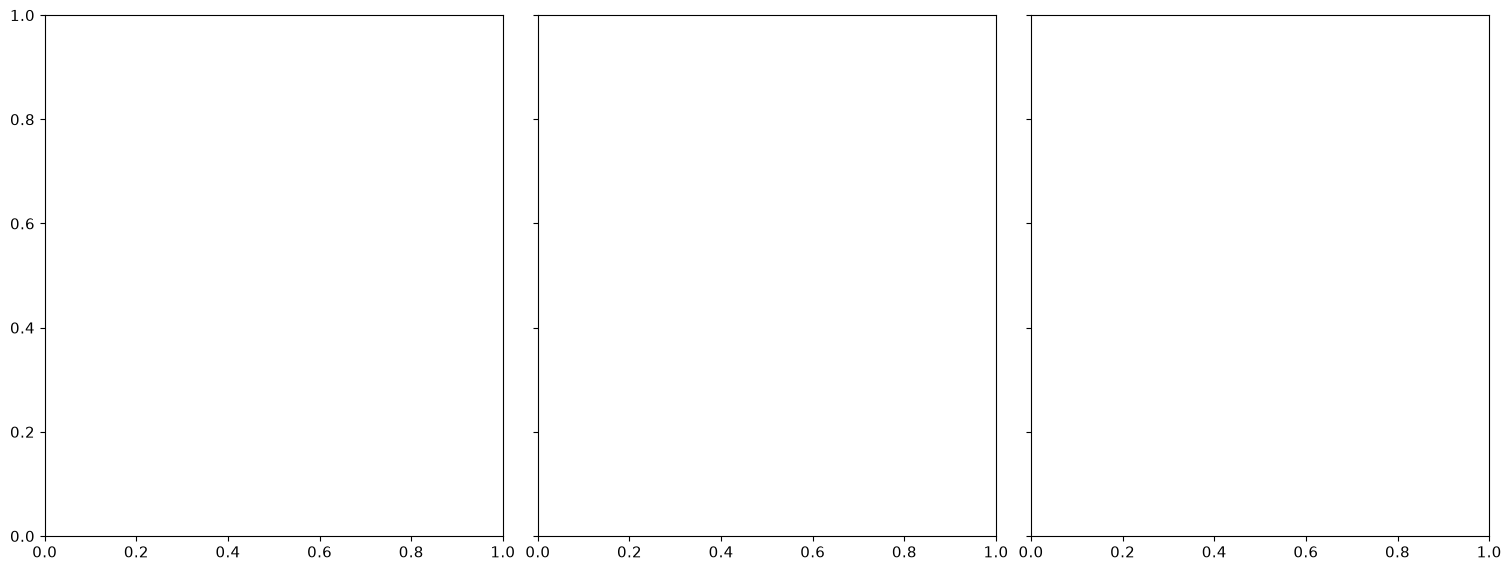

In [8]:
# Does the ensemble know when it is wrong?
#
# For each building the elected tier is argmax_A p_A and its likelihood is
# max_A p_A -- the share of the ensemble that voted for the class actually
# reported. If the uncertainty is informative, that share should be LOWER on the
# buildings whose elected tier turned out to be wrong, even though the tier
# itself carries no hint of it.
#
# Split by event rather than pooled: pooling averages away the one case where
# the property fails, which is the diagnostic result rather than a blemish.
import os
import sys

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HOTSPOT_CSV = f"{PROJECT_ROOT}/out/error_hotspots.csv"
GRAPH_OUTPUT_DIR = "/home/91/23016891/projects/westport-ibw/out/"

LIKELIHOOD_COLUMN = "overall_building_hazard_likelihood"
GROUPS = [(0, "Correct", "#d9d9d9"),
          (1, "Off by 1", "#9ecae1"),
          (2, "Off by 2", "#3182bd")]
PANEL_TITLE = {17: "Event 17 (coastal)\n (rising)",
               57: "Event 57 (coastal)\n (peak)",
               83: "Event 83 (river)\n (recession)"}

likelihood = pd.read_csv(HOTSPOT_CSV, parse_dates=["timestamp"])
likelihood["abs_error"] = likelihood["tier_error"].abs()

panels = list(likelihood.groupby("scenario_id", sort=False))
fig, axes = plt.subplots(1, len(panels), figsize=(5.0 * len(panels), 5.6),
                         sharey=True, constrained_layout=True)

for ax, (scenario_id, sub) in zip(np.atleast_1d(axes), panels):
    series = [sub.loc[sub.abs_error == level, LIKELIHOOD_COLUMN].to_numpy()
              for level, _, _ in GROUPS]

    # Boxes, with the MEAN marked as well as the median. The quantity is
    # bounded and piles up at 1.0, so several medians sit on the top whisker
    # and the box alone would suggest no difference between groups -- the
    # effect lives in the lower tail and in the mean, which is why both the
    # diamond and its value are drawn.
    boxes = ax.boxplot(series, positions=range(len(GROUPS)), widths=0.6,
                       patch_artist=True, showfliers=False, showmeans=False,
                       medianprops=dict(color="#1a1a1a", lw=2.0),
                       whiskerprops=dict(color="#4d4d4d", lw=1.2),
                       capprops=dict(color="#4d4d4d", lw=1.2),
                       meanprops=dict(marker="D", markersize=7,
                                      markerfacecolor="#1a1a1a",
                                      markeredgecolor="#1a1a1a"))
    for patch, (_, _, colour) in zip(boxes["boxes"], GROUPS):
        patch.set_facecolor(colour)
        patch.set_edgecolor("#4d4d4d")
        patch.set_linewidth(1.0)
        patch.set_alpha(0.9)

    for position, values in enumerate(series):
        if not len(values):
            continue
        ax.text(position, 0.305, f"n = {len(values):,}", ha="center",
                fontsize=16, fontweight="bold", color="#333333")
        ax.text(position + 0.34, values.mean(), f"{values.mean():.2f}",
                ha="left", va="center", fontsize=11, fontweight="bold")

    # max_A p_A over three tiers that sum to 1 cannot fall below 1/3, so the
    # axis has a hard floor that is easily misread as "no confidence".
    ax.axhline(1 / 3, ls=":", lw=1.4, color="#8c8c8c")
    # ax.text(len(GROUPS) - 0.5, 1 / 3 + 0.012, "floor = 1/3", ha="right",
    #         va="bottom", fontsize=11, color="#8c8c8c")

    ax.set_xticks(range(len(GROUPS)))
    ax.set_xticklabels([label for _, label, _ in GROUPS], fontsize=12)
    ax.set_ylim(0.26, 1.04)
    # Same construction as the error-map figure, so the two read as a pair:
    # PANEL_TITLE then " - " then the timestamp.
    ax.set_title(f"{PANEL_TITLE[scenario_id]} - {sub['timestamp'].iloc[0]}",
                 fontsize=15, fontweight="bold")
    ax.grid(True, axis="y", alpha=0.3)

np.atleast_1d(axes)[0].set_ylabel(
    "Likelihood of the elected class\n$\\max_A p_A$", fontsize=13)

plt.savefig(os.path.join(GRAPH_OUTPUT_DIR, "likelihood_by_error.png"),
            dpi=150, bbox_inches="tight")
plt.show()

# The claim, stated per event, so a reader can see where it holds.
for scenario_id, sub in panels:
    means = sub.groupby("abs_error")[LIKELIHOOD_COLUMN].mean()
    correct, wrong = means.get(0, np.nan), sub.loc[sub.abs_error > 0, LIKELIHOOD_COLUMN].mean()
    print(f"event {scenario_id}: correct {correct:.3f}  wrong {wrong:.3f}  "
          f"gap {correct - wrong:+.3f}")


In [ ]:
#Goes here
import pandas as pd
import os
PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
error_df = pd.read_csv(os.path.join(PROJECT_ROOT, "out/error_analysis_buildings_buildprop_max.csv"))
error_df.columns


In [ ]:
# The horizon sweep, tabulated: the numbers behind fig_pod_by_event and
# fig_horizon_metrics_overall.
import csv
import io
import os
from pathlib import Path

import pandas as pd

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

horizon_dir = Path(PROJECT_ROOT) / "out" / "horizon"

# Read what the per-event box figure reads, and for the same reason: a rerun
# that fills in events a sweep missed is written beside it as
# horizon_window_metrics_<H>h_missing_events.csv, and the 8 h and 12 h reruns
# were ALSO appended into their sweep file by hand, so those windows now exist
# in two places. Everything matching the prefix is read and deduplicated on the
# window key, which keeps one copy of each. The horizon comes from the column,
# never the filename.
SUPERSEDED = {
    "horizon_window_metrics_backup.csv",  # older 12 h snapshot, superseded
    "horizon_window_metrics_p10.csv",     # different schema, superseded
}
# The sweep streams into the unsuffixed name while it runs, so a file by that
# name is a partial event and would seat an under-sampled row.
STREAMING = {"horizon_window_metrics.csv"}

METRIC_COLUMNS = ["pod", "far", "csi", "risk_level_bias"]
REQUIRED_COLUMNS = {"scenario_id", "issue_time", "forecast_horizon",
                    *METRIC_COLUMNS}

def read_window_metrics(path):
    """Read one sweep CSV, repairing rows a hand-merge left ragged.

    The event reruns were also appended into the 8 h and 12 h sweep files by
    hand, and that append wrote indicators_used unquoted, so every appended row
    splits "h_max_b, h_max_p" into two fields and pandas refuses the whole file
    ("Expected 19 fields, saw 20"). The split is always that column, so rejoin
    it; the 12 h append also carries the header a second time where it starts.
    Anything else ragged is real corruption and is raised, not skipped.
    """
    with open(path, newline="") as handle:
        rows = list(csv.reader(handle))

    header = rows[0]
    indicators = header.index("indicators_used")
    kept, rejoined, repeated_header = [], 0, 0
    for number, row in enumerate(rows[1:], start=2):
        if row == header:
            repeated_header += 1
            continue
        if len(row) == len(header) + 1:
            row = (row[:indicators]
                   + [", ".join(part.strip()
                                for part in row[indicators:indicators + 2])]
                   + row[indicators + 2:])
            rejoined += 1
        if len(row) != len(header):
            raise ValueError(f"{path.name} line {number}: expected "
                             f"{len(header)} fields, saw {len(row)}")
        kept.append(row)

    if rejoined or repeated_header:
        print(f"  {path.name}: rejoined {rejoined} unquoted indicators_used "
              f"field(s), dropped {repeated_header} repeated header row(s)")

    buffer = io.StringIO()
    writer = csv.writer(buffer)
    writer.writerow(header)
    writer.writerows(kept)
    buffer.seek(0)
    return pd.read_csv(buffer)


horizon_metric_paths = [
    path for path in sorted(horizon_dir.glob("horizon_window_metrics*.csv"))
    if path.name not in SUPERSEDED | STREAMING
]
if not horizon_metric_paths:
    raise FileNotFoundError(f"No horizon metric CSVs found in {horizon_dir}")

frames = []
for path in horizon_metric_paths:
    frame = read_window_metrics(path)
    absent = REQUIRED_COLUMNS.difference(frame.columns)
    if absent:
        raise ValueError(f"{path.name} is missing columns: {sorted(absent)}")
    frames.append(frame)

horizon_metrics = (
    pd.concat(frames, ignore_index=True)
    .drop_duplicates(["forecast_horizon", "scenario_id", "issue_time"], keep="first")
    .reset_index(drop=True)
)

# A horizon that is short of an event makes a table row vanish rather than look
# wrong, so name the gap instead of letting the table run quietly short.
events = sorted(horizon_metrics["scenario_id"].unique())
covered = horizon_metrics.groupby("forecast_horizon")["scenario_id"].nunique()
print(f"{len(horizon_metrics)} windows over {len(events)} events, "
      f"horizons {list(covered.index)}")
for horizon, count in covered.items():
    if count < len(events):
        missing = sorted(set(events).difference(
            horizon_metrics.loc[horizon_metrics["forecast_horizon"] == horizon,
                                "scenario_id"]))
        print(f"  {horizon} h covers {count}/{len(events)} events, missing {missing}")

# For each horizon and event, the mean metric and sample standard deviation
# across that event's forecast windows; n is how many windows back the row.
event_metric_summary = (
    horizon_metrics
    .groupby(["forecast_horizon", "scenario_id"])
    .agg(n=("pod", "size"),
         **{f"{metric}_{stat}": (metric, stat)
            for metric in METRIC_COLUMNS for stat in ("mean", "std")})
    .rename_axis(index=["forecast_horizon", "event"])
    .round(3)
)
event_metric_summary.columns = pd.MultiIndex.from_tuples(
    [("n", "")] + [(metric, stat)
                   for metric in METRIC_COLUMNS for stat in ("mean", "std")])

display(event_metric_summary)

# fig_pod_by_event as a table: events down, forecast windows across, each cell
# the mean POD over that event's windows with its spread and window count. An
# event a horizon never ran reads "not run", matching the shaded panel slot.
pod_cells = (
    event_metric_summary[[("pod", "mean"), ("pod", "std"), ("n", "")]]
    .set_axis(["mean", "std", "n"], axis=1)
    .apply(lambda row: f"{row['mean']:.3f} ± {row['std']:.3f} ({int(row['n'])})",
           axis=1)
)
pod_by_event = (
    pod_cells.unstack("forecast_horizon")
    .reindex(index=events)
    .rename_axis(index="event", columns="forecast window (h)")
    .fillna("not run")
)

display(pod_by_event)

# The window distributions are one-sided -- POD piles against 1.0 with a thin
# low tail -- so a mean and sd describe them poorly. Report each horizon by its
# quantiles as well: the median, the quartiles, and the central 95% of its
# windows (p2.5 to p97.5), with p95 alongside as the one-sided reading.
QUANTILES = [0.025, 0.05, 0.1, 0.25, 0.5, 0.75, 0.95, 0.975]

windows_long = horizon_metrics.melt(
    id_vars=["forecast_horizon", "scenario_id"], value_vars=METRIC_COLUMNS,
    var_name="metric", value_name="value")
# melt orders the metrics alphabetically; keep them in reporting order.
windows_long["metric"] = pd.Categorical(
    windows_long["metric"], categories=METRIC_COLUMNS, ordered=True)

grouped = windows_long.groupby(["forecast_horizon", "metric"], observed=True)["value"]
horizon_quantiles = grouped.quantile(QUANTILES).unstack()
horizon_quantiles.columns = [f"p{quantile * 100:g}" for quantile in QUANTILES]
horizon_quantiles.insert(0, "n", grouped.size())
horizon_quantiles = horizon_quantiles.round(3)

display(horizon_quantiles)

# Median per event and horizon -- the centre line of each box in
# fig_pod_by_event -- then POD alone, laid out like the figure.
event_medians = (
    horizon_metrics
    .groupby(["forecast_horizon", "scenario_id"])[METRIC_COLUMNS]
    .median()
    .rename_axis(index=["forecast_horizon", "event"])
    .round(3)
)
pod_median_by_event = (
    event_medians["pod"]
    .unstack("forecast_horizon")
    .reindex(index=events)
    .rename_axis(index="event", columns="forecast window (h)")
)
# One number per event, over every window at every horizon, for the events that
# are quoted in the text rather than read off a panel.
pooled_event_medians = (
    horizon_metrics
    .groupby("scenario_id")[METRIC_COLUMNS]
    .median()
    .rename_axis(index="event")
    .round(3)
)

display(event_medians)
display(pod_median_by_event)
display(pooled_event_medians)



#Overall summary

# sample standard deviation across its forecast windows.
overall_summary = (
    horizon_metrics[METRIC_COLUMNS]
    .agg(["mean", "std"])
    .rename_axis(index="event")
    .round(3)
)

display(overall_summary)


# Overall performance by forecast horizon, aggregated across every real
# forecast window in each horizon CSV.
import matplotlib.pyplot as plt
import pandas as pd

horizon_summary = (
    horizon_metrics
    .groupby("forecast_horizon")[METRIC_COLUMNS]
    .agg(["mean", "std"])
    .sort_index()
)
display(horizon_summary.round(3))

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

SCORE_COLOR = "#4292c6"
INK = "#1a1a1a"
GRID = "#d9d9d9"
panel_settings = {
    "pod": ("(a) Probability of detection", "POD", "higher is better"),
    "far": ("(b) False alarm ratio", "FAR", "lower is better"),
    "csi": ("(c) Critical success index", "CSI", "higher is better"),
    "risk_level_bias": (
        "(d) Signed risk-tier bias",
        "Forecast tier − observed tier",
        "zero is unbiased",
    ),
}

x = horizon_summary.index
fig, axes = plt.subplots(1, 4, figsize=(16, 4.8), sharex=True)
fig.subplots_adjust(left=0.065, right=0.99, top=0.76, bottom=0.20, wspace=0.28)

for ax, (metric, (title, ylabel, cue)) in zip(axes, panel_settings.items()):
    y = horizon_summary[(metric, "mean")]
    ax.plot(
        x, y, color=SCORE_COLOR, linewidth=2.2, marker="o", markersize=7.5,
        markeredgecolor="white", markeredgewidth=0.9, zorder=3,
    )
    ax.set_title(title, loc="left", fontweight="bold", color=INK, pad=22)
    ax.text(0, 1.035, cue, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=10.5, color="0.40")
    ax.set_xlabel("Forecast window (h)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    if metric == "risk_level_bias":
        extent = max(abs(y.min()), abs(y.max())) * 1.25
        ax.set_ylim(-extent, extent)
        ax.axhline(0, color="0.35", linestyle="--", linewidth=1.2, zorder=1)
    else:
        padding = max((y.max() - y.min()) * 0.22, 0.015)
        ax.set_ylim(max(0, y.min() - padding), min(1, y.max() + padding))

fig.suptitle("Overall performance by forecast window", x=0.065, ha="left",
             fontsize=18, fontweight="bold", color=INK)
figure_stem = os.path.join(
    PROJECT_ROOT, "out", "horizon", "fig_horizon_metrics_overall"
)
for extension in ("png", "pdf"):
    fig.savefig(f"{figure_stem}.{extension}", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# Forecast skill against forecast window, as a distribution over EVENTS rather
# than a single mean line.
#
# One box per horizon per metric, built from the 12 flood scenarios: each event
# is first collapsed to its own mean over that event's forecast windows, so an
# event with 49 windows and one with 27 count equally. Twelve points is a small
# sample and a box alone would hide that, so every event is drawn on top of its
# box.
#
# PLOT ONLY -- reads out/horizon/horizon_window_metrics_*h.csv.
import csv
import io
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

horizon_dir = Path(PROJECT_ROOT) / "out" / "horizon"

# The same read as the per-event and tabulated cells. A rerun that fills in
# events a sweep missed is written beside it as
# horizon_window_metrics_<H>h_missing_events.csv, so a glob of *_<H>h.csv alone
# silently drops those events -- which is what left the 8 h box on 10 events and
# the 12 h box on 11 while 1 h and 4 h had all 12. Everything matching the
# prefix is read and deduplicated on the window key.
SUPERSEDED = {
    "horizon_window_metrics_backup.csv",  # older 12 h snapshot, superseded
    "horizon_window_metrics_p10.csv",     # different schema, superseded
}
STREAMING = {"horizon_window_metrics.csv"}


def read_window_metrics(path):
    """Read one sweep CSV, repairing rows a hand-merge left ragged.

    A guard rather than a repair in daily use: the 8 h and 12 h files have been
    rewritten with their quoting restored. It rejoins an unquoted
    indicators_used, drops a header row appended a second time, and raises on
    anything else ragged rather than skipping it.
    """
    with open(path, newline="") as handle:
        rows = list(csv.reader(handle))

    header = rows[0]
    indicators = header.index("indicators_used")
    kept = []
    for number, row in enumerate(rows[1:], start=2):
        if row == header:
            continue
        if len(row) == len(header) + 1:
            row = (row[:indicators]
                   + [", ".join(part.strip()
                                for part in row[indicators:indicators + 2])]
                   + row[indicators + 2:])
        if len(row) != len(header):
            raise ValueError(f"{path.name} line {number}: expected "
                             f"{len(header)} fields, saw {len(row)}")
        kept.append(row)

    buffer = io.StringIO()
    writer = csv.writer(buffer)
    writer.writerow(header)
    writer.writerows(kept)
    buffer.seek(0)
    return pd.read_csv(buffer)


horizon_metric_paths = [
    path for path in sorted(horizon_dir.glob("horizon_window_metrics*.csv"))
    if path.name not in SUPERSEDED | STREAMING
]
if not horizon_metric_paths:
    raise FileNotFoundError(f"No horizon metric CSVs found in {horizon_dir}")

horizon_metrics = (
    pd.concat([read_window_metrics(path) for path in horizon_metric_paths],
              ignore_index=True)
    .drop_duplicates(["forecast_horizon", "scenario_id", "issue_time"], keep="first")
    .reset_index(drop=True)
)

metric_columns = ["pod", "far", "csi", "risk_level_bias"]

# Every horizon now carries all 12 events, the reruns included, so the four
# boxes already rest on the same scenarios and this flag is a no-op kept for the
# case where a future sweep is again short of an event: True restricts every box
# to the events common to all horizons, so a horizon-to-horizon step cannot
# reflect WHICH events are present.
BALANCED_PANEL = False

# One value per (horizon, event): the event's mean over its forecast windows.
# This is the unit the boxes are built from -- the spread below is between
# events, not between windows.
event_metrics = (
    horizon_metrics
    .groupby(["forecast_horizon", "scenario_id"])[metric_columns]
    .mean()
    .reset_index()
)

if BALANCED_PANEL:
    common_events = set.intersection(*(
        set(group["scenario_id"])
        for _, group in event_metrics.groupby("forecast_horizon")
    ))
    event_metrics = event_metrics[event_metrics["scenario_id"].isin(common_events)]

horizons = sorted(event_metrics["forecast_horizon"].unique())
events = sorted(event_metrics["scenario_id"].unique())

# Counted here and printed under each box: with n in the low tens, the reader
# needs to see how thin each distribution is.
counts = {h: int((event_metrics["forecast_horizon"] == h).sum()) for h in horizons}
print("events per horizon:", counts)
missing = {
    h: sorted(set(events) - set(
        event_metrics.loc[event_metrics["forecast_horizon"] == h, "scenario_id"]))
    for h in horizons
}
print("events absent per horizon:", {h: v for h, v in missing.items() if v})

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

INK = "#1a1a1a"
GRID = "#d9d9d9"
BOX_FACE = "#deebf7"
BOX_EDGE = "#4292c6"
MEDIAN = "#08519c"
WHISKER = "0.45"
POINT = "#2171b5"

panel_settings = {
    "pod": ("(a) Probability of detection", "POD", "higher is better"),
    "far": ("(b) False alarm ratio", "FAR", "lower is better"),
    "csi": ("(c) Critical success index", "CSI", "higher is better"),
    "risk_level_bias": (
        "(d) Signed risk-tier bias",
        "Forecast tier − observed tier",
        "zero is unbiased",
    ),
}

# One horizontal offset per EVENT, fixed across every panel and every horizon,
# so a reader can follow the same scenario from box to box. Jittered rather
# than evenly spaced: a regular ladder of dots reads as an encoding of rank,
# which it is not.
rng = np.random.default_rng(7)
jitter = dict(zip(events, rng.uniform(-0.19, 0.19, size=len(events))))

positions = np.arange(1, len(horizons) + 1)

fig, axes = plt.subplots(1, 4, figsize=(16, 5.2), sharex=True)
fig.subplots_adjust(left=0.065, right=0.99, top=0.76, bottom=0.22, wspace=0.28)

for ax, (metric, (title, ylabel, cue)) in zip(axes, panel_settings.items()):
    groups = [
        event_metrics.loc[event_metrics["forecast_horizon"] == h, metric].to_numpy()
        for h in horizons
    ]

    # Fliers off: every event is already drawn as a point, so matplotlib's
    # outlier markers would double-plot the extremes.
    ax.boxplot(
        groups, positions=positions, widths=0.55, showfliers=False,
        patch_artist=True,
        boxprops=dict(facecolor=BOX_FACE, edgecolor=BOX_EDGE, linewidth=1.2),
        medianprops=dict(color=MEDIAN, linewidth=2.0),
        whiskerprops=dict(color=WHISKER, linewidth=1.1),
        capprops=dict(color=WHISKER, linewidth=1.1),
        zorder=2,
    )

    for position, horizon in zip(positions, horizons):
        rows = event_metrics[event_metrics["forecast_horizon"] == horizon]
        ax.scatter(
            position + rows["scenario_id"].map(jitter), rows[metric],
            s=26, color=POINT, alpha=0.55, linewidths=0.6,
            edgecolors="white", zorder=3,
        )

    ax.set_title(title, loc="left", fontweight="bold", color=INK, pad=22)
    ax.text(0, 1.035, cue, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=10.5, color="0.40")
    ax.set_xlabel("Forecast window (h)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(positions)
    ax.set_xticklabels([f"{h}\n$n$={counts[h]}" for h in horizons])
    ax.set_xlim(positions[0] - 0.6, positions[-1] + 0.6)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    values = np.concatenate(groups)
    if metric == "risk_level_bias":
        extent = max(abs(values.min()), abs(values.max())) * 1.18
        ax.set_ylim(-extent, extent)
        ax.axhline(0, color="0.35", linestyle="--", linewidth=1.2, zorder=1)
    else:
        padding = max((values.max() - values.min()) * 0.10, 0.015)
        ax.set_ylim(max(0, values.min() - padding), min(1, values.max() + padding))

suptitle = "Performance by forecast window, across flood scenarios"
if BALANCED_PANEL:
    suptitle += f" ({len(events)} events common to all horizons)"
fig.suptitle(suptitle,
             x=0.065, ha="left", fontsize=18, fontweight="bold", color=INK)
fig.text(0.065, 0.035,
         "Box: median and interquartile range over events; whiskers 1.5×IQR. "
         "Each point is one event, at its mean over that event's forecast windows.",
         ha="left", fontsize=10.5, color="0.40")

figure_stem = os.path.join(
    PROJECT_ROOT, "out", "horizon",
    "fig_horizon_metrics_box_balanced" if BALANCED_PANEL else "fig_horizon_metrics_box",
)
for extension in ("png", "pdf"):
    fig.savefig(f"{figure_stem}.{extension}", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# Probability of detection per EVENT, one panel per forecast window.
#
# The unit inside a box is a forecast window: every issue of that event at that
# horizon. So a box is the spread of POD over the event's timesteps, and the
# panel-to-panel comparison asks whether stretching the window degrades
# detection within the same event.
#
# Each panel carries a broken y axis. POD piles up against 1.0 -- a fifth of all
# windows sit exactly there -- while a thin tail reaches 0.574, and on one
# linear axis the tail costs more than half the panel height to show 27 windows
# out of 1682. The break gives the dense region most of the height and keeps the
# tail on the page, so nothing is clipped and no value needs an out-of-range
# mark. No box straddles the break: every lower quartile sits above it, so only
# whiskers and outliers cross.
#
# PLOT ONLY -- reads out/horizon/horizon_window_metrics_*h.csv.
import csv
import io
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

horizon_dir = Path(PROJECT_ROOT) / "out" / "horizon"

# The per-horizon sweeps are the canonical results, and a rerun that fills in
# events a sweep missed is written beside it as
# horizon_window_metrics_<H>h_missing_events.csv. The 8 h and 12 h reruns were
# ALSO appended into their sweep file by hand, so those windows now exist in two
# places: everything matching the prefix is read and deduplicated on the window
# key, which keeps one copy of each. The horizon comes from the column, never
# from the filename.
SUPERSEDED = {
    "horizon_window_metrics_backup.csv",  # older 12 h snapshot, superseded
    "horizon_window_metrics_p10.csv",     # different schema, superseded
}
# The sweep streams into the unsuffixed name while it runs, so a file by that
# name is a partial event and would seat an under-sampled box in its panel.
# Rename it to ..._<H>h_missing_events.csv once the run finishes.
STREAMING = {"horizon_window_metrics.csv"}

REQUIRED_COLUMNS = {"scenario_id", "issue_time", "forecast_horizon",
                    "pod", "far", "csi", "risk_level_bias"}

def read_window_metrics(path):
    """Read one sweep CSV, repairing rows a hand-merge left ragged.

    The event reruns were also appended into the 8 h and 12 h sweep files by
    hand, and that append wrote indicators_used unquoted, so every appended row
    splits "h_max_b, h_max_p" into two fields and pandas refuses the whole file
    ("Expected 19 fields, saw 20"). The split is always that column, so rejoin
    it; the 12 h append also carries the header a second time where it starts.
    Anything else ragged is real corruption and is raised, not skipped.
    """
    with open(path, newline="") as handle:
        rows = list(csv.reader(handle))

    header = rows[0]
    indicators = header.index("indicators_used")
    kept, rejoined, repeated_header = [], 0, 0
    for number, row in enumerate(rows[1:], start=2):
        if row == header:
            repeated_header += 1
            continue
        if len(row) == len(header) + 1:
            row = (row[:indicators]
                   + [", ".join(part.strip()
                                for part in row[indicators:indicators + 2])]
                   + row[indicators + 2:])
            rejoined += 1
        if len(row) != len(header):
            raise ValueError(f"{path.name} line {number}: expected "
                             f"{len(header)} fields, saw {len(row)}")
        kept.append(row)

    if rejoined or repeated_header:
        print(f"  {path.name}: rejoined {rejoined} unquoted indicators_used "
              f"field(s), dropped {repeated_header} repeated header row(s)")

    buffer = io.StringIO()
    writer = csv.writer(buffer)
    writer.writerow(header)
    writer.writerows(kept)
    buffer.seek(0)
    return pd.read_csv(buffer)


horizon_metric_paths = [
    path for path in sorted(horizon_dir.glob("horizon_window_metrics*.csv"))
    if path.name not in SUPERSEDED | STREAMING
]
if not horizon_metric_paths:
    raise FileNotFoundError(f"No horizon metric CSVs found in {horizon_dir}")

frames = []
for path in horizon_metric_paths:
    frame = read_window_metrics(path)
    absent = REQUIRED_COLUMNS.difference(frame.columns)
    if absent:
        raise ValueError(f"{path.name} is missing columns: {sorted(absent)}")
    frames.append(frame)

horizon_metrics = (
    pd.concat(frames, ignore_index=True)
    .drop_duplicates(["forecast_horizon", "scenario_id", "issue_time"], keep="first")
    .reset_index(drop=True)
)

horizons = sorted(horizon_metrics["forecast_horizon"].unique())
events = sorted(horizon_metrics["scenario_id"].unique())

# Publication style, as used for the damage violin/box figure: Arial metrics,
# black-outlined boxes, recessive y-grid. Arial is not installed on this box, so
# the stack falls through to Liberation Sans, which is metrically identical.
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"],
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 17,
    "ytick.labelsize": 13,
    "axes.linewidth": 1.2,
})

# Solid rather than a translucent #6B9ECF: this is that colour already
# composited onto white, so the tone is unchanged, but the grid no longer shows
# through the fill and the box edge reads as one clean line.
BOX_COLOR = "#BCD3E9"
BOX_EDGE = "#1a1a1a"

BREAK = 0.80
TOP_RANGE = (BREAK, 1.006)
BOTTOM_RANGE = (0.55, BREAK)
PANEL_LABELS = ["(a)", "(b)", "(c)", "(d)"]

BOX_STYLE = dict(
    widths=0.72, showfliers=True, patch_artist=True,
    boxprops=dict(facecolor=BOX_COLOR, edgecolor=BOX_EDGE, linewidth=1.4),
    medianprops=dict(color=BOX_EDGE, linewidth=2.8, solid_capstyle="butt"),
    whiskerprops=dict(color=BOX_EDGE, linewidth=1.3),
    capprops=dict(color=BOX_EDGE, linewidth=1.6),
    flierprops=dict(marker="o", markersize=4.6, markerfacecolor="none",
                    markeredgecolor="0.25", markeredgewidth=0.9),
    zorder=3,
)

fig = plt.figure(figsize=(15, 9.4))
outer = fig.add_gridspec(2, 2, left=0.075, right=0.985, top=0.945, bottom=0.205,
                         hspace=0.38, wspace=0.07)

positions = np.arange(1, len(events) + 1)

for panel_index, horizon in enumerate(horizons):
    inner = outer[divmod(panel_index, 2)].subgridspec(
        2, 1, height_ratios=[3.7, 1.0], hspace=0.06)
    ax_top = fig.add_subplot(inner[0])
    ax_bottom = fig.add_subplot(inner[1], sharex=ax_top)

    panel = horizon_metrics[horizon_metrics["forecast_horizon"] == horizon]

    groups, drawn_positions, tick_labels, count_labels, absent = [], [], [], [], []
    for position, event in zip(positions, events):
        values = panel.loc[panel["scenario_id"] == event, "pod"].to_numpy()
        if values.size:
            groups.append(values)
            drawn_positions.append(position)
            tick_labels.append(str(event))
            count_labels.append(f"$n$={values.size}")
        else:
            absent.append(position)
            tick_labels.append(str(event))
            count_labels.append("–")

    ax_top.axhline(1.0, color="0.55", linestyle=(0, (1, 3)), linewidth=1.0,
                   zorder=1)

    # The same boxes are drawn on both axes; each shows only the slice its own
    # y limits admit, which is what makes a whisker continue across the break.
    for ax in (ax_top, ax_bottom):
        ax.boxplot(groups, positions=drawn_positions, **BOX_STYLE)

        # The 8 h and 12 h sweeps did not cover every event; the slot is kept so
        # the four panels stay in register, and labelled so it cannot read as a
        # zero.
        for position in absent:
            ax.axvspan(position - 0.42, position + 0.42, color="0.94", zorder=0)

        ax.grid(axis="y", color="0.9", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines["right"].set_visible(False)

    for position in absent:
        ax_top.text(position, (BREAK + 1.0) / 2, "not run", rotation=90,
                    ha="center", va="center", fontsize=11, color="0.45",
                    style="italic")

    ax_top.set_ylim(*TOP_RANGE)
    ax_top.set_yticks(np.arange(0.80, 1.001, 0.05))
    ax_top.spines["top"].set_visible(False)
    ax_top.spines["bottom"].set_visible(False)
    ax_top.tick_params(axis="x", which="both", bottom=False, labelbottom=False)

    ax_bottom.set_ylim(*BOTTOM_RANGE)
    ax_bottom.set_yticks([0.6, 0.7])
    ax_bottom.spines["top"].set_visible(False)
    ax_bottom.set_xlim(positions[0] - 0.7, positions[-1] + 0.7)
    ax_bottom.set_xticks(positions)
    ax_bottom.set_xticklabels(tick_labels)
    ax_bottom.tick_params(axis="x", pad=6)

    count_transform = ax_bottom.get_xaxis_transform()
    for position, count_label in zip(positions, count_labels):
        ax_bottom.annotate(
            count_label, xy=(position, 0), xycoords=count_transform,
            xytext=(0, -32), textcoords="offset points",
            ha="center", va="top", fontsize=12.5, color="0.25",
            annotation_clip=False,
        )

    # Break marks on the left spine only -- the right spine is hidden, so a pair
    # there would float unattached.
    break_marks = dict(marker=[(-1, -0.5), (1, 0.5)], markersize=11,
                       linestyle="none", color="black", markeredgecolor="black",
                       markeredgewidth=1.2, clip_on=False)
    ax_top.plot([0], [0], transform=ax_top.transAxes, **break_marks)
    ax_bottom.plot([0], [1], transform=ax_bottom.transAxes, **break_marks)

    ax_top.set_title(f"{PANEL_LABELS[panel_index]} {horizon} h forecast window",
                     loc="center", pad=12)
    if panel_index % 2 == 0:
        ax_top.set_ylabel("POD$_t$", labelpad=10)
        ax_top.yaxis.set_label_coords(-0.075, 0.36)
    if panel_index >= 2:
        ax_bottom.set_xlabel("event", labelpad=34)

figure_stem = os.path.join(PROJECT_ROOT, "out", "horizon", "fig_pod_by_event")
fig.savefig(f"{figure_stem}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(f"{figure_stem}.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Probability of detection per EVENT, one panel per forecast window -- the same
# figure as fig_pod_by_event, drawn on ONE continuous axis instead of a broken
# one.
#
# The broken-axis version gives the dense region above 0.80 most of the panel
# height; this one pays the full cost of the tail so the vertical distance
# between two boxes can be read directly. Only 27 of 1780 windows sit below
# 0.80 and 5 below 0.60, so most of the lower half of each panel is empty --
# which is itself the point of showing it: the boxes really are that far up.
# Keep both, and cite whichever the surrounding text argues from.
#
# The axis floor comes from the data, rounded down to the next 0.05, so a
# future rerun with a deeper tail cannot clip a whisker off the page.
#
# PLOT ONLY -- reads out/horizon/horizon_window_metrics*.csv.
import csv
import io
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

horizon_dir = Path(PROJECT_ROOT) / "out" / "horizon"

# The per-horizon sweeps are the canonical results, and a rerun that fills in
# events a sweep missed is written beside it as
# horizon_window_metrics_<H>h_missing_events.csv. The 8 h and 12 h reruns were
# ALSO appended into their sweep file by hand, so those windows now exist in two
# places: everything matching the prefix is read and deduplicated on the window
# key, which keeps one copy of each. The horizon comes from the column, never
# from the filename.
SUPERSEDED = {
    "horizon_window_metrics_backup.csv",  # older 12 h snapshot, superseded
    "horizon_window_metrics_p10.csv",     # different schema, superseded
}
# The sweep streams into the unsuffixed name while it runs, so a file by that
# name is a partial event and would seat an under-sampled box in its panel.
# Rename it to ..._<H>h_missing_events.csv once the run finishes.
STREAMING = {"horizon_window_metrics.csv"}

REQUIRED_COLUMNS = {"scenario_id", "issue_time", "forecast_horizon",
                    "pod", "far", "csi", "risk_level_bias"}


def read_window_metrics(path):
    """Read one sweep CSV, repairing rows a hand-merge left ragged.

    The event reruns were appended into the 8 h and 12 h sweep files by hand,
    and that append wrote indicators_used unquoted, so its rows split
    "h_max_b, h_max_p" into two fields and pandas refused the whole file. Those
    two files have since been rewritten with the quoting restored, so this is a
    guard rather than a repair in daily use: it rejoins that column, drops a
    header row appended a second time, and raises on anything else ragged
    rather than skipping it.
    """
    with open(path, newline="") as handle:
        rows = list(csv.reader(handle))

    header = rows[0]
    indicators = header.index("indicators_used")
    kept, rejoined, repeated_header = [], 0, 0
    for number, row in enumerate(rows[1:], start=2):
        if row == header:
            repeated_header += 1
            continue
        if len(row) == len(header) + 1:
            row = (row[:indicators]
                   + [", ".join(part.strip()
                                for part in row[indicators:indicators + 2])]
                   + row[indicators + 2:])
            rejoined += 1
        if len(row) != len(header):
            raise ValueError(f"{path.name} line {number}: expected "
                             f"{len(header)} fields, saw {len(row)}")
        kept.append(row)

    if rejoined or repeated_header:
        print(f"  {path.name}: rejoined {rejoined} unquoted indicators_used "
              f"field(s), dropped {repeated_header} repeated header row(s)")

    buffer = io.StringIO()
    writer = csv.writer(buffer)
    writer.writerow(header)
    writer.writerows(kept)
    buffer.seek(0)
    return pd.read_csv(buffer)


horizon_metric_paths = [
    path for path in sorted(horizon_dir.glob("horizon_window_metrics*.csv"))
    if path.name not in SUPERSEDED | STREAMING
]
if not horizon_metric_paths:
    raise FileNotFoundError(f"No horizon metric CSVs found in {horizon_dir}")

frames = []
for path in horizon_metric_paths:
    frame = read_window_metrics(path)
    absent = REQUIRED_COLUMNS.difference(frame.columns)
    if absent:
        raise ValueError(f"{path.name} is missing columns: {sorted(absent)}")
    frames.append(frame)

horizon_metrics = (
    pd.concat(frames, ignore_index=True)
    .drop_duplicates(["forecast_horizon", "scenario_id", "issue_time"], keep="first")
    .reset_index(drop=True)
)

horizons = sorted(horizon_metrics["forecast_horizon"].unique())
events = sorted(horizon_metrics["scenario_id"].unique())

# Publication style, as used for the damage violin/box figure: Arial metrics,
# black-outlined boxes, recessive y-grid. Arial is not installed on this box, so
# the stack falls through to Liberation Sans, which is metrically identical.
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"],
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 17,
    "ytick.labelsize": 13,
    "axes.linewidth": 1.2,
})

# Solid rather than a translucent #6B9ECF: this is that colour already
# composited onto white, so the tone is unchanged, but the grid no longer shows
# through the fill and the box edge reads as one clean line.
BOX_COLOR = "#BCD3E9"
BOX_EDGE = "#1a1a1a"

FLOOR = np.floor(horizon_metrics["pod"].min() / 0.05) * 0.05
CEILING = 1.006
PANEL_LABELS = ["(a)", "(b)", "(c)", "(d)"]

BOX_STYLE = dict(
    widths=0.72, showfliers=True, patch_artist=True,
    boxprops=dict(facecolor=BOX_COLOR, edgecolor=BOX_EDGE, linewidth=1.4),
    medianprops=dict(color=BOX_EDGE, linewidth=2.8, solid_capstyle="butt"),
    whiskerprops=dict(color=BOX_EDGE, linewidth=1.3),
    capprops=dict(color=BOX_EDGE, linewidth=1.6),
    flierprops=dict(marker="o", markersize=4.6, markerfacecolor="none",
                    markeredgecolor="0.25", markeredgewidth=0.9),
    zorder=3,
)

fig, axes = plt.subplots(2, 2, figsize=(15, 9.4))
fig.subplots_adjust(left=0.075, right=0.985, top=0.945, bottom=0.205,
                    hspace=0.42, wspace=0.07)

positions = np.arange(1, len(events) + 1)

for panel_index, (horizon, ax) in enumerate(zip(horizons, axes.flat)):
    panel = horizon_metrics[horizon_metrics["forecast_horizon"] == horizon]

    groups, drawn_positions, tick_labels, count_labels, absent = [], [], [], [], []
    for position, event in zip(positions, events):
        values = panel.loc[panel["scenario_id"] == event, "pod"].to_numpy()
        if values.size:
            groups.append(values)
            drawn_positions.append(position)
            tick_labels.append(str(event))
            count_labels.append(f"$n$={values.size}")
        else:
            absent.append(position)
            tick_labels.append(str(event))
            count_labels.append("–")

    ax.axhline(1.0, color="0.55", linestyle=(0, (1, 3)), linewidth=1.0, zorder=1)
    ax.boxplot(groups, positions=drawn_positions, **BOX_STYLE)

    # A horizon that never ran an event keeps its slot so the four panels stay
    # in register, and is labelled so it cannot read as a zero.
    for position in absent:
        ax.axvspan(position - 0.42, position + 0.42, color="0.94", zorder=0)
        ax.text(position, (FLOOR + CEILING) / 2, "not run", rotation=90,
                ha="center", va="center", fontsize=11, color="0.45",
                style="italic")

    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    ax.set_ylim(FLOOR, CEILING)
    ax.set_yticks(np.arange(FLOOR, 1.001, 0.05))
    ax.set_xlim(positions[0] - 0.7, positions[-1] + 0.7)
    ax.set_xticks(positions)
    ax.set_xticklabels(tick_labels)
    ax.tick_params(axis="x", pad=6)

    count_transform = ax.get_xaxis_transform()
    for position, count_label in zip(positions, count_labels):
        ax.annotate(
            count_label, xy=(position, 0), xycoords=count_transform,
            xytext=(0, -32), textcoords="offset points",
            ha="center", va="top", fontsize=12.5, color="0.25",
            annotation_clip=False,
        )

    ax.set_title(f"{PANEL_LABELS[panel_index]} {horizon} h forecast window",
                 loc="center", pad=12)
    if panel_index % 2 == 0:
        ax.set_ylabel("POD$_t$", labelpad=10)
    if panel_index >= 2:
        ax.set_xlabel("event", labelpad=34)

figure_stem = os.path.join(PROJECT_ROOT, "out", "horizon",
                           "fig_pod_by_event_fullrange")
fig.savefig(f"{figure_stem}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(f"{figure_stem}.png", dpi=300, bbox_inches="tight")
plt.show()


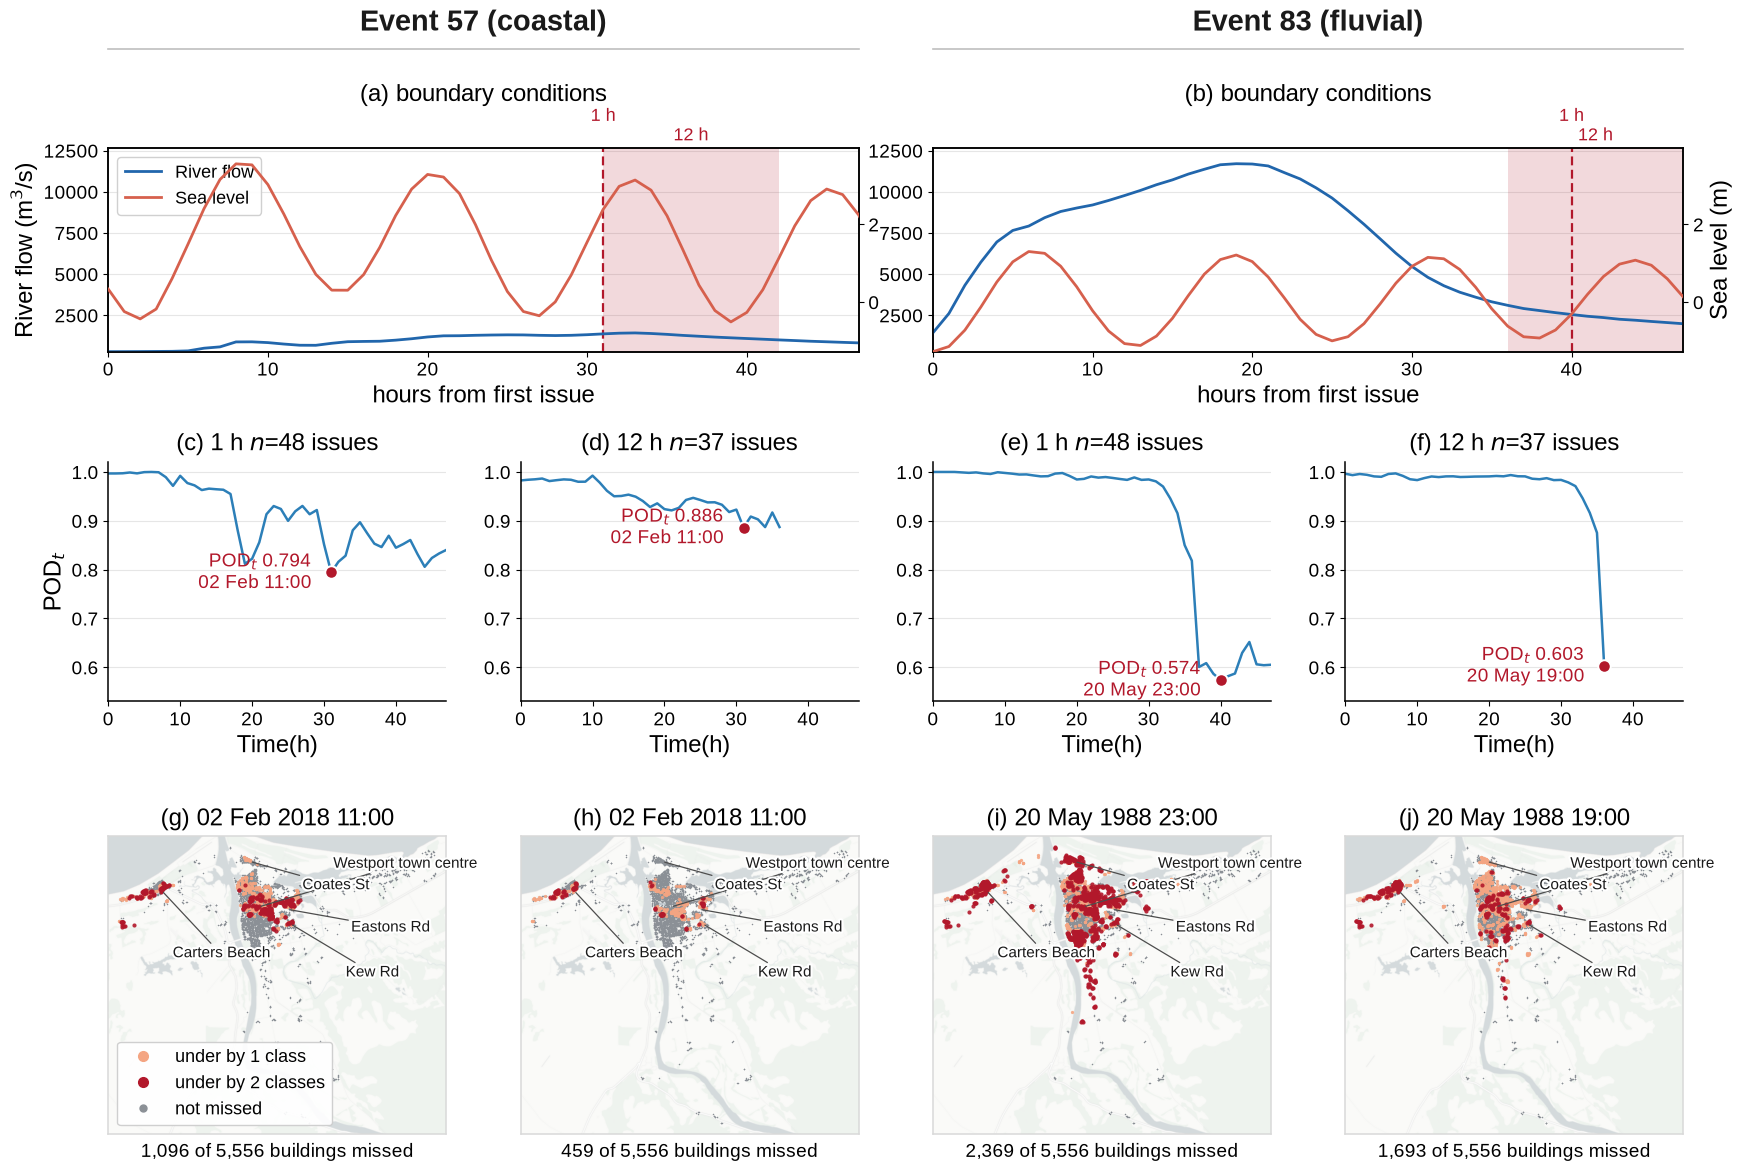

In [25]:
# Events 57 and 83 in close-up: what the forecast window does to detection, in
# time and in space.
#
# Columns are (event, forecast window): 57 at 1 h and 12 h, then 83 at the same
# two. Both events sit at the low end of the POD distribution and they fail
# differently, which is why they are the pair.
#
# Row 1 -- the forcing: river flow and sea level over the event. One panel per
# EVENT, spanning its two columns, because the boundary conditions are a
# property of the event and not of the window scored against it. The shaded
# bands are the worst windows marked below, so the failure can be read against
# the phase of the hydrograph it happens in.
#
# Row 2 -- POD of every issue of that event at that window. The unit is a
# forecast window, so the series is the event's whole run of issues and the
# marked point is the worst of them. Both columns of an event share the x axis
# of row 1, so a 12 h series simply ends earlier: the longer window cannot be
# issued as late in the event.
#
# Row 3 -- the buildings that window MISSED: forecast class below the class the
# simulated maps reach anywhere in the window. Same max-over-window collapse the
# metrics score, so the count under each map is the n_miss behind the marked
# point above it. Misses are split by how far they fell short, since a building
# called H1 when the water reaches H3+ is not the same failure as one called H2.
#
# PLOT ONLY -- reads the event boundary conditions for row 1,
# out/horizon/horizon_window_metrics*.csv for row 2 and
# out/horizon/window_error_buildings.csv (written by
# exploratory/window_error_buildings.py) for row 3.
import csv
import io
import os
from pathlib import Path

import contextily as cx
import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"

horizon_dir = Path(PROJECT_ROOT) / "out" / "horizon"

SUPERSEDED = {
    "horizon_window_metrics_backup.csv",  # older 12 h snapshot, superseded
    "horizon_window_metrics_p10.csv",     # different schema, superseded
}
STREAMING = {"horizon_window_metrics.csv"}


def read_window_metrics(path):
    """Read one sweep CSV, repairing rows a hand-merge left ragged.

    A guard rather than a repair in daily use: the 8 h and 12 h files have been
    rewritten with their quoting restored. It rejoins an unquoted
    indicators_used, drops a header row appended a second time, and raises on
    anything else ragged rather than skipping it.
    """
    with open(path, newline="") as handle:
        rows = list(csv.reader(handle))

    header = rows[0]
    indicators = header.index("indicators_used")
    kept = []
    for number, row in enumerate(rows[1:], start=2):
        if row == header:
            continue
        if len(row) == len(header) + 1:
            row = (row[:indicators]
                   + [", ".join(part.strip()
                                for part in row[indicators:indicators + 2])]
                   + row[indicators + 2:])
        if len(row) != len(header):
            raise ValueError(f"{path.name} line {number}: expected "
                             f"{len(header)} fields, saw {len(row)}")
        kept.append(row)

    buffer = io.StringIO()
    writer = csv.writer(buffer)
    writer.writerow(header)
    writer.writerows(kept)
    buffer.seek(0)
    return pd.read_csv(buffer)


horizon_metrics = (
    pd.concat([read_window_metrics(path)
               for path in sorted(horizon_dir.glob("horizon_window_metrics*.csv"))
               if path.name not in SUPERSEDED | STREAMING], ignore_index=True)
    .drop_duplicates(["forecast_horizon", "scenario_id", "issue_time"], keep="first")
)
horizon_metrics["issue_time"] = pd.to_datetime(horizon_metrics["issue_time"])

window_errors = pd.read_csv(horizon_dir / "window_error_buildings.csv")
window_errors["issue_time"] = pd.to_datetime(window_errors["issue_time"])

# Row 2 is the SWEEP: the series and the POD it quotes are the swept rows, which
# is what the tables and the rest of the paper report.
#
# Row 3 is a RE-RUN of the marked window, because the sweep kept only the counts
# and the per-building frame behind them was discarded. The ensemble is unseeded
# (Integrator passes no seed to FlowMatchingModelClient), so the re-run misses a
# slightly different set of buildings than the swept row counted -- most at 12 h,
# where the window class is a max over twelve steps and one member reaching a
# class in any of them decides a building. The count under each map is therefore
# the re-run's own, and no POD is quoted there: the POD for that window is the
# swept one, stated once, above.

# (event, forecast window) per column, and the regime each event forces in --
# named because the two failures are not the same failure.
COLUMNS = [(57, 1), (57, 12), (83, 1), (83, 12)]
EVENT_COLUMNS = {57: (0, 1), 83: (2, 3)}
EVENT_REGIME = {57: "coastal", 83: "fluvial"}
PANEL_LABELS = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)", "(h)", "(i)", "(j)"]

BC_FILE_DIR = "/home/91/23016891/projects/westport/out/westport/"


def _hourly(bc):
    """Boundary conditions on the hourly grid the pipeline scores on.

    These CSVs are the RAW series and a third of the events are recorded
    half-hourly, event 57 among them. BC_Module._to_hourly_grid keeps the
    on-the-hour rows before anything is forecast, so the rows below are hourly;
    the raw series would put this panel on a different time axis from the two
    beneath it -- 97 steps against 48 for event 57.
    """
    return bc[bc["Date_Time"].dt.minute == 0].reset_index(drop=True)


event_bc = {
    event: _hourly(pd.read_csv(os.path.join(BC_FILE_DIR, f"event_{event}.csv"),
                               parse_dates=["Date_Time"]))
    for event in EVENT_COLUMNS
}
# Shared forcing scales across both events, so coastal and fluvial are
# comparable by eye rather than each filling its own panel.
flow_limits = (min(bc["River_flow"].min() for bc in event_bc.values()),
               max(bc["River_flow"].max() for bc in event_bc.values()))
sea_limits = (min(bc["Sea_level"].min() for bc in event_bc.values()),
              max(bc["Sea_level"].max() for bc in event_bc.values()))

# The x origin of a column pair: the event's first issue at any window, so rows
# 1 and 2 share one clock. The forcing starts before it (the first issue needs
# history), which is why the axis runs negative.
event_origin = {event: horizon_metrics[horizon_metrics.scenario_id == event]
                .issue_time.min() for event in EVENT_COLUMNS}
event_span = {}
worst_windows = {}
for event, horizon in COLUMNS:
    series = horizon_metrics[(horizon_metrics.scenario_id == event)
                             & (horizon_metrics.forecast_horizon == horizon)]
    worst = series.loc[series.pod.idxmin()]
    worst_windows[(event, horizon)] = worst
    hours = (series.issue_time - event_origin[event]).dt.total_seconds() / 3600.0
    low, high = event_span.get(event, (hours.min(), hours.max()))
    event_span[event] = (min(low, hours.min()), max(high, hours.max()))

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"],
    "font.size": 16,
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.linewidth": 1.1,
})

LINE_COLOR = "#2c7fb8"
MARK_COLOR = "#b2182b"
INK = "#1a1a1a"
# Two shades of the one failure: short by one class, and short by two or more.
MISS_STYLE = {1: ("#f4a582", "under by 1 class", 5.5),
              2: ("#b2182b", "under by 2 classes", 9.0)}
# Darker than it was over white: on Positron the old #c9ccd1 dissolved into
# the tiles and the settlement stopped reading as a settlement.
CORRECT_COLOR = "#8b9096"

# Where the misses concentrate, named so the panels can be discussed by place
# rather than by eye. Each anchor is the centroid of the buildings on the
# streets that make up that cluster -- DBSCAN at 250 m over the missed buildings
# returns these same groups in every panel -- in NZTM:
#
#   Westport town centre  Brougham, Derby, Romilly, Queen, Peel, Russell,
#                         Wakefield, Palmerston, Domett. Most of the misses, and
#                         most of the at-risk stock.
#   Carters Beach         Marine Parade, Ngahue Cr, Cook St, Golf Links Rd.
#                         Proportionally the worst served, and the least helped
#                         by a longer window.
#   Eastons Rd            an eastern pocket missed at every window.
#   Kew Rd                a small south-eastern pocket, persistent in both events.
#   Coates St             Coates, Forbes, Shelswell. Fails in event 83 only.
#
# The offset is in POINTS from the anchor and is there to be nudged: it steers
# each label into whatever white space its panel has, and nothing depends on it.
AREA_LABELS = [
    ("Westport town centre", 1484043, 5376447, (54, 26)),
    ("Carters Beach", 1480533, 5377048, (8, -40)),
    ("Eastons Rd", 1485093, 5376368, (46, -8)),
    ("Kew Rd", 1485199, 5375845, (40, -30)),
    ("Coates St", 1483728, 5378105, (38, -12)),
]

# One extent for all four maps -- the building set is the same in every panel,
# so a panel-local extent would scale one map against another for no reason.
map_pad = 400.0
map_xlim = (window_errors.centroid_x.min() - map_pad,
            window_errors.centroid_x.max() + map_pad)
map_ylim = (window_errors.centroid_y.min() - map_pad,
            window_errors.centroid_y.max() + map_pad)

fig = plt.figure(figsize=(17.5, 12.4))
grid = fig.add_gridspec(3, 4, height_ratios=[0.85, 1.0, 1.45],
                        left=0.055, right=0.955, top=0.875, bottom=0.06,
                        hspace=0.42, wspace=0.22)
# Row 1 is per EVENT, rows 2 and 3 per (event, window).
axes = np.empty((3, 4), dtype=object)
for column in range(4):
    axes[1, column] = fig.add_subplot(grid[1, column])
    axes[2, column] = fig.add_subplot(grid[2, column])

# ---- row 1: the forcing, one panel per event ---------------------------
bc_axes = {}
for panel_index, (event, (first, last)) in enumerate(EVENT_COLUMNS.items()):
    ax_flow = fig.add_subplot(grid[0, first:last + 1])
    bc_axes[event] = ax_flow
    ax_sea = ax_flow.twinx()
    bc = event_bc[event]
    hours = ((bc["Date_Time"] - event_origin[event]).dt.total_seconds() / 3600.0)

    flow_line, = ax_flow.plot(hours, bc["River_flow"], color="#2166ac",
                              linewidth=2.0, label="River flow", zorder=3)
    sea_line, = ax_sea.plot(hours, bc["Sea_level"], color="#d6604d",
                            linewidth=2.0, label="Sea level", zorder=3)

    # The windows the maps below are drawn from, as bands from the issue time to
    # the last hour the window covers. A 1 h window covers one step, so it is a
    # line rather than a band -- as a span it would have zero width and vanish.
    # The labels are staggered because event 83's 1 h window sits INSIDE its
    # 12 h one, and two labels at the same height overlap.
    for row, horizon in enumerate((12, 1)):
        worst = worst_windows[(event, horizon)]
        start = (worst.issue_time - event_origin[event]).total_seconds() / 3600.0
        if horizon == 1:
            ax_flow.axvline(start, color=MARK_COLOR, linewidth=1.6,
                            linestyle=(0, (4, 2)), zorder=2)
        else:
            ax_flow.axvspan(start, start + horizon - 1, color=MARK_COLOR,
                            alpha=0.16, linewidth=0, zorder=1)
        ax_flow.annotate(f"{horizon} h", xy=(start + (horizon - 1) / 2, 1.0),
                         xycoords=("data", "axes fraction"),
                         xytext=(0, 3 + row * 14), textcoords="offset points",
                         ha="center", va="bottom", fontsize=13, color=MARK_COLOR)

    ax_flow.set_xlim(*event_span[event])
    ax_flow.set_ylim(flow_limits[0], flow_limits[1] * 1.08)
    ax_sea.set_ylim(sea_limits[0], sea_limits[1] + 0.4)
    ax_flow.grid(axis="y", color="0.9", linewidth=0.8)
    ax_flow.set_axisbelow(True)
    ax_flow.set_xlabel("hours from first issue", labelpad=4)
    # Padded well clear: the window labels sit above the axes at this end, and
    # at this type size a default pad puts the title through them.
    ax_flow.set_title(f"{PANEL_LABELS[panel_index]} boundary conditions",
                      loc="center", pad=34)
    if panel_index == 0:
        ax_flow.set_ylabel("River flow (m$^3$/s)")
        ax_flow.legend(handles=[flow_line, sea_line], loc="upper left",
                       fontsize=13, framealpha=0.92)
    else:
        ax_sea.set_ylabel("Sea level (m)")

for column, (event, horizon) in enumerate(COLUMNS):
    series = (horizon_metrics[(horizon_metrics.scenario_id == event)
                              & (horizon_metrics.forecast_horizon == horizon)]
              .sort_values("issue_time"))
    worst = worst_windows[(event, horizon)]
    origin = event_origin[event]
    hours = (series.issue_time - origin).dt.total_seconds() / 3600.0
    worst_hours = (worst.issue_time - origin).total_seconds() / 3600.0

    # ---- row 2: POD over the event's issues -------------------------------
    ax = axes[1, column]
    ax.plot(hours, series.pod, color=LINE_COLOR, linewidth=1.8, zorder=2)
    ax.plot(worst_hours, worst.pod, marker="o", markersize=9,
            markerfacecolor=MARK_COLOR, markeredgecolor="white",
            markeredgewidth=1.4, linestyle="none", zorder=4)
    # Set BESIDE the marker, on the side that has room: event 83's minimum sits
    # late in its run and near the axis floor, where a label above or below the
    # point lands on the curve or off the panel.
    to_the_left = worst_hours > event_span[event][1] * 0.6
    ax.annotate(f"POD$_t$ {worst.pod:.3f}\n{worst.issue_time:%d %b %H:%M}",
                xy=(worst_hours, worst.pod),
                xytext=(-14 if to_the_left else 14, 0),
                textcoords="offset points", va="center",
                ha="right" if to_the_left else "left",
                fontsize=14, color=MARK_COLOR)

    ax.set_ylim(0.53, 1.02)
    ax.set_yticks(np.arange(0.6, 1.01, 0.1))
    # The event's full issue range in both columns, so a 12 h series visibly
    # stops short rather than being stretched to fill the panel.
    ax.set_xlim(*event_span[event])
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("Time(h)", labelpad=4)
    ax.set_title(f"{PANEL_LABELS[column + 2]} {horizon} h "
                 f"$n$={len(series)} issues", loc="center", pad=8)
    if column == 0:
        ax.set_ylabel("POD$_t$")

    # ---- row 3: the misses of the worst window, in space ------------------
    ax = axes[2, column]
    panel = window_errors[(window_errors.scenario_id == event)
                          & (window_errors.forecast_horizon == horizon)]
    if panel.empty:
        ax.text(0.5, 0.5, "not run", transform=ax.transAxes, ha="center",
                va="center", fontsize=12, color="0.45", style="italic")
        ax.set_axis_off()
        continue

    correct = panel[panel.outcome != "miss"]
    ax.scatter(correct.centroid_x, correct.centroid_y, s=1.2,
               color=CORRECT_COLOR, linewidths=0, zorder=1)
    # Deepest shortfall on top: a two-class miss must not be buried under the
    # one-class misses around it.
    for shortfall, (colour, _, size) in sorted(MISS_STYLE.items()):
        subset = panel[panel.shortfall == -shortfall]
        if subset.empty:
            continue
        ax.scatter(subset.centroid_x, subset.centroid_y, s=size, color=colour,
                   linewidths=0, alpha=0.9, zorder=2 + shortfall)

    n_miss = int((panel.outcome == "miss").sum())
    ax.set_title(f"{PANEL_LABELS[column + 6]} "
                 f"{panel.issue_time.iloc[0]:%d %b %Y %H:%M}", loc="center", pad=8)
    ax.set_xlabel(f"{n_miss:,} of {len(panel):,} buildings missed",
                  labelpad=6, fontsize=14)
    # Limits BEFORE the basemap, so contextily fetches the window actually
    # shown and at the zoom that window deserves.
    ax.set_xlim(*map_xlim)
    ax.set_ylim(*map_ylim)
    ax.set_aspect("equal")

    # Kept in NZTM and warped by contextily rather than reprojecting the
    # buildings into Web Mercator, which would stretch the domain by 1/cos(lat)
    # -- 34% at Westport -- and make any distance read off the panel wrong.
    # A missing basemap is not worth losing the figure to, so a failed fetch
    # says so and the panel is drawn without tiles.
    try:
        cx.add_basemap(ax, crs="EPSG:2193", source=cx.providers.CartoDB.Positron,
                       attribution=False, zorder=0)
    except Exception as error:  # offline, or the tile server is unreachable
        print(f"no basemap for event {event} at {horizon} h: {error}")

    # After the basemap so the leader lines sit over the tiles, and haloed in
    # white so a label crossing a dark cluster stays readable.
    for name, anchor_x, anchor_y, offset in AREA_LABELS:
        ax.annotate(
            name, xy=(anchor_x, anchor_y), xytext=offset,
            textcoords="offset points", fontsize=11, color="#1a1a1a",
            ha="left" if offset[0] >= 0 else "right",
            va="bottom" if offset[1] >= 0 else "top",
            path_effects=[pe.withStroke(linewidth=3.0, foreground="white")],
            arrowprops=dict(arrowstyle="-", linewidth=0.9, color="#4d4d4d",
                            shrinkA=0, shrinkB=2),
            zorder=6,
        )

    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("0.85")

# Event headers spanning each pair of columns, so the columns read as two
# events of two windows rather than four unrelated panels.
for event, ax_flow in bc_axes.items():
    box = ax_flow.get_position()
    fig.text((box.x0 + box.x1) / 2, 0.965,
             f"Event {event} ({EVENT_REGIME[event]})", ha="center", va="bottom",
             fontsize=21, fontweight="bold", color=INK)
    fig.add_artist(plt.Line2D([box.x0, box.x1], [0.955, 0.955], color="0.75",
                              linewidth=1.2, transform=fig.transFigure))

handles = [Line2D([], [], marker="o", linestyle="none", markersize=7,
                  color=colour, label=label)
           for _, (colour, label, _) in sorted(MISS_STYLE.items())]
handles.append(Line2D([], [], marker="o", linestyle="none", markersize=5,
                      color=CORRECT_COLOR, label="not missed"))
axes[2, 0].legend(handles=handles, loc="lower left", fontsize=13,
                  framealpha=0.92, title="", title_fontsize=13)

figure_stem = os.path.join(PROJECT_ROOT, "out", "horizon",
                           "fig_event_anatomy_57_83")
fig.savefig(f"{figure_stem}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(f"{figure_stem}.png", dpi=300, bbox_inches="tight")
plt.show()
